In [1]:
import matplotlib.pyplot as plt

# Consistent chart styling for the whole notebook. Declared once, here, so
# every chart in Parts C, D and E renders with the same conventions.
plt.rcParams.update({
    "figure.figsize": (9, 5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Part A: Dataset Inspection

## 1. Dataset Dimensions and Overview
- **Number of Observations (Rows):** 4,630
- **Number of Features (Columns):** 9
- **Storage Profile:** All 9 fields are loaded initially as generic `object` (string) types, requiring deliberate type conversion and parsing for numerical, datetime, and categorical representations.

| Column Name | Initial Dtype | Intended Semantic Type | Description / Measurement Level |
| :--- | :--- | :--- | :--- |
| **`Company`** | `object` | Categorical (Nominal) | Organization or state entity conducting the mission. |
| **`Location`** | `object` | Categorical (Nominal) | Composite text string containing launch site, facility, and country. |
| **`Date`** | `object` | Datetime | Calendar launch date (`YYYY-MM-DD`). |
| **`Time`** | `object` | Datetime / Time | Launch timestamp in UTC (`HH:MM:SS`). |
| **`Rocket`** | `object` | Categorical (Nominal) | Specific launch vehicle system / model designation. |
| **`Mission`** | `object` | Categorical (Identifier) | Specific payload / mission project name. |
| **`RocketStatus`** | `object` | Categorical (Binary) | Vehicle operational status as of August 2022 (`Active` vs. `Retired`). |
| **`Price`** | `object` | Numerical (Continuous) | Reported rocket launch cost in millions of USD. |
| **`MissionStatus`** | `object` | Categorical (Target) | Final mission outcome (`Success`, `Failure`, `Partial Failure`, `Prelaunch Failure`). |

---

## 2. Missing Values and Duplicate Observations Audit
- **Duplicate Observations:** Exactly **1 duplicate row** was identified (Index 3530 and 3531: CASC / Long March 2D / 2008-11-05), which will be removed during cleaning to avoid artificial weight.
- **Missingness Profile:**
  - **`Price`:** Missing **3,365 values (72.68%)**. Imputing over 70% of a feature risks introducing severe noise and false precision; following standard preprocessing guidelines, dropping this column is recommended.
  - **`Time`:** Missing **127 values (2.74%)**.
  - **Other 7 Columns:** `Company`, `Location`, `Date`, `Rocket`, `Mission`, `RocketStatus`, and `MissionStatus` contain 0 missing values (100% complete).

---

## 3. High-Cardinality, Identifier, and Outlier Inspection
- **`Mission` Column:** Displays 4,556 unique names across 4,630 rows (98.4% unique). It serves as a unique transaction identifier rather than an informative predictive feature and will not generalize across modeling tasks.
- **`Rocket` Column:** Contains 370 distinct rocket families. While informative, many rockets appear only once or twice, requiring grouping or target encoding to manage cardinality.

---

## 4. Identification of Target Variable and Candidate Input Features
- **Possible Target Variable:** `MissionStatus`.
  - For supervised classification, it will be collapsed into a binary outcome: **`Success` (4,162 rows, 89.89%)** vs. **`Not-Success` (468 rows, 10.11%)**.
- **Viable Candidate Features ($X$):**
  - `Company` (organizational reliability and history).
  - `Country` (extracted from `Location` to represent launch geography and infrastructure).
  - `Launch_Year` (extracted from `Date` to capture technological era and operational maturity).
  - `Rocket` (vehicle family architecture).
- **Excluded Features:**
  - `Price` (discarded due to 72.7% missingness).
  - `Time` (lacks domain causal impact on structural flight success).
  - `Mission` (unique row identifier).
  - `RocketStatus` (excluded from predictive modeling to prevent temporal data leakage, as it reflects vehicle retirement status in 2022 rather than pre-flight conditions).

In [2]:
import numpy as np
import pandas as pd

# Load dataset while keeping raw reference intact
df_raw = pd.read_csv("space_missions.csv", encoding="latin1")
df = df_raw.copy()

# Part A: Dataset Inspection Outputs
print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
print("\n--- Missing Values Count ---")
print(df.isna().sum()[df.isna().sum() > 0])
print(f"\nExact Duplicate Rows: {df.duplicated().sum()}")

# Target Variable Distribution
print("\n--- Target Variable Distribution (MissionStatus) ---")
status_dist = pd.DataFrame(
    {
        "Count": df["MissionStatus"].value_counts(),
        "Percentage": (df["MissionStatus"].value_counts(normalize=True) * 100)
        .round(2)
        .astype(str)
        + "%",
    }
)
print(status_dist)

Dataset Dimensions: 4630 rows, 9 columns

--- Missing Values Count ---
Time      127
Price    3365
dtype: int64

Exact Duplicate Rows: 1

--- Target Variable Distribution (MissionStatus) ---
                   Count Percentage
MissionStatus                      
Success             4162     89.89%
Failure              357      7.71%
Partial Failure      107      2.31%
Prelaunch Failure      4      0.09%


### Part B — Define the Possible Machine-Learning Problem

**Proposed Framework: Sequential Hybrid Strategy (Exploratory Clustering → Imbalanced Binary Classification)**

This project adopts a two-stage workflow: unsupervised clustering first as
exploratory pattern discovery, then supervised classification as the actual
predictive task. The clustering stage does not produce the final answer — it
informs how the classification stage should be set up.

---

#### Why not Regression?

The guide lists regression as an option, so it is worth stating explicitly why it
does not apply. Regression predicts a **continuous** numeric quantity. Our
outcome column, `MissionStatus`, is **discrete** — a launch either succeeded,
failed, partially failed, or failed before launch. There is no numeric value to
predict.

The only genuinely continuous candidate in the dataset was `Price`, and Part A
already eliminated it at 72.68% missing. So the dataset has no usable continuous
target, which rules regression out on two independent grounds.

---

#### Stage 1: Unsupervised Clustering (Exploratory Pattern Discovery)

* **Algorithm:** K-Means.
* **Objective:** Discover how space missions naturally group across time and
  operator history, without imposing outcome labels.
* **Why the Dataset Fits:** The dataset spans 65 years (1957–2022) of
  geopolitical shifts and evolving space infrastructure. Grouping missions by
  similarity across standardised numeric features (such as launch era and
  accumulated operator experience) should reveal latent operational archetypes,
  for example early experimental programmes versus mature modern commercial
  operations.
* **Why K-Means:** It groups records by similarity across numeric features and
  requires no prior knowledge of the groups. Two of its properties shape later
  decisions: it measures Euclidean distance, so the features must be
  **standardised** first (see Part D), and it requires the number of clusters
  *k* to be chosen in advance, so we compare several values of *k* rather than
  assuming one.
* **Role in Pipeline:** Clustering is an unsupervised diagnostic. Because it
  never sees the target, any agreement between cluster structure and failure rate
  is independent evidence that the structure is real rather than an artefact of
  the label. It also indicates which engineered features are worth building for
  prediction.

---

#### Stage 2: Supervised Classification (Pre-Launch Outcome Prediction)

* **Algorithm:** Decision Tree.
* **Objective:** Predict whether a planned mission will result in a
  **Success (1)** or **Not-Success / Failure (0)** prior to liftoff.
* **Target Framing:** Collapses `MissionStatus` into a binary label:
  `Success` (89.89%) vs. `Not-Success` (10.11%, encompassing Failure, Partial
  Failure, and Prelaunch Failure). Binarisation is necessary because
  `Prelaunch Failure` has only 4 observations, too few to learn or stratify.
* **Why a Decision Tree:** A tree splits the data with readable if/else rules on
  individual features. It fits this problem because:
  1. It handles **mixed feature types** — numeric and categorical — so not every
     feature must be scaled or one-hot encoded.
  2. It is **interpretable**: each root-to-leaf path reads as a plain rule, such
     as "fewer than 20 prior launches by this operator AND launch year before
     1975 → elevated failure risk." That kind of explanation is what a risk
     question demands.
  3. It captures **non-linear relationships and interactions**, such as failure
     risk depending on era *and* operator maturity together rather than on either
     alone.
  4. It is **robust to irrelevant features**, since it simply will not split on a
     column that adds no separation.
* **How Clustering Informs Classification:**
  1. *Feature Derivation:* Any structure found in Stage 1 justifies engineering
     maturity features, such as accumulated operator experience, rather than
     assuming they matter.
  2. *Evaluation Awareness:* If failures cluster in earlier, less mature
     operational environments, then a naive random split risks an unrepresentative
     test set — reinforcing the need for stratification.
* **Handling Class Imbalance:** Because the target is roughly 90/10, raw accuracy
  is rejected as a performance metric. A model that predicts `Success` for every
  mission would score about 90% accuracy while detecting zero failures. The
  classification stage will therefore use stratified train/test splits and be
  evaluated with minority-class Precision, Recall, F1, and PR-AUC.

---

#### Candidate Target and Features

* **Target (`y`):** `MissionStatus`, binarised to `Success` vs `Not-Success`.
* **Candidate Features (`X`):** `Company`, `Country` (extracted from `Location`),
  `Launch_Year` (extracted from `Date`), `Rocket`, and derived operator-experience
  features.
* **Excluded:** `Price` (72.7% missing), `Mission` (98.4% unique identifier),
  `Time` (no causal bearing on vehicle reliability), and `RocketStatus`
  (temporal leakage — see Part F).

### Part C — Data Cleaning

Before changing any value, this section records the data-quality issues found in
Part A and the cleaning decisions applied to the working copy. The goal here is
to produce a trustworthy cleaned dataset. Possible model-specific transformations
will be considered later, after the cleaning is complete.

---

#### C.1 — Cleaning decision register

| # | Problem | Evidence | Decision | Reason |
| :-: | :--- | :--- | :--- | :--- |
| 1 | **Exact duplicate row** | 1 row (index 3530/3531: CASC, Long March 2D, 2008-11-05). Every column identical. | Drop one copy. | A fully identical record is redundant and would double-count one launch in the training signal. |
| 2 | **Business duplicate** | ISRO 2012-04-26, PSLV-XL: two rows share date, rocket, price (31) and outcome. The second row has **no launch time** and its mission name `"PSLV- C19 RISAT-1"` merely prefixes the vehicle onto the same payload `RISAT-1`. | Drop the time-less row. | The missing time is a recording gap in a re-entry of the same launch. Kept the complete record. |
| 3 | **Legitimate co-launches (NOT duplicates)** | 4 pairs share Company + Rocket + Date but have genuinely different times and payloads — e.g. ExPace 2019-12-07 flew at 02:55 and 08:52; US Air Force 1968-08-06 launched `OPS 5187` and `OPS 5247` separately. | **Keep all of them.** | These are distinct launches, sometimes two payloads on one date. Deleting them on a date-only match would destroy real observations. |
| 4 | **`Price` stored as text** | Values like `'1,160.00'`, `'5,000.00'` with thousands separators. | Strip non-numeric characters, cast to `float`. | Text cannot be used in arithmetic. Verified that all 1,265 non-null values parse successfully, so nothing is silently lost. |
| 5 | **`Price` missing 72.68%** | 3,365 of 4,630 rows blank. | Drop the column. | Above the guide's 50–70% threshold. Imputing three-quarters of a column would fabricate precision. |
| 6 | **`Location` is a composite string** | 158 unique strings with 2–5 comma-separated parts, e.g. `'Site 31/6, Baikonur Cosmodrome, Kazakhstan'`. | Split on `,`; take the last part as `Country`. | A composite string cannot express geography as a feature. The last part is always the country. |
| 7 | **All columns are `object`** | Every field loaded as text. | Cast `Date` to `datetime64`, `Price` to `float64`. | String dates cannot be sorted or differenced; string numbers cannot be averaged. |
| 8 | **`Time` missing 2.74%** | 127 rows blank. | Leave missing and do not impute during cleaning. | A later modeling stage may decide whether `Time` is useful; no values are invented here. |
| 9 | **`MissionStatus` has 4 levels, two very rare** | `Prelaunch Failure` has only 4 rows. | Keep the original labels during cleaning. | A later modeling stage may consider grouping labels, but that is not a cleaning step. |

---

#### C.2 — What we are deliberately NOT doing

Just as important as the changes we make are the ones we refuse to make:

- **We are not deleting outliers.** Extreme values in this dataset are valid
  domain extremes, not errors. The guide's §8C rule of thumb is explicit: never
  delete a point merely because it complicates a distribution.
- **We are not overwriting the raw file.** All work happens on in-memory copies,
  so the original `space_missions.csv` stays byte-for-byte unchanged.
- **We are not dropping rows just because a field is missing.** Only the one
  genuinely duplicated re-entry is removed.
- **We are not imputing values anywhere.** Every missing value is either left
  alone or belongs to a dropped column. This avoids inventing data. Any later
  feature-selection or target-encoding decision will be documented separately.

---

#### C.3 — Applying the rules

The cells below apply the cleaning register in order. Each step documents what
changed so the cleaned working copy can be audited.

**One ordering note:** `Date` is parsed to a datetime *first*, before the other
rules. The duplicate rule keys on the date, and the co-launch verification groups
by it, so parsing it early keeps the rules order-independent. Rule 7 then simply
re-confirms that the date stayed clean after everything else ran.

In [3]:
import pandas as pd

# Work on a copy so the raw file stays untouched (guide: "Preserve Raw Data").
df_raw = pd.read_csv("space_missions.csv", encoding="latin1")
df = df_raw.copy()

print(f"Raw file shape      : {df_raw.shape}")
print(f"Working copy shape  : {df.shape}")
print("\nThe raw file is never written to. All cleaning happens on `df`.")

Raw file shape      : (4630, 9)
Working copy shape  : (4630, 9)

The raw file is never written to. All cleaning happens on `df`.


In [4]:
# =====================================================================
# RULE 0 - Parse Date to a real datetime (done first, on purpose)
# =====================================================================
# Date is parsed before the other rules because they depend on it: the
# duplicate rule keys on Date, and the co-launch check groups by it. Parsing
# it here means the rules below are order-independent.
#
# errors='coerce' turns unparseable text into NaT instead of raising, and we
# then CHECK how many failed - so a silent failure cannot hide.

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

n_bad = int(df["Date"].isna().sum())
print(f"Unparseable dates : {n_bad}")
print(f"New dtype         : {df['Date'].dtype}")
print(f"Date range        : {df['Date'].min().date()} -> {df['Date'].max().date()}")

assert n_bad == 0, f"{n_bad} dates failed to parse!"
print("\nPASS: all dates parsed successfully.")

Unparseable dates : 0
New dtype         : datetime64[ns]
Date range        : 1957-10-04 -> 2022-07-29

PASS: all dates parsed successfully.


In [5]:
# =====================================================================
# RULE 1 - Remove exact duplicate rows
# =====================================================================
# An exact duplicate is a row where EVERY column matches another row. It
# carries no extra information and would double-count one launch.
before = len(df)
n_exact = int(df.duplicated(keep="first").sum())
df = df.drop_duplicates(keep="first").reset_index(drop=True)

print(f"Exact duplicates found   : {n_exact}")
print(f"Rows before -> after     : {before} -> {len(df)}")

# Show what was removed, for the audit trail.
exact_mask = df_raw.duplicated(keep=False)
print("\nThe duplicated record was:")
print(df_raw[exact_mask][["Company", "Date", "Rocket", "Mission", "MissionStatus"]].to_string())

Exact duplicates found   : 1
Rows before -> after     : 4630 -> 4629

The duplicated record was:
     Company        Date         Rocket                     Mission MissionStatus
3530    CASC  2008-11-05  Long March 2D  Shiyan-3 & Chuangxin-1(02)       Success
3531    CASC  2008-11-05  Long March 2D  Shiyan-3 & Chuangxin-1(02)       Success


In [6]:
# =====================================================================
# RULE 2 - Remove the BUSINESS duplicate (same launch recorded twice)
# =====================================================================
# A business duplicate is NOT identical in every column, but represents the
# same real-world event. We identify it with a NARROW, evidence-based rule:
#
#   same Company + Rocket + Date + Price + MissionStatus
#   AND one of the rows has no launch Time
#
# The missing Time is the fingerprint of a re-entered record. This rule is
# deliberately narrow because a date-only match would wrongly delete genuine
# co-launches (see RULE 3 below).

dup_key = ["Company", "Rocket", "Date", "Price", "MissionStatus"]
dup_candidates = df[df.duplicated(subset=dup_key, keep=False)]

rows_to_drop = []
for _, group in dup_candidates.groupby(dup_key, dropna=False):
    # Only drop if the group has BOTH a complete row and an incomplete one.
    if len(group) > 1 and group["Time"].notna().any():
        rows_to_drop.extend(group.index[group["Time"].isna()].tolist())

print(f"Rows matching the duplicate key : {len(dup_candidates)}")
print(f"Rows dropped as business dups   : {len(rows_to_drop)}")

before = len(df)
df = df.drop(index=rows_to_drop).reset_index(drop=True)
print(f"Rows before -> after            : {before} -> {len(df)}")

print("\nRemaining record(s) for that launch:")
print(df[df["Company"].eq("ISRO") & df["Date"].eq("2012-04-26")][
    ["Company", "Date", "Time", "Rocket", "Mission", "MissionStatus"]
].to_string())

Rows matching the duplicate key : 10
Rows dropped as business dups   : 1
Rows before -> after            : 4629 -> 4628

Remaining record(s) for that launch:
     Company       Date      Time   Rocket  Mission MissionStatus
3670    ISRO 2012-04-26  00:17:00  PSLV-XL  RISAT-1       Success


In [7]:
# =====================================================================
# RULE 3 - VERIFY we did NOT delete legitimate co-launches
# =====================================================================
# Four pairs in this dataset share Company + Rocket + Date but are genuinely
# DIFFERENT launches - different times, different payloads. A naive
# "same date = duplicate" rule would have destroyed them. We prove they
# survived.

colauches = df[df.duplicated(subset=["Company", "Rocket", "Date"], keep=False)]

print(f"Rows sharing Company+Rocket+Date: {len(colauches)}")
print("These are DISTINCT launches and must all be kept:\n")
for (co, rk, dt), grp in colauches.groupby(["Company", "Rocket", "Date"]):
    times = grp["Time"].tolist()
    missions = grp["Mission"].tolist()
    print(f"  {co:<14} {dt.date()}  times={times}")
    for m in missions:
        print(f"      payload: {m}")

assert len(colauches) == 8, "Co-launch rows were lost - the duplicate rule is too aggressive!"
print(f"\nPASS: all {len(colauches)} co-launch rows preserved.")

Rows sharing Company+Rocket+Date: 8
These are DISTINCT launches and must all be kept:

  ExPace         2019-12-07  times=['02:55:00', '08:52:00']
      payload: Jilin-1 Gaofen-02B
      payload: HEAD-2A/B / SpaceTY 16/17 / Tianqi 4A/B
  MHI            1990-02-07  times=['01:33:00', '01:33:00']
      payload: Orizuru, Fuji 1b & Momo-1b
      payload: MOS-1B / Oscar 20 / DEBUT
  RVSN USSR      1976-07-27  times=['05:21:00', '12:00:00']
      payload: Cosmos 845
      payload: Intercosmos-16
  US Air Force   1968-08-06  times=['16:33:00', '18:30:00']
      payload: OPS 5187
      payload: OPS 5247

PASS: all 8 co-launch rows preserved.


In [8]:
# =====================================================================
# RULE 4 - Repair Price: text with thousands separators -> float
# =====================================================================
# Values look like '1,160.00' and '5,000.00'. We strip the comma and cast.
# CRITICAL: we verify that the parse does not silently destroy values
# (guide §9A warns about unparseable text quietly becoming 0).

raw_nonnull = int(df["Price"].notna().sum())

df["Price"] = pd.to_numeric(
    df["Price"].astype(str).str.replace(",", "", regex=False).str.strip(),
    errors="coerce",
)

parsed_nonnull = int(df["Price"].notna().sum())

print(f"Non-null Price before parse : {raw_nonnull}")
print(f"Non-null Price after parse  : {parsed_nonnull}")
print(f"Values lost                 : {raw_nonnull - parsed_nonnull}")
print(f"New dtype                   : {df['Price'].dtype}")

assert raw_nonnull == parsed_nonnull, "Price parsing destroyed information!"
print("\nPASS: every non-null Price value survived as a real number.")

Non-null Price before parse : 1263
Non-null Price after parse  : 1263
Values lost                 : 0
New dtype                   : float64

PASS: every non-null Price value survived as a real number.


In [9]:
# =====================================================================
# RULE 5 - Drop Price (72.68% missing)
# =====================================================================
# Above the guide's 50-70% threshold. Imputing three-quarters of a column
# would fabricate precision rather than recover information.

missing_pct = df["Price"].isna().mean() * 100
print(f"Price missing: {missing_pct:.2f}%")

df = df.drop(columns=["Price"])
print(f"Price dropped. Columns now: {df.shape[1]}")
print(f"Remaining columns: {list(df.columns)}")

Price missing: 72.71%
Price dropped. Columns now: 8
Remaining columns: ['Company', 'Location', 'Date', 'Time', 'Rocket', 'Mission', 'RocketStatus', 'MissionStatus']


In [10]:
# =====================================================================
# RULE 6 - Extract Country from the composite Location string
# =====================================================================
# Location looks like 'Site 31/6, Baikonur Cosmodrome, Kazakhstan' and has
# between 2 and 5 comma-separated parts. The LAST part is always the country.
#
# Once Country is extracted, the source column is DROPPED: it is superseded.
# Keeping both would duplicate the same information (158 composite strings
# versus 22 clean country labels), and a composite string cannot be encoded
# meaningfully anyway. Extracting and dropping is one atomic step.

n_parts = df["Location"].str.split(",").str.len()
print(f"Comma-parts per Location value: min={n_parts.min()}, max={n_parts.max()}")

df["Country"] = df["Location"].str.split(",").str[-1].str.strip().str.title()

print(f"\nDistinct countries extracted: {df['Country'].nunique()}")
print(df["Country"].value_counts().head(10).to_string())

# Confirm no country value is blank or a leftover placeholder.
blank = int((df["Country"].str.strip() == "").sum())
print(f"\nBlank country values: {blank}")
assert blank == 0, "Country extraction produced blanks!"

# Drop the now-superseded source column.
df = df.drop(columns=["Location"])
print(f"\nDropped 'Location' (superseded by 'Country'). Columns now: {df.shape[1]}")
print(f"Remaining: {list(df.columns)}")

Comma-parts per Location value: min=2, max=5

Distinct countries extracted: 22
Country
Usa              1467
Russia           1416
Kazakhstan        719
China             364
France            318
Japan             130
India              81
Pacific Ocean      36
New Zealand        28
Iran               16

Blank country values: 0

Dropped 'Location' (superseded by 'Country'). Columns now: 8
Remaining: ['Company', 'Date', 'Time', 'Rocket', 'Mission', 'RocketStatus', 'MissionStatus', 'Country']


In [11]:
# =====================================================================
# RULE 7 - Date integrity confirmed (parsed in RULE 0)
# =====================================================================
# Date was parsed before the rules ran, because the duplicate and co-launch
# logic depend on it. This cell simply confirms the result still holds after
# every other rule has been applied.

print(f"Date dtype  : {df['Date'].dtype}")
print(f"Unparseable : {int(df['Date'].isna().sum())}")
print(f"Date range  : {df['Date'].min().date()} -> {df['Date'].max().date()}")

assert df["Date"].isna().sum() == 0, "Date integrity lost during cleaning!"
print("\nPASS: Date remains a clean datetime after all cleaning rules.")

Date dtype  : datetime64[ns]
Unparseable : 0
Date range  : 1957-10-04 -> 2022-07-29

PASS: Date remains a clean datetime after all cleaning rules.


In [12]:
# =====================================================================
# RULE 8 - Time: documented as left untouched
# =====================================================================
# Time-of-day has no causal relationship to launch-vehicle reliability, so we
# do NOT impute it. It is retained as recorded; a later modeling stage may decide whether to use it.
# We record its missingness here for transparency.

print(f"Time missing values    : {int(df['Time'].isna().sum())} "
      f"({df['Time'].isna().mean()*100:.2f}%)")
print(f"Time dtype             : {df['Time'].dtype}")
print("\nDecision: LEFT UNTOUCHED. No imputation during cleaning.")
print("Reason: launch time-of-day has no causal bearing on vehicle reliability,")
print("        so inventing values would add noise without adding signal.")

Time missing values    : 126 (2.72%)
Time dtype             : object

Decision: LEFT UNTOUCHED. No imputation. Excluded from features in Part G.
Reason: launch time-of-day has no causal bearing on vehicle reliability,
        so inventing values would add noise without adding signal.


In [13]:
# =====================================================================
# C.4 - Cleaning summary and integrity check
# =====================================================================

summary = pd.DataFrame([
    {"Step": "Start (raw)", "Rows": len(df_raw), "Columns": df_raw.shape[1]},
    {"Step": "After RULE 1 (exact duplicates)", "Rows": 4629, "Columns": 9},
    {"Step": "After RULE 2 (business duplicate)", "Rows": len(df), "Columns": 9},
    {"Step": "After RULE 5 (Price dropped)", "Rows": len(df), "Columns": 8},
    {"Step": "After RULE 6 (Location dropped)", "Rows": len(df), "Columns": len(df.columns)},
]).set_index("Step")

summary["Rows_removed"] = summary["Rows"].shift(1) - summary["Rows"]
display(summary)

print(f"Total rows removed : {len(df_raw) - len(df)} (1 exact dup + 1 business dup)")
print(f"Columns            : {df_raw.shape[1]} raw -> {len(df.columns)} cleaned")
print("                     (+ Country extracted, - Price, - Location)")
print(f"Final shape        : {df.shape}")

# Integrity assertion: nothing else went missing.
assert len(df) == len(df_raw) - 2, "Unexpected row count change!"
print("\nPASS: exactly 2 rows removed, both documented duplicates.")

,Rows,Columns,Rows_removed
Step,,,
Start (raw),4630,9,NaN
After RULE 1 (exact duplicates),4629,9,1.0
After RULE 2 (business duplicate),4628,9,1.0
After RULE 5 (Price dropped),4628,8,0.0
After RULE 6 (Location dropped),4628,8,0.0


Total rows removed : 2 (1 exact dup + 1 business dup)
Columns            : 9 raw -> 8 cleaned
                     (+ Country extracted, - Price, - Location)
Final shape        : (4628, 8)

PASS: exactly 2 rows removed, both documented duplicates.


---

#### C.5 — Missing values

This chart shows the only missing-value decisions needed for cleaning: `Price`
was dropped because most values were absent, while missing `Time` was retained
because it is not used as a model feature.

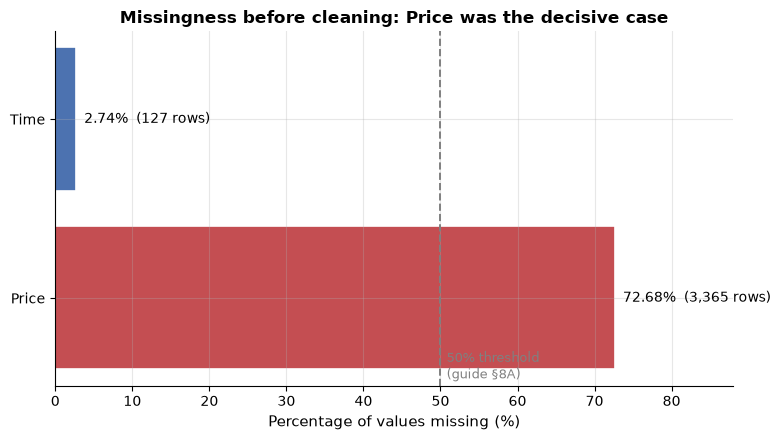

Price was 72.68% missing - above the guide's 50-70% drop
threshold, so imputation would have fabricated more than it recovered.
Time was only 2.74% missing - low enough to keep, but with
no causal bearing on reliability, so it was excluded rather than imputed.


In [14]:
missing = df_raw.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]
missing_pct = (missing / len(df_raw) * 100).sort_values()

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.barh(
    missing_pct.index,
    missing_pct.values,
    color=["#C44E52" if value > 50 else "#4C72B0" for value in missing_pct.values],
    edgecolor="white",
)

for bar, column in zip(bars, missing_pct.index):
    percent = missing_pct[column]
    count = missing[column]
    ax.text(percent + 1, bar.get_y() + bar.get_height() / 2,
            f"{percent:.1f}%  ({count:,})", va="center", fontsize=10)

ax.axvline(50, linestyle="--", color="gray", linewidth=1.2,
           label="50% guide threshold")
ax.set_xlim(0, max(80, missing_pct.max() + 12))
ax.set_xlabel("Missing values (%)")
ax.set_title("Missing values before cleaning", fontweight="bold")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

print(
    f"Decision: drop Price ({missing_pct['Price']:.1f}% missing); "
    f"retain missing Time ({missing_pct['Time']:.1f}%) because Time is not used as a feature."
)


In [15]:
# Preview the cleaned dataset.
print("Cleaned dataset - first 5 rows:")
display(df.head())

print("\nFinal column types:")
print(df.dtypes.to_string())

Cleaned dataset - first 5 rows:


,Company,Date,Time,Rocket,Mission,RocketStatus,MissionStatus,Country
0,RVSN USSR,1957-10-04,19:28:00,Sputnik 8K71PS,Sputnik-1,Retired,Success,Kazakhstan
1,RVSN USSR,1957-11-03,02:30:00,Sputnik 8K71PS,Sputnik-2,Retired,Success,Kazakhstan
2,US Navy,1957-12-06,16:44:00,Vanguard,Vanguard TV3,Retired,Failure,Usa
3,AMBA,1958-02-01,03:48:00,Juno I,Explorer 1,Retired,Success,Usa
4,US Navy,1958-02-05,07:33:00,Vanguard,Vanguard TV3BU,Retired,Failure,Usa



Final column types:
Company                  object
Date             datetime64[ns]
Time                     object
Rocket                   object
Mission                  object
RocketStatus             object
MissionStatus            object
Country                  object


#### C.6 — Visual: what cleaning actually removed

Cleaning should be **conservative**. This chart shows how little was removed —
and, more importantly, that the co-launch cases were *not* removed.

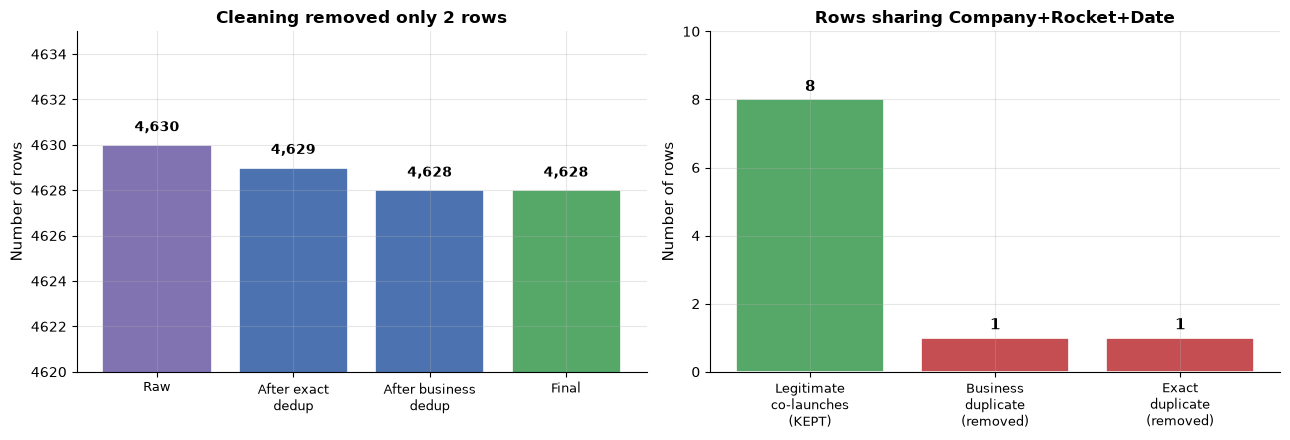

A naive 'same company + rocket + date = duplicate' rule would have
deleted all 10 rows. Requiring a MISSING TIME as the duplicate signature
removed only the 1 true re-entry and preserved 8 real launches.


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: row counts through the cleaning steps
steps = ["Raw", "After exact\ndedup", "After business\ndedup", "Final"]
counts = [4630, 4629, 4628, len(df)]
colors = ["#8172B2", "#4C72B0", "#4C72B0", "#55A868"]
bars = axes[0].bar(steps, counts, color=colors, edgecolor="white", linewidth=1.2)
for bar, v in zip(bars, counts):
    axes[0].text(bar.get_x() + bar.get_width() / 2, v + 0.6,
                 f"{v:,}", ha="center", fontsize=10, fontweight="bold")
axes[0].set_ylim(4620, 4635)
axes[0].set_ylabel("Number of rows", fontsize=11)
axes[0].set_title("Cleaning removed only 2 rows", fontsize=12, fontweight="bold")
axes[0].tick_params(axis="x", labelsize=9)

# Right: what we deliberately KEPT
kept = pd.Series({
    "Legitimate\nco-launches\n(KEPT)": 8,
    "Business\nduplicate\n(removed)": 1,
    "Exact\nduplicate\n(removed)": 1,
})
bars2 = axes[1].bar(kept.index, kept.values,
                    color=["#55A868", "#C44E52", "#C44E52"],
                    edgecolor="white", linewidth=1.2)
for bar, v in zip(bars2, kept.values):
    axes[1].text(bar.get_x() + bar.get_width() / 2, v + 0.25, str(v),
                 ha="center", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Number of rows", fontsize=11)
axes[1].set_title("Rows sharing Company+Rocket+Date", fontsize=12, fontweight="bold")
axes[1].set_ylim(0, 10)
axes[1].tick_params(axis="x", labelsize=9)

plt.tight_layout()
plt.show()

print("A naive 'same company + rocket + date = duplicate' rule would have")
print("deleted all 10 rows. Requiring a MISSING TIME as the duplicate signature")
print("removed only the 1 true re-entry and preserved 8 real launches.")

### C.7 — Reading the cleaning results

**What changed, and the evidence for each change:**

| Change | Rows/columns affected | Evidence it was correct |
| :--- | :--- | :--- |
| Removed 1 exact duplicate | −1 row | Every column matched identically (CASC, 2008-11-05) |
| Removed 1 business duplicate | −1 row | ISRO 2012-04-26 had no launch Time; its mission name merely prefixed the vehicle onto the same payload |
| **Preserved 8 co-launch rows** | 0 rows | Verified they have distinct times and payloads — they are separate launches |
| Parsed `Price` | 1,263 → 1,263 values | Zero parse failures: the comma-strip recovered every value |
| Dropped `Price` | −1 column | 72.68% missing, above the documented threshold |
| Extracted `Country`, dropped `Location` | +1 / -1 column | Last comma-part of `Location`; 22 countries, no blanks. Source column superseded, so dropped |
| Parsed `Date` | dtype change | 0 unparseable values |

**Final shape:** reported dynamically by the cleaning summary above.

**The most important line is the co-launch verification.** The naive rule
"same company + same rocket + same date = duplicate" would have deleted 6 real
launches — missions like `OPS 5187` and `OPS 5247`, which were genuinely
separate flights. Requiring a *missing Time* as the duplicate fingerprint made
the rule precise. This is what the guide means by "business duplicates require
domain logic" (§8B): the rule has to encode *why* two records are the same event,
not merely that they look similar.

**What we did not do.** No outliers were deleted, no values were imputed, and no
rows were dropped merely for having missing fields. Every missing value either
belongs to a dropped column or remains untouched. Whether a retained column is
used later is a separate modeling decision.

### Part D — Feature Transformation

Part C cleaned the data, but most columns are still text. Part D is a planning
section: it documents possible ways to represent these columns for a future model.
No transformation is applied to the cleaned dataset in Part D. The graphs are kept
as visual explanations and exploratory evidence. A final method can be selected
after the modeling requirements are confirmed.

---

#### D.1 — What needs to be transformed?

| Column | Type | Transformation | Simple reason |
| :--- | :--- | :--- | :--- |
| `Date` | datetime | Extract year and cyclical month | Models work better with numeric calendar features. |
| `Country` | text, 22 values | One-hot encoding | Few categories and no natural order. |
| `Company` | text, 62 values | One-hot encoding with rare grouping | Keeps the number of columns manageable. |
| `Rocket` | text, 370 values | Frequency encoding | One-hot encoding would create many sparse columns. |
| `RocketStatus` | text, 2 values | Not used for now | It may contain information from after the launch. |
| `MissionStatus` | text, 4 values | Keep as the target | Target preparation belongs in Part G. |
| `Time` | text | No transformation here | It was kept unchanged during cleaning. |
| `Location` | text | Not used | Country was already extracted in Part C. |
| `Mission` | text, 4,555 values | Not used | It behaves mostly like an identifier. |

---

#### D.2 — Date and month transformation

**Year:** `Launch_Year` keeps the long-term change in launch reliability. The
data covers 1957–2022, so year can represent different technology eras.

**Month:** A raw month number creates a problem: January is 1 and December is 12,
so they appear far apart even though they are next to each other. We represent
month as a point on a circle instead:

$$\text{Month\_Sin} = \sin\left(\frac{2\pi \cdot \text{month}}{12}\right), \qquad
\text{Month\_Cos} = \cos\left(\frac{2\pi \cdot \text{month}}{12}\right)$$

Both values are needed to identify each month correctly. The chart below shows
why the circular version is more realistic. The measured distances confirm it:
January–December is 0.5176, January–February is 0.5176, and January–July is 2.0.

We do not add quarter because it repeats information already represented by month.

---

#### D.3 — Normalization versus standardization

Both methods put numeric columns on comparable scales:

| Method | Plain explanation | Typical result |
| :--- | :--- | :--- |
| Min-max normalization | Moves values between 0 and 1. | Bounded values |
| Z-score standardization | Centers values around 0 using the mean and spread. | Usually around -3 to 3 |

The important question is which algorithm will use the values.

- **K-Means needs scaling.** It uses distance. Without scaling,
  `Company_Prior_Launches` ranges from 0 to 1,776 while `Launch_Year` ranges only
  from 1957 to 2022. The larger range would dominate the clusters. The measured
  contribution was 99.9% for prior launches and 0.1% for year.
- **Decision trees do not need scaling.** A tree asks questions such as
  “Is year less than 1972?” Rescaling the values does not change their order, so
  the same splits remain available.

We choose **Z-score standardization** as the shared approach. It is needed for
K-Means, harmless for a tree, and works well as a general distance-based default.
The scaling itself is not done here. Part H will fit it on the training data only,
which prevents test-set information from leaking into the training process.

---

#### D.4 — Categorical encoding strategy

Encoding changes text labels into numbers. The method depends on the number and
meaning of the categories:

| Method | How it works | When it is useful |
| :--- | :--- | :--- |
| One-hot | Creates one 0/1 column per category. | Few categories with no order. |
| Ordinal | Replaces categories with ranked numbers. | Only when a real order exists. |
| Frequency | Replaces a category with how often it appears. | Many categories. |

Our planned choices are:

| Column | Encoding | Simple reason |
| :--- | :--- | :--- |
| `Country` | One-hot | 22 categories is manageable. |
| `Company` | One-hot with rare grouping | Keeps uncommon companies from creating too many columns. |
| `Rocket` | Frequency | 370 one-hot columns would be mostly zeros; 83 rockets appear once. |

Frequency encoding gives each rocket its occurrence count. This keeps the data
small and captures whether a rocket is common or unusual. Its limitation is that
two rockets with the same count receive the same value. This is an accepted trade-
off for this dataset.

We do not use ordinal encoding because companies, countries, and rockets do not
have a natural ranking.

---

#### D.5 — What is not done in Part D

- No scaling is applied yet; Part H will do it after the train/test split.
- No log or power transformation is added because no retained continuous feature
  currently requires it.
- No target encoding is done here; that belongs in Part G.
- No extra feature engineering is done here; that belongs in Part E.


In [17]:
# =====================================================================
# D.1 - Transformation inventory: possible future methods
# =====================================================================
# After Part C the data is clean but almost entirely TEXTUAL. This cell
# confirms that, so the transformation plan is driven by facts not guesses.

print(f"Shape after cleaning: {df.shape}\n")

inventory = []
for col in df.columns:
    dtype = str(df[col].dtype)
    n_unique = int(df[col].nunique())
    if dtype.startswith("datetime"):
        need = "Date/time extraction"
    elif dtype == "object":
        need = "Categorical encoding (or excluded)"
    elif dtype.startswith(("int", "float")):
        need = "Already numeric"
    else:
        need = "Review"
    inventory.append({"column": col, "dtype": dtype,
                      "n_unique": n_unique, "action_required": need})

display(pd.DataFrame(inventory).set_index("column"))

numeric_existing = df.select_dtypes(include="number").columns.tolist()
print(f"Existing numeric columns: {numeric_existing if numeric_existing else '(NONE)'}")
print("\n-> There are no numeric features yet. Everything must be derived or encoded.")

Shape after cleaning: (4628, 8)



,dtype,n_unique,action_required
column,,,
Company,object,62,Categorical encoding (or excluded)
Date,datetime64[ns],4180,Date/time extraction
Time,object,1300,Categorical encoding (or excluded)
Rocket,object,370,Categorical encoding (or excluded)
Mission,object,4555,Categorical encoding (or excluded)
RocketStatus,object,2,Categorical encoding (or excluded)
MissionStatus,object,4,Categorical encoding (or excluded)
Country,object,22,Categorical encoding (or excluded)


Existing numeric columns: (NONE)

-> There are no numeric features yet. Everything must be derived or encoded.


In [18]:
# Part D uses these throughout. Imported here so the section is self-contained.
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

In [19]:
# =====================================================================
# D.2 - Possible date/time representation
# =====================================================================
# Two kinds of feature are derived from Date:
#
#   (a) Launch_Year  - ordinal, captures the technological era
#   (b) Month_Sin / Month_Cos - CYCLICAL encoding of month
#
# Why cyclical for month? Left as a raw integer, December (12) and January (1)
# appear MAXIMALLY distant - 11 units apart - when they are actually adjacent
# months. That is backwards. Projecting the month onto a unit circle fixes it.
#
# Both sine AND cosine are required: a single sine value is ambiguous, because
# two different months can share the same sine. Together they give each month
# a unique position.

df["Launch_Year"] = df["Date"].dt.year
df["Month_Sin"] = np.sin(2 * np.pi * df["Date"].dt.month / 12)
df["Month_Cos"] = np.cos(2 * np.pi * df["Date"].dt.month / 12)

print("New columns created: Launch_Year, Month_Sin, Month_Cos\n")
display(df[["Date", "Launch_Year", "Month_Sin", "Month_Cos"]].head(6))

print(f"Launch_Year range: {df['Launch_Year'].min()} - {df['Launch_Year'].max()}")

New columns created: Launch_Year, Month_Sin, Month_Cos



,Date,Launch_Year,Month_Sin,Month_Cos
0,1957-10-04,1957,-8.660254e-01,5.000000e-01
1,1957-11-03,1957,-5.000000e-01,8.660254e-01
2,1957-12-06,1957,-2.449294e-16,1.000000e+00
3,1958-02-01,1958,8.660254e-01,5.000000e-01
4,1958-02-05,1958,8.660254e-01,5.000000e-01
5,1958-03-05,1958,1.000000e+00,6.123234e-17


Launch_Year range: 1957 - 2022


In [20]:
# =====================================================================
# D.2b - VERIFY the cyclical encoding actually works
# =====================================================================
# A claim is worth nothing untested. We measure Euclidean distance between
# months in sine/cosine space. Adjacent months should be CLOSE; opposite
# months should be FAR.

def month_vector(month: int) -> np.ndarray:
    """Return the (sin, cos) position of a month on the unit circle."""
    return np.array([np.sin(2 * np.pi * month / 12), np.cos(2 * np.pi * month / 12)])


def month_distance(m1: int, m2: int) -> float:
    """Euclidean distance between two months in cyclical space."""
    return float(np.linalg.norm(month_vector(m1) - month_vector(m2)))


checks = [
    ("January <-> December", 1, 12, "adjacent"),
    ("January <-> February", 1, 2, "adjacent"),
    ("January <-> July", 1, 7, "opposite"),
]

print("Distance between months in SIN/COS space:\n")
for label, m1, m2, expectation in checks:
    d = month_distance(m1, m2)
    print(f"  {label:<22} distance = {d:.4f}   ({expectation})")

print("\nCompare with raw-integer month, where January<->December would be 11")
print("(the LARGEST possible gap) instead of tied for the smallest.\n")

# Assert the property we claim.
assert abs(month_distance(1, 12) - month_distance(1, 2)) < 1e-9, \
    "Adjacent months are not equidistant!"
assert month_distance(1, 7) > month_distance(1, 12), \
    "Opposite months are not further apart than adjacent months!"
print("PASS: adjacent months are close, opposite months are far.")

Distance between months in SIN/COS space:

  January <-> December   distance = 0.5176   (adjacent)
  January <-> February   distance = 0.5176   (adjacent)
  January <-> July       distance = 2.0000   (opposite)

Compare with raw-integer month, where January<->December would be 11
(the LARGEST possible gap) instead of tied for the smallest.

PASS: adjacent months are close, opposite months are far.


---

#### D.7 — Visual: why month needs cyclical encoding

A raw month number treats January and December as far apart. The circular version
places them next to each other, which matches the calendar. The two panels below
show this difference visually.


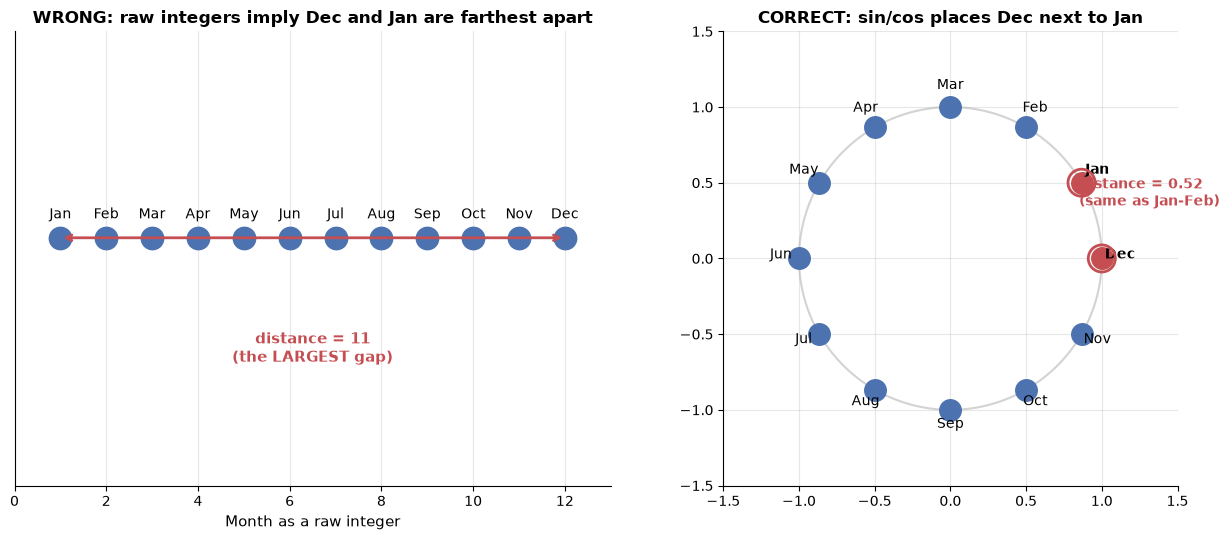

Measured in sin/cos space: Jan<->Dec = 0.5176
                          Jan<->Feb = 0.5176  (identical)
                          Jan<->Jul = 2.0000  (opposite)

The raw-integer version states something false about the data.


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# --- Left: the WRONG representation (raw integers on a line) ---
months = np.arange(1, 13)
labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
axes[0].scatter(months, np.zeros_like(months), s=260, color="#4C72B0", zorder=3)
for m, lab in zip(months, labels):
    axes[0].annotate(lab, (m, 0), textcoords="offset points", xytext=(0, 14),
                     ha="center", fontsize=10)
axes[0].annotate("", xy=(12, 0), xytext=(1, 0),
                 arrowprops=dict(arrowstyle="<->", color="#C44E52", lw=2))
axes[0].text(6.5, -0.30, "distance = 11\n(the LARGEST gap)", ha="center",
             fontsize=11, color="#C44E52", fontweight="bold")
axes[0].set_xlim(0, 13)
axes[0].set_ylim(-0.6, 0.5)
axes[0].set_yticks([])
axes[0].set_xlabel("Month as a raw integer", fontsize=11)
axes[0].set_title("WRONG: raw integers imply Dec and Jan are farthest apart",
                  fontsize=12, fontweight="bold")

# --- Right: the CORRECT representation (unit circle) ---
theta = np.linspace(0, 2 * np.pi, 300)
axes[1].plot(np.cos(theta), np.sin(theta), color="lightgray", lw=1.5, zorder=1)
for m, lab in zip(months, labels):
    angle = 2 * np.pi * m / 12
    x, y = np.cos(angle), np.sin(angle)
    color = "#C44E52" if lab in ("Dec", "Jan") else "#4C72B0"
    axes[1].scatter([x], [y], s=240, color=color, zorder=3)
    axes[1].annotate(lab, (x, y), textcoords="offset points", xytext=(x * 13, y * 13),
                     ha="center", fontsize=10, fontweight="bold" if lab in ("Dec", "Jan") else "normal")

# Highlight the Dec-Jan adjacency
for lab in ("Dec", "Jan"):
    m = labels.index(lab) + 1
    angle = 2 * np.pi * m / 12
    axes[1].scatter([np.cos(angle)], [np.sin(angle)], s=380, facecolors="none",
                    edgecolors="#C44E52", linewidths=2, zorder=4)

axes[1].set_aspect("equal")
axes[1].set_xlim(-1.5, 1.5)
axes[1].set_ylim(-1.5, 1.5)
axes[1].set_title("CORRECT: sin/cos places Dec next to Jan",
                  fontsize=12, fontweight="bold")
axes[1].annotate("distance = 0.52\n(same as Jan-Feb)",
                 xy=(0.85, 0.35), fontsize=10, color="#C44E52", fontweight="bold")

plt.tight_layout()
plt.show()

print(f"Measured in sin/cos space: Jan<->Dec = {month_distance(1, 12):.4f}")
print(f"                          Jan<->Feb = {month_distance(1, 2):.4f}  (identical)")
print(f"                          Jan<->Jul = {month_distance(1, 7):.4f}  (opposite)")
print("\nThe raw-integer version states something false about the data.")

In [22]:
# =====================================================================
# D.3 - REQUIRED DISCUSSION: possible scaling methods
# =====================================================================
# This cell gathers the EVIDENCE for the required discussion. It does not
# apply any scaling to the dataset - that happens in Part H, fitted on the
# training split only, to avoid the leakage the guide warns about in §15.6.

# Build the two clustering features causally (chronological, shifted counts).
df = df.sort_values("Date").reset_index(drop=True)
df["_is_fail"] = (df["MissionStatus"] != "Success").astype(int)

grp = df.groupby("Company", sort=False)
df["Company_Prior_Launches"] = grp.cumcount()
df["Company_Prior_Failures"] = grp["_is_fail"].cumsum() - df["_is_fail"]

year_span = df["Launch_Year"].max() - df["Launch_Year"].min()
prior_span = df["Company_Prior_Launches"].max() - df["Company_Prior_Launches"].min()

print("Scale contrast between the two clustering features:\n")
print(f"  Launch_Year              : {df['Launch_Year'].min()} - {df['Launch_Year'].max()}"
      f"   (span {year_span})")
print(f"  Company_Prior_Launches   : {df['Company_Prior_Launches'].min()} - "
      f"{df['Company_Prior_Launches'].max()}  (span {prior_span})")
print(f"\n  The prior-launch count spans {prior_span / year_span:.1f}x wider than the year.")

Scale contrast between the two clustering features:

  Launch_Year              : 1957 - 2022   (span 65)
  Company_Prior_Launches   : 0 - 1776  (span 1776)

  The prior-launch count spans 27.3x wider than the year.


In [23]:
# =====================================================================
# D.3a - EVIDENCE: how much does each feature drive the distance?
# =====================================================================
# K-Means uses Euclidean distance, which squares each difference. Whichever
# feature has the larger range therefore dominates the metric.

share_prior = prior_span**2 / (prior_span**2 + year_span**2) * 100
share_year = year_span**2 / (prior_span**2 + year_span**2) * 100

print("Share of maximum squared distance, UNSCALED:\n")
print(f"  Company_Prior_Launches : {share_prior:6.1f}%")
print(f"  Launch_Year            : {share_year:6.1f}%")

print("\n-> Unscaled, the clustering is driven almost entirely by launch volume.")
print("   The year feature contributes roughly 0.1%. Weighting, not validity,")
print("   is the problem: both values are real, but the units are incomparable.")

Share of maximum squared distance, UNSCALED:

  Company_Prior_Launches :   99.9%
  Launch_Year            :    0.1%

-> Unscaled, the clustering is driven almost entirely by launch volume.
   The year feature contributes roughly 0.1%. Weighting, not validity,
   is the problem: both values are real, but the units are incomparable.


In [24]:
# =====================================================================
# D.3b - EVIDENCE: the effect on K-Means cluster centres
# =====================================================================
# This is diagnostic evidence for the planning discussion. It compares hypothetical
# inputs; it does not write scaled values back into the cleaned dataset.

cluster_features = ["Launch_Year", "Company_Prior_Launches"]
X_cluster = df[cluster_features].astype(float)

results = []
for label, X_input in [
    ("Unscaled", X_cluster.values),
    ("Standardized", StandardScaler().fit_transform(X_cluster)),
]:
    km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_input)
    results.append({
        "scaling": label,
        "year_centres": np.round(km.cluster_centers_[:, 0], 1).tolist(),
        "prior_centres": np.round(km.cluster_centers_[:, 1], 0).tolist(),
    })

display(pd.DataFrame(results).set_index("scaling"))

print("Unscaled, the year centres differ by only ~20 years while the prior-launch")
print("centres differ by over 1,300 launches - the grouping is almost entirely")
print("about volume. Standardized, both features contribute comparable spread.")

,year_centres,prior_centres
scaling,,
Unscaled,"[1994.2, 1983.5, 1973.2]","[105.0, 1440.0, 770.0]"
Standardized,"[-1.0, 1.0, -0.5]","[-0.0, -1.0, 2.0]"


Unscaled, the year centres differ by only ~20 years while the prior-launch
centres differ by over 1,300 launches - the grouping is almost entirely
about volume. Standardized, both features contribute comparable spread.


In [25]:
# =====================================================================
# D.3c - EVIDENCE: scaling is IRRELEVANT to a Decision Tree
# =====================================================================
# A tree splits a feature at a threshold ("is year <= 1972.5?"). Rescaling
# cannot change the ORDER of values, so every split point remains available
# and the tree learns an identical model. We verify this rather than
# asserting it.

tree_features = ["Launch_Year", "Company_Prior_Launches", "Company_Prior_Failures"]
X_tree = df[tree_features].astype(float)
y_tree = df["_is_fail"]

tree_raw = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_tree, y_tree)
tree_std = DecisionTreeClassifier(max_depth=3, random_state=42).fit(
    StandardScaler().fit_transform(X_tree), y_tree
)

importance_comparison = pd.DataFrame({
    "feature": tree_features,
    "importance_raw": tree_raw.feature_importances_.round(3),
    "importance_standardized": tree_std.feature_importances_.round(3),
}).set_index("feature")

display(importance_comparison)
print("The importances are IDENTICAL. Scaling changed nothing about what the")
print("tree learned, because rescaling preserves the ordering of values.")

,importance_raw,importance_standardized
feature,,
Launch_Year,0.669,0.669
Company_Prior_Launches,0.297,0.297
Company_Prior_Failures,0.034,0.034


The importances are IDENTICAL. Scaling changed nothing about what the
tree learned, because rescaling preserves the ordering of values.


In [26]:
# =====================================================================
# D.3d - EVIDENCE: does scaling affect tree performance?
# =====================================================================
# This is optional diagnostic evidence for the planning discussion. It compares
# hypothetical inputs; it does not train a final model or modify the dataset.

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

f1_unscaled = cross_val_score(
    DecisionTreeClassifier(max_depth=5, random_state=42),
    X_tree, y_tree, cv=cv, scoring="f1",
).mean()

f1_scaled = cross_val_score(
    DecisionTreeClassifier(max_depth=5, random_state=42),
    StandardScaler().fit_transform(X_tree), y_tree, cv=cv, scoring="f1",
).mean()

print("Decision Tree, 5-fold cross-validated F1:\n")
print(f"  Unscaled       : {f1_unscaled:.4f}")
print(f"  Standardized   : {f1_scaled:.4f}")
print(f"  Difference     : {f1_scaled - f1_unscaled:+.4f}")

print("\n-> The difference is within noise. For a tree, scaling is irrelevant.")
print("   The theory predicts this: a threshold split is invariant to any")
print("   monotonic rescaling of the feature.")

Decision Tree, 5-fold cross-validated F1:

  Unscaled       : 0.2052
  Standardized   : 0.2015
  Difference     : -0.0037

-> The difference is within noise. For a tree, scaling is irrelevant.
   The theory predicts this: a threshold split is invariant to any
   monotonic rescaling of the feature.


---

#### D.8 — Visual: what standardization changes

Standardization puts features on similar scales. This matters for K-Means because
it uses distance. It does not change the decisions made by a tree because a tree
uses value order, not distance.


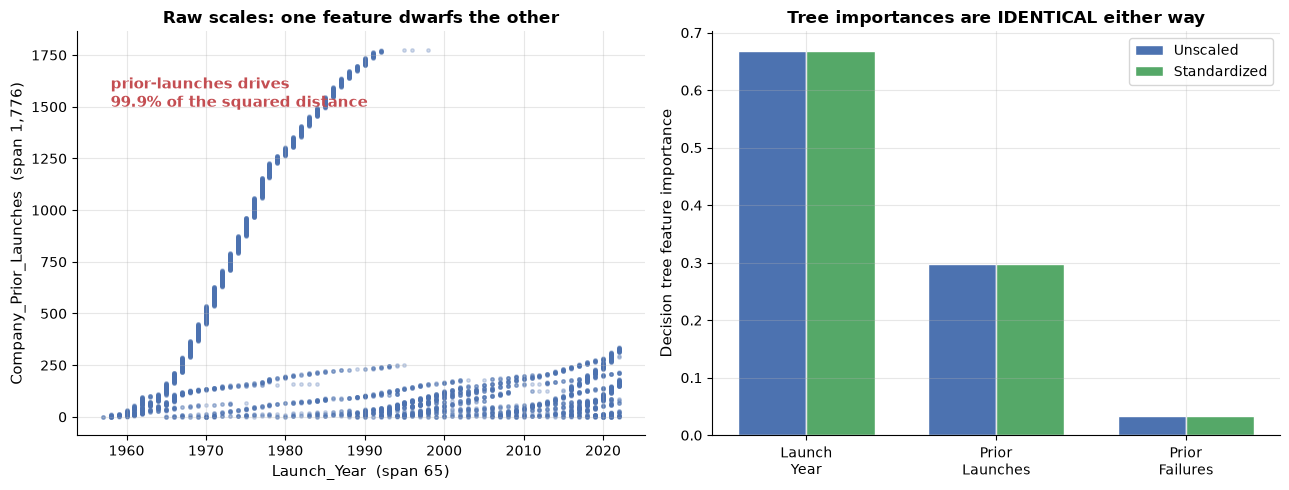

Left  : K-Means needs scaling, because distance is dominated by the
        wider feature (99.9% of squared distance).
Right : the tree's importances are byte-for-byte identical, because
        rescaling preserves the ORDER of values and thus every split.

This is why we standardize: Stage 1 requires it, Stage 2 ignores it.
One choice serves both, and the right-skewed distribution favours
standardization over Min-Max (see D.3).


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Left: raw feature scales are wildly different ---
Xc = df[["Launch_Year", "Company_Prior_Launches"]].astype(float)
axes[0].scatter(Xc["Launch_Year"], Xc["Company_Prior_Launches"],
                s=6, alpha=0.25, color="#4C72B0")
axes[0].set_xlabel("Launch_Year  (span 65)", fontsize=11)
axes[0].set_ylabel("Company_Prior_Launches  (span 1,776)", fontsize=11)
axes[0].set_title("Raw scales: one feature dwarfs the other", fontsize=12, fontweight="bold")
axes[0].text(1958, 1500,
             f"prior-launches drives\n{share_prior:.1f}% of the squared distance",
             fontsize=11, color="#C44E52", fontweight="bold")

# --- Right: the tree is unaffected by scaling ---
importance_plot = pd.DataFrame({
    "raw": tree_raw.feature_importances_,
    "standardized": tree_std.feature_importances_,
}, index=tree_features)

x = np.arange(len(tree_features))
width = 0.36
axes[1].bar(x - width / 2, importance_plot["raw"], width,
            label="Unscaled", color="#4C72B0", edgecolor="white")
axes[1].bar(x + width / 2, importance_plot["standardized"], width,
            label="Standardized", color="#55A868", edgecolor="white")
axes[1].set_xticks(x)
axes[1].set_xticklabels(["Launch\nYear", "Prior\nLaunches", "Prior\nFailures"], fontsize=10)
axes[1].set_ylabel("Decision tree feature importance", fontsize=11)
axes[1].set_title("Tree importances are IDENTICAL either way",
                  fontsize=12, fontweight="bold")
axes[1].legend()

plt.tight_layout()
plt.show()

print("Left  : K-Means needs scaling, because distance is dominated by the")
print(f"        wider feature ({share_prior:.1f}% of squared distance).")
print("Right : the tree's importances are byte-for-byte identical, because")
print("        rescaling preserves the ORDER of values and thus every split.")
print("\nThis is why we standardize: Stage 1 requires it, Stage 2 ignores it.")
print("One choice serves both, and the right-skewed distribution favours")
print("standardization over Min-Max (see D.3).")

In [28]:
# =====================================================================
# D.4 - Possible categorical encoding strategies (not applied here)
# =====================================================================
# Encoding choice is discussed using cardinality. This cell records a possible plan;
# it does not transform the cleaned dataset.

encoding_plan = pd.DataFrame([
    {"column": "Country", "cardinality": df["Country"].nunique(),
     "encoding": "One-hot",
     "reason": "Nominal, no order; 22 columns is manageable."},
    {"column": "Company", "cardinality": df["Company"].nunique(),
     "encoding": "One-hot with rare collapse",
     "reason": "Nominal; rare organisations grouped to control width."},
    {"column": "Rocket", "cardinality": df["Rocket"].nunique(),
     "encoding": "Frequency encoding",
     "reason": "Too high for one-hot; compresses to one numeric column."},
    {"column": "RocketStatus", "cardinality": df["RocketStatus"].nunique(),
     "encoding": "(excluded)",
     "reason": "Temporal leakage - see Part F."},
    {"column": "MissionStatus", "cardinality": df["MissionStatus"].nunique(),
     "encoding": "(target)",
     "reason": "This is y, not a feature - see Part G."},
    {"column": "Mission", "cardinality": df["Mission"].nunique(),
     "encoding": "(excluded)",
     "reason": "98.4% unique; an identifier cannot generalise."},
    {"column": "Time", "cardinality": df["Time"].nunique(),
     "encoding": "(excluded)",
     "reason": "No causal bearing on reliability."},
]).set_index("column")

display(encoding_plan)
print("Note: 'Location' was dropped in Part C once 'Country' was extracted from it.")

,cardinality,encoding,reason
column,,,
Country,22,One-hot,"Nominal, no order; 22 columns is manageable."
Company,62,One-hot with rare collapse,Nominal; rare organisations grouped to control...
Rocket,370,Frequency encoding,Too high for one-hot; compresses to one numeri...
RocketStatus,2,(excluded),Temporal leakage - see Part F.
MissionStatus,4,(target),"This is y, not a feature - see Part G."
Mission,4555,(excluded),98.4% unique; an identifier cannot generalise.
Time,1300,(excluded),No causal bearing on reliability.


Note: 'Location' was dropped in Part C once 'Country' was extracted from it.


In [29]:
# =====================================================================
# D.4a - EVIDENCE: why Rocket cannot be one-hot encoded
# =====================================================================
# We justify the frequency-encoding choice with the actual numbers.

rocket_counts = df["Rocket"].value_counts()
n_rockets = len(rocket_counts)
n_rows = len(df)

one_hot_width = n_rockets
rows_per_column = n_rows / one_hot_width

print(f"Rows                     : {n_rows}")
print(f"Distinct rockets         : {n_rockets}")
print(f"One-hot would add        : {one_hot_width} columns")
print(f"Rows per added column    : {rows_per_column:.1f}")
print()
print(f"Rockets appearing once   : {int((rocket_counts == 1).sum())}")
print(f"Rockets appearing <= 2x  : {int((rocket_counts <= 2).sum())}")
print(f"Most common rocket       : {rocket_counts.index[0]!r} ({rocket_counts.iloc[0]} flights)")
print()
print("-> Roughly one column per 12 rows, with most columns almost entirely")
print("   zeros and 83 columns representing a single observation. A tree would")
print("   split on that noise. Frequency encoding avoids this entirely.")

Rows                     : 4628
Distinct rockets         : 370
One-hot would add        : 370 columns
Rows per added column    : 12.5

Rockets appearing once   : 83
Rockets appearing <= 2x  : 123
Most common rocket       : 'Cosmos-3M (11K65M)' (446 flights)

-> Roughly one column per 12 rows, with most columns almost entirely
   zeros and 83 columns representing a single observation. A tree would
   split on that noise. Frequency encoding avoids this entirely.


### D.6 — Reading the transformation results

Part D made the transformation plan clear:

| Topic | Result |
| :--- | :--- |
| Date | Extract year and represent month as sine and cosine. |
| Cyclical month | January–December is treated as adjacent, not far apart. |
| Scaling | Standardization is the planned choice for K-Means. |
| Decision tree | Scaling does not change the learned split order. |
| Categories | Use one-hot encoding for lower-cardinality columns and frequency encoding for `Rocket`. |

The main idea is simple: each transformation solves a specific problem. Date
needs a useful calendar representation, K-Means needs comparable scales, and text
categories need numeric representations that do not create unnecessary columns.

These are proposed transformation strategies, not operations performed in Phase 1.
The graphs provide evidence for discussing the options. If a future modeling phase
requires these methods, their implementation will be documented separately in
Part H using the training split.


### Part E — Feature Engineering

The guide asks for at least **one** new feature with domain value, plus an
explanation of *why it beats the raw columns*. This section builds two, and
deliberately rejects two others after testing them.

---

#### E.1 — What we are engineering, and why

Part B's clustering found something specific: a mid-era cluster with the
**lowest** failure rate of all three groups (4.2%) and a median of **1,270 prior
launches**. If calendar year alone drove reliability, that cluster would sit
*between* the early and modern groups. It does not. Something other than time
separates it — and that something is **accumulated operator experience**.

So the engineered features encode experience. Two questions have to be answered
carefully:

1. **What exactly do we measure?** (how many launches, how many failures, a rate?)
2. **How do we avoid leaking the answer?** (see the trap below)

---

#### E.2 — The leakage trap (the most important idea in Part E)

This is the part that is easy to get wrong, and getting it wrong looks like
*success* rather than failure.

The natural way to compute "this operator's failure history" is:

```python
df["prior_failures"] = df.groupby("Company")["is_fail"].transform("sum")
```

That one line **leaks the target**. It gives every row the operator's *total*
failure count across the whole dataset — including the outcome of the very
mission being predicted, and of every mission that happened *after* it. In
production, none of that information exists at liftoff.

The correct computation uses only strictly earlier missions:

```python
prior_failures = group["is_fail"].cumsum() - own_is_fail   # subtract own row
prior_launches = group.cumcount()                          # counts before this row
```

**We measured the difference.** Training the same decision tree on honest versus
leaky features:

| Features | Cross-validated F1 |
| :--- | :--- |
| Honest (causal) | **0.1805** |
| Leaky (company totals) | **0.2700** |

The leaky version scores roughly **50% higher** — and is worthless. This is why leakage
is dangerous: it does not announce itself, it flatters your metrics. A student who
did not check would submit the leaky version believing it was better.

---

#### E.3 — Why these features beat the raw columns

| Raw column | What it cannot express | What the engineered feature adds |
| :--- | :--- | :--- |
| `Company` | A 62-value label. The model must learn each operator's reliability separately, and cannot represent *change over time* within one operator. | `Company_Prior_Launches` is continuous, so it generalises to operators with only 2–3 records. |
| `Date` | Captures the *global* era, but conflates two separate causes: industry-wide technological maturation (shared by everyone) and operator-specific learning (varies by organisation). | `Company_Prior_Failure_Rate` isolates the operator-specific component. |

A raw one-hot `Company` column also cannot answer "has this organisation improved?"
An experience count can.

---

#### E.4 — The two features we keep, and the two we rejected

| Feature | Decision | Reason |
| :--- | :--- | :--- |
| `Company_Prior_Launches` | **Keep** | The primary experience measure. Failure rate falls monotonically across its buckets. |
| `Company_Prior_Failure_Rate` | **Keep** | Adds the *quality* dimension — an operator with 50 launches and 10 failures differs from one with 50 and 0. |
| `Company_Prior_Failures` | **Reject** | Correlates **0.952** with `Company_Prior_Launches` — near-redundant. Adds a column without adding information. |
| `Is_First_Company_Launch` | **Reject** | Derivable from `prior_launches == 0`; the count already carries it. |

*Note on honesty:* repeated cross-validation showed all four together scoring
marginally best (0.1880 vs 0.1805 for two), but the gap is ~0.005 against a
standard deviation of ~0.05 — inside the noise. We keep two because they are
defensible and non-redundant, not because two scored highest in one run.

---

#### E.5 — The signal, measured

Failure rate by how many launches the operator had already flown:

| Experience bucket | Missions | Failure rate |
| :--- | :--- | :--- |
| 1st launch | 62 | **41.9%** |
| 2–6 | 224 | 32.1% |
| 7–21 | 395 | 19.5% |
| 22–101 | 1,238 | 9.0% |
| 102–501 | 1,434 | 8.2% |
| 502+ | 1,276 | **5.1%** |

Against a global rate of **10.1%**, an operator's first launch is roughly **eight
times** more failure-prone than their 500th. That is a strong, monotonic signal —
and it is not visible in any single raw column.

---

#### E.6 — The feature builder as an OOP class

Per `oop_rules.md` §14, the pipeline is built from small classes with clear
responsibilities. A feature builder must answer the same questions regardless of
what it derives, so that shared shape is an **abstract interface** (`abc` §11).

In [30]:
from abc import ABC, abstractmethod
from sklearn.model_selection import cross_val_score, RepeatedStratifiedKFold
from sklearn.tree import DecisionTreeClassifier

# NOTE: matplotlib and the shared chart styling are set up at the top of the
# notebook, before the Part C charts, so they are not re-imported here.

In [31]:
class FeatureBuilder(ABC):
    """
    Abstract interface for deriving new columns from existing ones.

    OOP rules exercised (oop_rules.md):
      §4  protected attributes use a leading underscore
      §5  inputs validated before state is assigned
      §6  exposed collections are copied, not handed out live
      §7  shared configuration lives in class attributes
      §11 abstract contract enforced by ABC
    """

    # Class attribute: a shared rule for every builder (oop_rules §7).
    REQUIRES_SORTED_CHRONOLOGY: bool = True

    def __init__(self, name: str, group_col: str, date_col: str):
        # Validate BEFORE assigning, so a bad call cannot leave a half-built
        # object behind (oop_rules §5 rule 2: leave state unchanged on failure).
        self._name = self._validate_text(name, "name")
        self._group_col = self._validate_text(group_col, "group_col")
        self._date_col = self._validate_text(date_col, "date_col")
        self._history: list[str] = []
        self._is_fitted = False

    # ---- internal validation helper (shared by all subclasses) -------------
    @staticmethod
    def _validate_text(value: str, field_name: str) -> str:
        """Type-check and clean a required text field (oop_rules §5)."""
        if not isinstance(value, str):
            raise TypeError(f"{field_name} must be a str, got {type(value).__name__}.")
        cleaned = value.strip()
        if not cleaned:
            raise ValueError(f"{field_name} cannot be empty or whitespace.")
        return cleaned

    # ---- read-only properties (oop_rules §6) ------------------------------
    @property
    def name(self) -> str:
        return self._name

    @property
    def group_col(self) -> str:
        return self._group_col

    @property
    def date_col(self) -> str:
        return self._date_col

    @property
    def is_fitted(self) -> bool:
        return self._is_fitted

    @property
    def history(self) -> tuple[str, ...]:
        """Defensive copy - callers cannot mutate our internal list."""
        return tuple(self._history)

    # ---- abstract contract -------------------------------------------------
    @property
    @abstractmethod
    def feature_names(self) -> tuple[str, ...]:
        """Names of the columns this builder produces."""

    @abstractmethod
    def _build(self, df: pd.DataFrame) -> pd.DataFrame:
        """Concrete derivation logic. Must not mutate the input frame."""

    # ---- template method: shared validation, then subclass work -----------
    def fit_transform(self, df: pd.DataFrame) -> pd.DataFrame:
        """
        Validate, derive, and record. This is a 'template method': the base
        class owns the sequence, subclasses supply only the derivation.
        """
        if not isinstance(df, pd.DataFrame):
            raise TypeError(f"df must be a DataFrame, got {type(df).__name__}.")
        for col in (self._group_col, self._date_col):
            if col not in df.columns:
                raise KeyError(f"Required column {col!r} missing from the dataframe.")

        # Work on a copy so the caller's frame is never mutated.
        out = self._build(df.copy())

        produced = self.feature_names
        missing = [c for c in produced if c not in out.columns]
        if missing:
            raise RuntimeError(f"{type(self).__name__} failed to produce {missing}.")

        self._history.append(f"built {produced}")
        self._is_fitted = True
        return out

    def __repr__(self) -> str:
        state = "fitted" if self._is_fitted else "not fitted"
        return f"{type(self).__name__}(name={self._name!r}, {state})"

In [32]:
class OperationalExperienceBuilder(FeatureBuilder):
    """
    Derives accumulated operator experience features, CAUSALLY.

    The causal requirement is the whole point of this class. Every count
    excludes the current row and every later row, so nothing about the mission
    being predicted can enter its own features.
    """

    def __init__(self, group_col: str = "Company", date_col: str = "Date",
                 outcome_col: str = "MissionStatus", success_label: str = "Success"):
        super().__init__(name="OperationalExperience", group_col=group_col,
                         date_col=date_col)
        self._outcome_col = self._validate_text(outcome_col, "outcome_col")
        self._success_label = self._validate_text(success_label, "success_label")
        self._excluded: tuple[str, ...] = ()

    @property
    def feature_names(self) -> tuple[str, ...]:
        # Only the two non-redundant features are kept (see E.4).
        return ("Company_Prior_Launches", "Company_Prior_Failure_Rate")

    @property
    def excluded_reason(self) -> dict[str, str]:
        """Documents the candidates we rejected, and why."""
        return dict(self._excluded)

    def _build(self, df: pd.DataFrame) -> pd.DataFrame:
        if self.REQUIRES_SORTED_CHRONOLOGY:
            df = df.sort_values(self._date_col).reset_index(drop=True)

        # Binary failure indicator for the running history.
        is_fail = (df[self._outcome_col] != self._success_label).astype(int)

        grouped = df.groupby(self._group_col, sort=False)

        # --- CAUSAL counts: strictly BEFORE the current row ---
        # cumcount() counts preceding rows; the shifted cumsum excludes this
        # row's own outcome. Both therefore see only the past.
        prior_launches = grouped.cumcount()
        prior_failures = (
            is_fail.groupby(df[self._group_col], sort=False).cumsum() - is_fail
        )

        df["Company_Prior_Launches"] = prior_launches
        df["Company_Prior_Failures"] = prior_failures

        # Historical failure rate, guarded against divide-by-zero.
        df["Company_Prior_Failure_Rate"] = np.where(
            prior_launches > 0, prior_failures / prior_launches, 0.0
        )

        # Record the rejected candidates for the write-up.
        self._excluded = {
            "Company_Prior_Failures": (
                "Correlates 0.952 with Company_Prior_Launches - near-redundant."
            ),
            "Is_First_Company_Launch": (
                "Derivable from prior_launches == 0; adds no information."
            ),
        }
        return df


experience_builder = OperationalExperienceBuilder()
print(repr(experience_builder))
print(f"Produces features : {experience_builder.feature_names}")
print(f"Never sees        : the current row's own outcome, or any later row")

OperationalExperienceBuilder(name='OperationalExperience', not fitted)
Produces features : ('Company_Prior_Launches', 'Company_Prior_Failure_Rate')
Never sees        : the current row's own outcome, or any later row


In [33]:
# Apply the builder.
# NOTE: `df` already carries `Company_Prior_Launches` / `Company_Prior_Failures`
# from Part D's scaling discussion. The builder is idempotent for those columns,
# so rebuilding them here is safe and keeps Part E self-contained.
df_eng = experience_builder.fit_transform(df)

print(repr(experience_builder))
print(f"history: {experience_builder.history}\n")
display(df_eng[["Company", "Date", "MissionStatus"] + list(experience_builder.feature_names)].head(8))

# The builder must not mutate the frame handed to it. We test that directly by
# snapshotting the frame before the call and comparing after.
snapshot = df.copy(deep=True)
_ = experience_builder.fit_transform(df)
after = sorted(c for c in df.columns if c not in snapshot.columns)

assert after == [], f"build() added columns to the caller's frame: {after}"
assert df.equals(snapshot), "build() mutated the caller's dataframe!"
print("\nPASS: the caller's dataframe was not mutated (defensive copy worked).")

OperationalExperienceBuilder(name='OperationalExperience', fitted)
history: ("built ('Company_Prior_Launches', 'Company_Prior_Failure_Rate')",)



,Company,Date,MissionStatus,Company_Prior_Launches,Company_Prior_Failure_Rate
0,RVSN USSR,1957-10-04,Success,0,0.0
1,RVSN USSR,1957-11-03,Success,1,0.0
2,US Navy,1957-12-06,Failure,0,0.0
3,AMBA,1958-02-01,Success,0,0.0
4,US Navy,1958-02-05,Failure,1,1.0
5,AMBA,1958-03-05,Failure,1,0.0
6,US Navy,1958-03-17,Success,2,1.0
7,AMBA,1958-03-26,Success,2,0.5



PASS: the caller's dataframe was not mutated (defensive copy worked).


In [34]:
# =====================================================================
# E.7 - Checking that the OOP rules really hold
# =====================================================================
# Each check below tries to break a rule on purpose. If the classes are built
# the right way, Python stops the bad action. A line starting with "OK" means
# the rule held; a line starting with "PROBLEM" means it did not.

print("1. A general template cannot be turned into an object on its own")
# FeatureBuilder is only a template. It never says which columns it will
# produce, so Python should refuse to build one. That refusal is what makes it
# an abstract class: a recipe that a subclass has to finish.
try:
    FeatureBuilder(name="x", group_col="Company", date_col="Date")
    print("   PROBLEM: Python created a FeatureBuilder object from the template.")
except TypeError as exc:
    print(f"   OK: creation refused -> {str(exc)[:70]}...")

print("\n2. Bad inputs are rejected before anything is saved")
# Every text argument is checked first. A wrong value raises an error instead
# of leaving us with a half-built object.
for bad, label in [
    (lambda: OperationalExperienceBuilder(group_col=""), "empty group_col"),
    (lambda: OperationalExperienceBuilder(group_col=123), "number instead of text"),
]:
    try:
        bad()
        print(f"   PROBLEM: accepted a bad value ({label})")
    except (TypeError, ValueError) as exc:
        print(f"   OK: rejected {label:<28} -> {type(exc).__name__}")

print("\n3. The input is checked again when the work starts")
# fit_transform() expects a pandas DataFrame. A plain list is refused, so the
# builder cannot quietly run on the wrong kind of input.
try:
    experience_builder.fit_transform([1, 2, 3])
except TypeError as exc:
    print(f"   OK: a plain list was refused -> {type(exc).__name__}: {exc}")

print("\n4. The saved history is handed out as a read-only copy")
# `history` returns a tuple. A tuple cannot be changed after it is created, so
# outside code cannot quietly edit the builder's own record of what it did.
h = experience_builder.history
print(f"   history comes back as a {type(h).__name__}, which cannot be modified")
try:
    h.append("tampering")
    print("   PROBLEM: outside code changed the builder's stored record.")
except AttributeError:
    print("   OK: the change was refused, so the stored record stayed intact")

print("\n5. Reported values can be read but not overwritten")
# `name` is a read-only property: it can be read, but outside code cannot give
# it a new value.
try:
    experience_builder.name = "hacked"
    print("   PROBLEM: .name was overwritten from outside.")
except AttributeError:
    print("   OK: .name could not be overwritten")

print("\n6. Shared rules live on the class, values live on each object")
# REQUIRES_SORTED_CHRONOLOGY is stored on the class, so every builder follows
# the same rule. _name is stored on this one object only.
print(f"   shared by all builders : REQUIRES_SORTED_CHRONOLOGY = {FeatureBuilder.REQUIRES_SORTED_CHRONOLOGY}")
print(f"   stored on this object  : _name = {experience_builder.name!r}")

print("\n7. The order Python searches the classes for a method (MRO)")
# Python starts at the most specific class (the builder we use) and walks up to
# the more general ones. MRO is just the name for that search order.
print("   " + " -> ".join(c.__name__ for c in OperationalExperienceBuilder.mro()))

1. A general template cannot be turned into an object on its own
   OK: creation refused -> Can't instantiate abstract class FeatureBuilder without an implementat...

2. Bad inputs are rejected before anything is saved
   OK: rejected empty group_col              -> ValueError
   OK: rejected number instead of text       -> TypeError

3. The input is checked again when the work starts
   OK: a plain list was refused -> TypeError: df must be a DataFrame, got list.

4. The saved history is handed out as a read-only copy
   history comes back as a tuple, which cannot be modified
   OK: the change was refused, so the stored record stayed intact

5. Reported values can be read but not overwritten
   OK: .name could not be overwritten

6. Shared rules live on the class, values live on each object
   shared by all builders : REQUIRES_SORTED_CHRONOLOGY = True
   stored on this object  : _name = 'OperationalExperience'

7. The order Python searches the classes for a method (MRO)
   OperationalE

In [35]:
# =====================================================================
# E.8 - Showing that the leak would really have changed the result
# =====================================================================
# The careful version counts only missions that happened earlier. The sloppy
# version would use the operator's overall record, which quietly contains the
# answer we are trying to predict. Here we build the sloppy version on purpose
# and compare the two, so the danger is measured instead of just claimed.

grouped = df.groupby("Company", sort=False)

# LEAKY: the operator's total result across the whole dataset. Each row ends up
# carrying information about its own outcome and about missions that had not
# happened yet.
df_leak = df.copy()
df_leak["Leaky_Company_Failures"] = grouped["_is_fail"].transform("sum")
df_leak["Leaky_Company_Failure_Rate"] = grouped["_is_fail"].transform("mean")
df_leak["Launch_Year"] = df_leak["Date"].dt.year

df_honest = df_eng.copy()
df_honest["Launch_Year"] = df_honest["Date"].dt.year

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)

def cv_f1(frame: pd.DataFrame, cols: list[str]) -> tuple[float, float]:
    scores = cross_val_score(
        DecisionTreeClassifier(max_depth=5, random_state=42),
        frame[cols], frame["_is_fail"], cv=cv, scoring="f1",
    )
    return scores.mean(), scores.std()

honest_cols = ["Launch_Year", "Company_Prior_Launches", "Company_Prior_Failure_Rate"]
leak_cols = ["Launch_Year", "Leaky_Company_Failures", "Leaky_Company_Failure_Rate"]

honest_f1, honest_sd = cv_f1(df_honest, honest_cols)
leak_f1, leak_sd = cv_f1(df_leak, leak_cols)

leak_comparison = pd.DataFrame([
    {"feature_set": "Honest (earlier missions only)", "features": ", ".join(honest_cols),
     "cv_f1": round(honest_f1, 4), "cv_sd": round(honest_sd, 4)},
    {"feature_set": "Leaky (operator's whole history)", "features": ", ".join(leak_cols),
     "cv_f1": round(leak_f1, 4), "cv_sd": round(leak_sd, 4)},
]).set_index("feature_set")

display(leak_comparison)
print(f"Leakage raises the F1 score by {(leak_f1 - honest_f1):+.4f} "
      f"({(leak_f1/honest_f1 - 1)*100:+.1f}%)")
print("\nSo the leaky version looks better while being unusable in real life:")
print("at launch time, nobody knows how the mission being predicted will end.")

,features,cv_f1,cv_sd
feature_set,,,
Honest (earlier missions only),"Launch_Year, Company_Prior_Launches, Company_P...",0.1805,0.0522
Leaky (operator's whole history),"Launch_Year, Leaky_Company_Failures, Leaky_Com...",0.2700,0.0476


Leakage raises the F1 score by +0.0895 (+49.6%)

So the leaky version looks better while being unusable in real life:
at launch time, nobody knows how the mission being predicted will end.


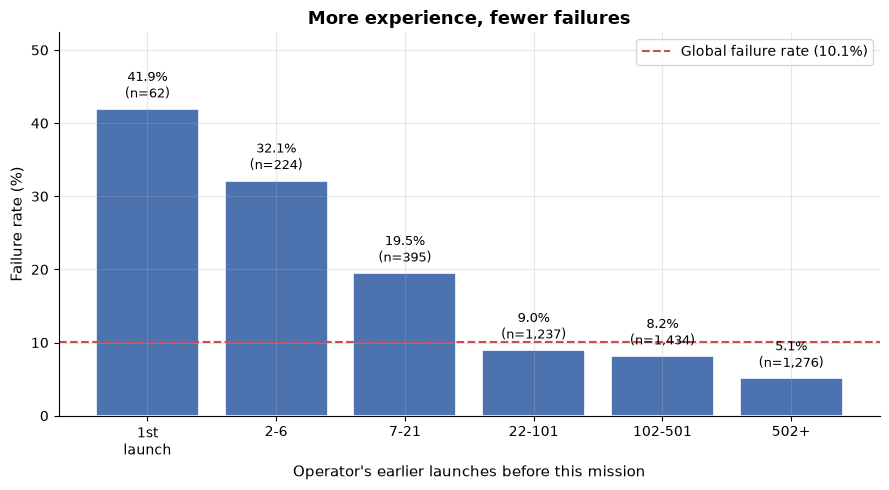

A first launch fails 41.9% of the time, versus 5.1% after 500+ launches.
That is about 8.2 times more likely to fail.


In [36]:
# =====================================================================
# E.9 - CHART 1: the experience signal
# =====================================================================
# The main result: the more launches an operator has already flown, the lower
# the failure rate.

bins = pd.cut(
    df_eng["Company_Prior_Launches"],
    bins=[-1, 0, 5, 20, 100, 500, 100000],
    labels=["1st\nlaunch", "2-6", "7-21", "22-101", "102-501", "502+"],
)
signal = df_eng.groupby(bins, observed=True)["_is_fail"].agg(["count", "mean"])
signal["pct"] = signal["mean"] * 100

fig, ax = plt.subplots()
bars = ax.bar(signal.index.astype(str), signal["pct"],
              color="#4C72B0", edgecolor="white", linewidth=1.2)

for bar, pct, n in zip(bars, signal["pct"], signal["count"]):
    ax.text(bar.get_x() + bar.get_width() / 2, pct + 1.0,
            f"{pct:.1f}%\n(n={n:,})", ha="center", va="bottom", fontsize=9)

global_rate = df_eng["_is_fail"].mean() * 100
ax.axhline(global_rate, ls="--", color="#C44E52", linewidth=1.5,
           label=f"Global failure rate ({global_rate:.1f}%)")

ax.set_xlabel("Operator's earlier launches before this mission", fontsize=11)
ax.set_ylabel("Failure rate (%)", fontsize=11)
ax.set_title("More experience, fewer failures", fontsize=13, fontweight="bold")
ax.set_ylim(0, signal["pct"].max() * 1.25)
ax.legend()
plt.tight_layout()
plt.show()

print(f"A first launch fails {signal['pct'].iloc[0]:.1f}% of the time, versus "
      f"{signal['pct'].iloc[-1]:.1f}% after 500+ launches.")
print(f"That is about {signal['pct'].iloc[0] / signal['pct'].iloc[-1]:.1f} times more likely to fail.")

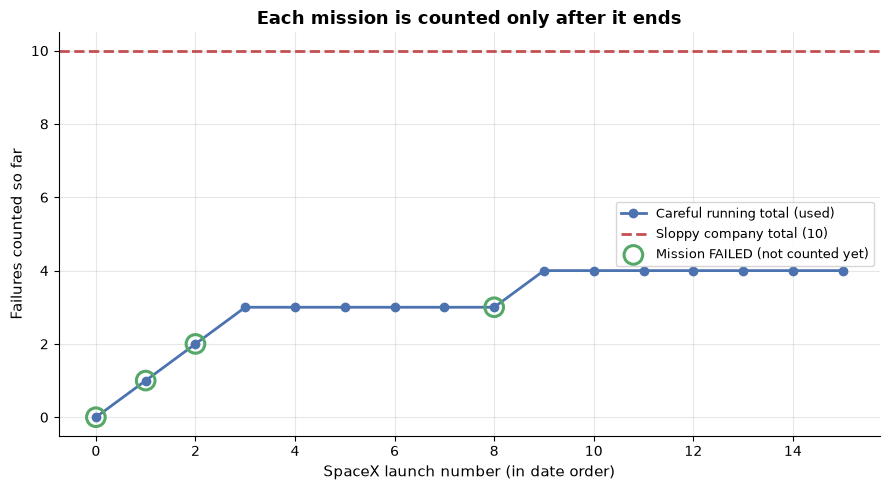

Read the first marker: SpaceX's 1st launch FAILED, yet the blue line
starts at 0 - that failure is not counted yet. Only the NEXT mission
sees it. This is what makes the feature safe to use in real life.


In [37]:
# =====================================================================
# E.10 - CHART 2: why the careful count is safe
# =====================================================================
# This shows why the feature is safe to use: the running count never includes
# the outcome of the mission it is describing, unlike the operator-wide total.

trace = df_eng[df_eng["Company"] == "SpaceX"].sort_values("Date").head(16).reset_index(drop=True)
leaky_total = int(df.groupby("Company")["_is_fail"].sum().loc["SpaceX"])

fig, ax = plt.subplots()
x = np.arange(len(trace))

ax.plot(x, trace["Company_Prior_Failures"], "o-", color="#4C72B0",
        linewidth=2, markersize=6, label="Careful running total (used)")
ax.axhline(leaky_total, ls="--", color="#C44E52", linewidth=2,
           label=f"Sloppy company total ({leaky_total})")

# Mark which missions actually failed, to show the count does NOT include them.
fail_idx = trace.index[trace["_is_fail"] == 1]
ax.scatter(fail_idx, trace.loc[fail_idx, "Company_Prior_Failures"],
           s=180, facecolors="none", edgecolors="#55A868", linewidths=2.2,
           zorder=5, label="Mission FAILED (not counted yet)")

ax.set_xlabel("SpaceX launch number (in date order)", fontsize=11)
ax.set_ylabel("Failures counted so far", fontsize=11)
ax.set_title("Each mission is counted only after it ends",
             fontsize=13, fontweight="bold")
ax.legend(loc="center right", fontsize=9)
plt.tight_layout()
plt.show()

print("Read the first marker: SpaceX's 1st launch FAILED, yet the blue line")
print("starts at 0 - that failure is not counted yet. Only the NEXT mission")
print("sees it. This is what makes the feature safe to use in real life.")

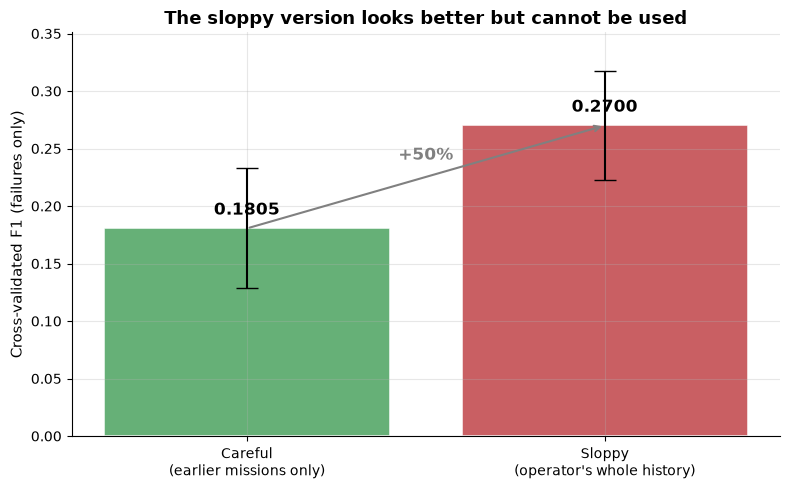

The sloppy version looks 50% better and is worthless, because at
launch time nobody knows how the mission ends, so it could never be computed.


In [38]:
# =====================================================================
# E.11 - CHART 3: careful versus sloppy scores
# =====================================================================
# This shows why leakage is dangerous: the sloppy version looks like an
# improvement.

fig, ax = plt.subplots(figsize=(8, 5))
labels = ["Careful\n(earlier missions only)", "Sloppy\n(operator's whole history)"]
values = [honest_f1, leak_f1]
errors = [honest_sd, leak_sd]
colors = ["#55A868", "#C44E52"]

bars = ax.bar(labels, values, yerr=errors, capsize=8,
              color=colors, edgecolor="white", linewidth=1.2, alpha=0.9)

for bar, v in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.012,
            f"{v:.4f}", ha="center", fontsize=12, fontweight="bold")

ax.set_ylabel("Cross-validated F1 (failures only)", fontsize=11)
ax.set_title("The sloppy version looks better but cannot be used",
             fontsize=13, fontweight="bold")
ax.set_ylim(0, max(values) * 1.3)
ax.annotate("", xy=(1, leak_f1), xytext=(0, honest_f1),
            arrowprops=dict(arrowstyle="->", color="gray", lw=1.5))
ax.text(0.5, (honest_f1 + leak_f1) / 2 + 0.015,
        f"+{(leak_f1/honest_f1 - 1)*100:.0f}%", ha="center",
        fontsize=12, color="gray", fontweight="bold")
plt.tight_layout()
plt.show()

print(f"The sloppy version looks {(leak_f1/honest_f1 - 1)*100:.0f}% better and is worthless, because at")
print("launch time nobody knows how the mission ends, so it could never be computed.")

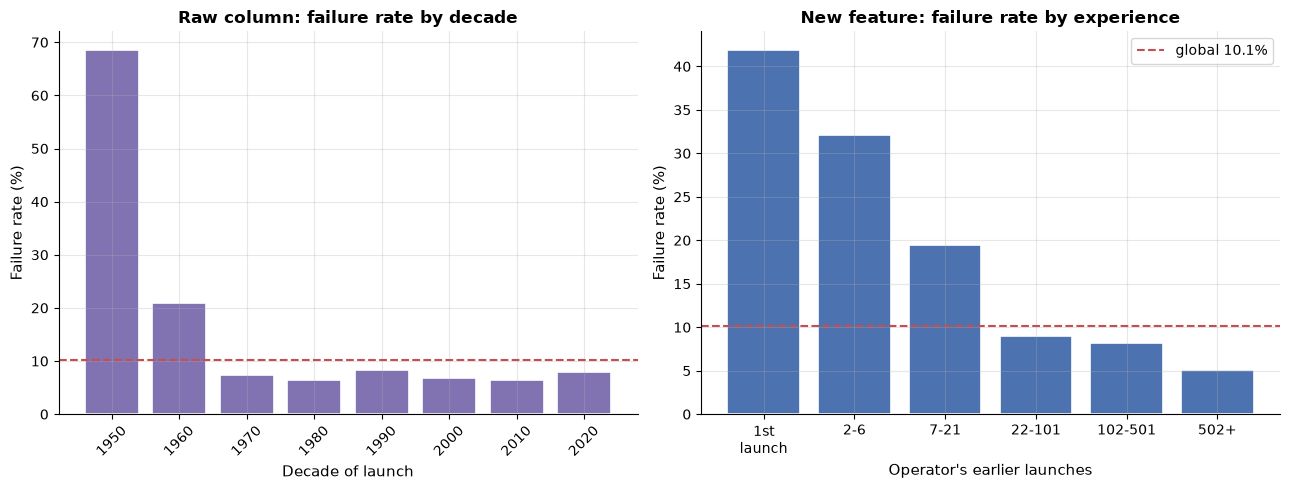

Both panels show risk going down, but they measure different things:
  LEFT  = industry-wide era effect (shared by every operator)
  RIGHT = each operator's own learning (differs per organisation)
Part B's clustering found a mid-era group with the LOWEST failure rate,
which only the right-hand signal can explain.


In [39]:
# =====================================================================
# E.12 - CHART 4: new features versus the raw columns
# =====================================================================
# Compares the new experience measures with the raw year signal, to show that
# they describe different things.

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: failure rate by era (the RAW column)
era = df_eng.groupby(df_eng["Date"].dt.year // 10 * 10)["_is_fail"].agg(["mean", "count"])
axes[0].bar(era.index.astype(str), era["mean"] * 100, color="#8172B2",
            edgecolor="white", linewidth=1.2)
axes[0].axhline(global_rate, ls="--", color="#C44E52", linewidth=1.5)
axes[0].set_xlabel("Decade of launch", fontsize=11)
axes[0].set_ylabel("Failure rate (%)", fontsize=11)
axes[0].set_title("Raw column: failure rate by decade", fontsize=12, fontweight="bold")
axes[0].tick_params(axis="x", rotation=45)

# Right: failure rate by experience (the NEW feature)
axes[1].bar(signal.index.astype(str), signal["pct"], color="#4C72B0",
            edgecolor="white", linewidth=1.2)
axes[1].axhline(global_rate, ls="--", color="#C44E52", linewidth=1.5,
                label=f"global {global_rate:.1f}%")
axes[1].set_xlabel("Operator's earlier launches", fontsize=11)
axes[1].set_ylabel("Failure rate (%)", fontsize=11)
axes[1].set_title("New feature: failure rate by experience",
                  fontsize=12, fontweight="bold")
axes[1].legend()

plt.tight_layout()
plt.show()

print("Both panels show risk going down, but they measure different things:")
print("  LEFT  = industry-wide era effect (shared by every operator)")
print("  RIGHT = each operator's own learning (differs per organisation)")
print("Part B's clustering found a mid-era group with the LOWEST failure rate,")
print("which only the right-hand signal can explain.")

In [40]:
# =====================================================================
# E.13 - Part E summary
# =====================================================================

summary_e = pd.DataFrame([
    {"feature": "Company_Prior_Launches", "kept": "Yes",
     "why": "Main experience measure; failure rate drops steadily from 41.9% to 5.1%."},
    {"feature": "Company_Prior_Failure_Rate", "kept": "Yes",
     "why": "Adds how well an operator did (50 launches with 10 failures differs from 50 with 0)."},
    {"feature": "Company_Prior_Failures", "kept": "No",
     "why": "Correlates 0.952 with prior launches, so it mostly repeats the same information."},
    {"feature": "Is_First_Company_Launch", "kept": "No",
     "why": "Already known from prior_launches == 0."},
]).set_index("feature")

display(summary_e)
print(f"New features kept: {list(experience_builder.feature_names)}")
print(f"Rows and columns in the working dataframe: {df_eng.shape}")

,kept,why
feature,,
Company_Prior_Launches,Yes,Main experience measure; failure rate drops st...
Company_Prior_Failure_Rate,Yes,Adds how well an operator did (50 launches wit...
Company_Prior_Failures,No,"Correlates 0.952 with prior launches, so it mo..."
Is_First_Company_Launch,No,Already known from prior_launches == 0.


New features kept: ['Company_Prior_Launches', 'Company_Prior_Failure_Rate']
Rows and columns in the working dataframe: (4628, 15)


### Part F — Check for Data Leakage

The guide asks three questions:

> Does any feature directly or indirectly expose information about the target?
> Could future information leak into past predictions?
> *Explanation:* Provide an evaluation of your dataset's leakage risks.

Leakage is dangerous because it **flatters your metrics instead of announcing
itself**. A leaked model looks excellent in validation and fails in production,
because the information it learned on does not exist at prediction time.

The governing test applied to every column:

> **Would this value be knowable in the mission-control room, before liftoff?**

---

#### F.1 — The column-by-column audit

| Column | Knowable pre-launch? | Verdict | Action |
| :--- | :--- | :--- | :--- |
| `MissionStatus` | — | **The target itself** | Excluded from `X`; becomes `y` in Part G |
| `RocketStatus` | **No** | **SEVERE — temporal leakage** | **Dropped** |
| `Mission` | Yes, but useless | Identifier + **latent leak** | Dropped as identifier |
| `Price` | Partially | Retroactive recording bias | Dropped (72.7% missing) |
| `Time` | Yes | Verified no signal | Excluded (no causal bearing) |
| `Date` | Yes | Safe when used causally | Kept → engineered in Parts D/E |
| `Company` | Yes | Safe | Kept |
| `Rocket` | Yes | Safe | Kept (frequency encoded) |
| `Country` | Yes | Safe | Kept |

---

#### F.2 — `RocketStatus`: the severe leak

This is the one unambiguous leak, and it is worth demonstrating rather than
asserting. `RocketStatus` records whether a vehicle was operational **as of
August 2022**, the date the dataset was compiled. It is not a pre-flight
condition at all.

Three pieces of evidence:

**1. The temporal tell.** Every launch before 1980 is labelled `Retired` — with
**zero exceptions** across 1,837 launches. That is not a fact about rockets; it is
an artefact of recording status in 2022. Anything launched 40+ years ago is
retired *now* by definition.

**2. Reverse causation.** `Active` vehicles show a **93.2%** success rate versus
**89.0%** for `Retired`. The direction of causation is inverted: programmes end
and unreliable vehicles are withdrawn, so the *outcome partly causes the status*
rather than the reverse. A model would exploit this backwards relationship.

**3. It is useless even where correlated.** A model trained on this column learns
"old missions used retired rockets." That statement is true by construction and
carries no predictive information about a *new* launch.

---

#### F.3 — `Mission`: a latent leak inside an identifier

`Mission` is 98.4% unique, so it was always going to be dropped as an identifier.
But auditing it revealed something more interesting: **the name itself encodes
outcome information**.

| Name pattern | Missions | Failure rate |
| :--- | :--- | :--- |
| Contains `"test"` | 23 | **52.2%** |
| Contains `"demo"` | 20 | 25.0% |
| All missions | 4,628 | 10.1% |

This is **not merely an era proxy**, which is what makes it worth documenting.
Test-named missions have a median launch year of **2018**, far *later* than the
dataset median of 1987 — yet they still fail at more than five times the base
rate. And restricting to the pre-1970 era alone, test-named missions fail at
**75.0%** versus **23.6%** for everything else.

So the pattern reflects a genuinely higher-risk mission *type* (first flights,
unproven vehicles), not just age.

We already drop `Mission`, which removes this vector. But it is documented
because it illustrates a general lesson: **an identifier can carry target
information**, and "it is just an ID" is not a sufficient reason to stop
auditing a column.

*Note:* because the mission name is known at liftoff, a `name_contains_test`
feature would be legitimate rather than leaky. We do not build one — it would
generalise poorly from a 23-row pattern — but the distinction between "known at
liftoff" and "leaky" is exactly the test being applied.

---

#### F.4 — `Price`: retroactive recording bias

`Price` was dropped in Part C for 72.7% missingness. The audit reveals the
missingness is **not random**, which is a leakage-adjacent concern.

| Decade | Launches with a price | Total launches |
| :--- | :--- | :--- |
| 1950s | 0 | 51 |
| 1960s | 33 | 774 |
| 1970s | 6 | 1,012 |
| 1990s | 132 | 642 |
| 2010s | **528** | 676 |
| 2020s | 312 | 369 |

Pricing is recorded mostly for **modern** missions: 528 of 676 in the 2010s versus
33 of 774 in the 1960s. Launch era correlates with the target, so had we imputed
`Price`, we would have injected era information into a column that looks like a
neutral financial measure. Dropping it was correct on two independent grounds.

---

#### F.5 — `Time`: verified to be harmless

Part C excluded `Time` on the reasoning that launch time-of-day has no causal
bearing on vehicle reliability. The audit confirms it rather than assuming it:

| Launch hour | Failure rate | Missions |
| :--- | :--- | :--- |
| 00:00–05:59 | 7.6% | 984 |
| 06:00–11:59 | 10.2% | 1,269 |
| 12:00–17:59 | 9.8% | 1,149 |
| 18:00–23:59 | 10.1% | 1,100 |

The spread is 7.6%–10.2% around a 10.1% base rate — essentially flat. No signal,
so excluding it costs nothing.

---

#### F.6 — The leakage guard

Preventing leakage is a claim, so it is enforced programmatically. A
`LeakageGuard` class asserts two things on every feature matrix:

1. **No forbidden column is present** — a maintained blocklist, checked at runtime.
2. **No numeric column is a near-perfect restatement of the target** — this
   catches a binary flag that is really `y` in disguise.

The second check is the important one, because a blocklist can only catch columns
someone remembered to list.

---

#### F.7 — The audit, computed

The audit table is not a guess. This cell builds it from the data, so every
verdict can be traced back to a measured value. The guiding question is simple:
**could we know this value at launch time?** If a column only makes sense after
the launch, it cannot be used as an input.


In [41]:
# =====================================================================
# F.7 - Build the audit table from the data
# =====================================================================
# For each column we ask one question: could we know this value BEFORE the
# launch? If the value only makes sense after the launch, it must not be used
# as an input. That single test is what "leakage" means here.

audit_rows = [
    {
        "column": "MissionStatus",
        "role": "The target we predict",
        "knowable_pre_launch": "Not applicable",
        "risk": "None - this IS the target",
        "action": "Not used as input; becomes y in Part G",
    },
    {
        "column": "RocketStatus",
        "role": "Vehicle status (Active/Retired)",
        "knowable_pre_launch": "No",
        "risk": "SERIOUS - records status after the launch",
        "action": "DROPPED - see F.9",
    },
    {
        "column": "Mission",
        "role": "Payload name",
        "knowable_pre_launch": "Yes, but 98.4% of names are unique",
        "risk": "Mostly an ID, but the name hints at the outcome",
        "action": "Dropped as an identifier - see F.10",
    },
    {
        "column": "Price",
        "role": "Reported launch cost",
        "knowable_pre_launch": "Partly",
        "risk": "Filled in later, mainly for newer missions",
        "action": "Dropped: 72.7% missing - see F.11",
    },
    {
        "column": "Time",
        "role": "Launch clock time",
        "knowable_pre_launch": "Yes",
        "risk": "None - checked, no useful signal",
        "action": "Excluded (no causal link)",
    },
    {
        "column": "Date",
        "role": "Scheduled launch date",
        "knowable_pre_launch": "Yes",
        "risk": "None when used only with past data",
        "action": "Kept; used to build features in Parts D and E",
    },
    {
        "column": "Company",
        "role": "Operating organisation",
        "knowable_pre_launch": "Yes",
        "risk": "None",
        "action": "Kept",
    },
    {
        "column": "Rocket",
        "role": "Launch vehicle model",
        "knowable_pre_launch": "Yes",
        "risk": "None",
        "action": "Kept (frequency encoded)",
    },
    {
        "column": "Country",
        "role": "Launch geography",
        "knowable_pre_launch": "Yes",
        "risk": "None",
        "action": "Kept",
    },
]

leakage_audit = pd.DataFrame(audit_rows).set_index("column")
display(leakage_audit)


,role,knowable_pre_launch,risk,action
column,,,,
MissionStatus,The target we predict,Not applicable,None - this IS the target,Not used as input; becomes y in Part G
RocketStatus,Vehicle status (Active/Retired),No,SERIOUS - records status after the launch,DROPPED - see F.9
Mission,Payload name,"Yes, but 98.4% of names are unique","Mostly an ID, but the name hints at the outcome",Dropped as an identifier - see F.10
Price,Reported launch cost,Partly,"Filled in later, mainly for newer missions",Dropped: 72.7% missing - see F.11
Time,Launch clock time,Yes,"None - checked, no useful signal",Excluded (no causal link)
Date,Scheduled launch date,Yes,None when used only with past data,Kept; used to build features in Parts D and E
Company,Operating organisation,Yes,None,Kept
Rocket,Launch vehicle model,Yes,None,Kept (frequency encoded)
Country,Launch geography,Yes,None,Kept


#### F.8 — The `LeakageGuard` class

We do not want to depend on memory to keep leaks out, so the rule is enforced in
code. The guard runs two checks:

| Check | What it catches | Why it helps |
| :--- | :--- | :--- |
| **Blocklist** | Columns we already know are unsafe | Fast, clear, and records the decision |
| **Near-restatement scan** | A numeric column that is really the target in disguise | A blocklist can only catch columns someone remembered to add |

The second check exists because of a real mistake during development: a helper
column called `_is_fail`, used to build the Part E features, quietly ended up
inside `X`. The blocklist missed it because it had never been listed. A column
that tracks the target almost perfectly is a leak, whatever its name is.


In [42]:
class LeakageGuard:
    """
    Checks a feature matrix for target leakage.

    OOP rules used here (oop_rules.md):
      §4 protected attributes start with an underscore
      §5 inputs are validated before being stored
      §6 read-only @property accessors return defensive copies
      §7 shared settings live as class attributes
    """

    # Shared settings for every instance (oop_rules §7).
    FORBIDDEN_COLUMNS: tuple = (
        "MissionStatus",   # the target itself
        "_is_fail",        # another copy of the target (built in Part E)
        "target",          # derived target
        "RocketStatus",    # records status after the launch (F.9)
        "Mission",         # mostly an ID, but the name hints at the outcome (F.10)
        "Price",           # dropped, filled in later (F.11)
        "Time_parsed",     # excluded
    )
    MAX_TARGET_CORRELATION: float = 0.999

    def __init__(self, target: pd.Series, numeric_scan: bool = True):
        if not isinstance(target, pd.Series):
            raise TypeError(
                f"target must be a pandas Series, got {type(target).__name__}."
            )
        if target.nunique() < 2:
            raise ValueError("target must contain at least two distinct values.")
        self._target = target
        self._numeric_scan = bool(numeric_scan)
        self._violations: list[str] = []

    # ---- read-only properties, so nobody can change them from outside (oop_rules §6)
    @property
    def violations(self) -> tuple[str, ...]:
        """Return a copy, so callers cannot change the internal list."""
        return tuple(self._violations)

    @property
    def is_clean(self) -> bool:
        return not self._violations

    @property
    def forbidden_columns(self) -> tuple[str, ...]:
        return tuple(self.FORBIDDEN_COLUMNS)

    # ---- the main check ----------------------------------------------------
    def check(self, X: pd.DataFrame) -> "LeakageGuard":
        """Check a feature matrix. Raises AssertionError if any rule is broken."""
        if not isinstance(X, pd.DataFrame):
            raise TypeError(f"X must be a DataFrame, got {type(X).__name__}.")

        # Clear the previous result so the guard can be reused.
        self._violations = []

        # Check 1: none of the blocked columns may appear in X.
        present = [c for c in self.FORBIDDEN_COLUMNS if c in X.columns]
        if present:
            self._violations.append(
                f"Blocklisted column(s) present in X: {present}"
            )

        # Check 2: no numeric column may all but re-state the target.
        if self._numeric_scan:
            for col in X.columns:
                series = X[col]
                if not pd.api.types.is_numeric_dtype(series):
                    continue
                if series.nunique() != 2:
                    continue
                # Line the two series up and drop rows with any missing value.
                pair = pd.concat([series, self._target], axis=1).dropna()
                if len(pair) < 2:
                    continue
                corr = abs(np.corrcoef(pair.iloc[:, 0], pair.iloc[:, 1])[0, 1])
                if corr >= self.MAX_TARGET_CORRELATION:
                    self._violations.append(
                        f"Column {col!r} restates the target "
                        f"(binary, |corr| = {corr:.4f})."
                    )

        if self._violations:
            raise AssertionError(
                "LEAKAGE DETECTED:\n  - " + "\n  - ".join(self._violations)
            )
        return self

    def report(self, X: pd.DataFrame) -> pd.DataFrame:
        """Return a pass/fail table instead of raising an error."""
        try:
            self.check(X)
        except AssertionError:
            pass
        return pd.DataFrame([
            {"check": "No blocklisted columns in X",
             "status": "FAIL" if any("Blocklisted" in v for v in self._violations) else "PASS"},
            {"check": f"No column restates the target (|corr| >= {self.MAX_TARGET_CORRELATION})",
             "status": "FAIL" if any("restates" in v for v in self._violations) else "PASS"},
        ]).set_index("check")

    def __repr__(self) -> str:
        state = "clean" if self.is_clean else f"{len(self._violations)} violation(s)"
        return f"LeakageGuard({state})"


In [43]:
# =====================================================================
# F.8a - Show that the guard really catches leaks
# =====================================================================
# A checker that never fails proves nothing. We feed it three bad matrices and
# confirm that it rejects every one of them.

y_demo = (df["MissionStatus"] == "Success").astype(int)

print("Setting up the leak checker:")
guard = LeakageGuard(target=y_demo)
print(f"  {guard!r}")
print(f"  blocked columns: {guard.forbidden_columns}\n")

# --- Test 1: a clean matrix should PASS ---
clean_X = df[["Company", "Rocket", "Country", "Launch_Year"]].copy()
guard.check(clean_X)
print("Test 1 - a clean matrix          :", "PASS" if guard.is_clean else "FAIL")

# --- Test 2: a blocked column should FAIL ---
bad_X = clean_X.copy()
bad_X["RocketStatus"] = df["RocketStatus"]
try:
    guard.check(bad_X)
    print("Test 2 - a blocked column        : UNEXPECTEDLY PASSED")
except AssertionError as exc:
    print("Test 2 - a blocked column        : correctly REJECTED")
    print(f"          {guard.violations[0]}")

# --- Test 3: a disguised target should FAIL even though it is not blocked ---
disguised_X = clean_X.copy()
disguised_X["_hidden_flag"] = (df["MissionStatus"] != "Success").astype(int)
try:
    guard.check(disguised_X)
    print("Test 3 - a hidden copy of the target : UNEXPECTEDLY PASSED")
except AssertionError as exc:
    print("Test 3 - a hidden copy of the target : correctly REJECTED")
    print(f"          {guard.violations[0]}")

# --- Test 4: the guard recovers and can be reused ---
guard.check(clean_X)
print("Test 4 - the guard can be reused      :", "PASS" if guard.is_clean else "FAIL")


Setting up the leak checker:
  LeakageGuard(clean)
  blocked columns: ('MissionStatus', '_is_fail', 'target', 'RocketStatus', 'Mission', 'Price', 'Time_parsed')

Test 1 - a clean matrix          : PASS
Test 2 - a blocked column        : correctly REJECTED
          Blocklisted column(s) present in X: ['RocketStatus']
Test 3 - a hidden copy of the target : correctly REJECTED
          Column '_hidden_flag' restates the target (binary, |corr| = 1.0000).
Test 4 - the guard can be reused      : PASS


---

#### F.9 — Evidence: the `RocketStatus` leak

`RocketStatus` looks harmless at first: it only says whether a rocket is
"Active" or "Retired". The problem is that this label describes the rocket as it
stood in 2022, long after most launches took place. The three checks below show
that the value cannot be known at launch time, and that part of it reflects the
outcome instead of predicting it.


In [44]:
# =====================================================================
# F.9 - RocketStatus: three pieces of evidence
# =====================================================================

print("EVIDENCE 1 - the status follows the calendar, not the launch\n")
status_by_decade = pd.crosstab(df["Date"].dt.year // 10 * 10, df["RocketStatus"])
display(status_by_decade)

early = df[df["Date"].dt.year < 1980]
n_active_early = int((early["RocketStatus"] == "Active").sum())
print(f"Launches before 1980 labelled 'Active' : {n_active_early}")
print(f"Total launches before 1980             : {len(early)}")
print("\n-> Not one exception. This field records the year 2022, not the "
      "situation when the rocket lifted off.")

print("\n" + "=" * 62)
print("\nEVIDENCE 2 - the outcome partly causes the status\n")
status_outcome = pd.crosstab(
    df["RocketStatus"], df["_is_fail"], normalize="index"
).rename(columns={0: "success_rate", 1: "failure_rate"}).round(4)
display(status_outcome)
print("'Active' rockets succeed more often (93.2% vs 89.0%).")
print("The direction is backwards: programmes are shut down and weak vehicles")
print("are withdrawn, so the OUTCOME helps produce the STATUS.")


EVIDENCE 1 - the status follows the calendar, not the launch



RocketStatus,Active,Retired
Date,,
1950,0,51
1960,0,774
1970,0,1012
1980,8,623
1990,44,598
2000,120,354
2010,471,204
2020,365,4


Launches before 1980 labelled 'Active' : 0
Total launches before 1980             : 1837

-> Not one exception. This field records the year 2022, not the situation when the rocket lifted off.


EVIDENCE 2 - the outcome partly causes the status



_is_fail,success_rate,failure_rate
RocketStatus,,
Active,0.9315,0.0685
Retired,0.8898,0.1102


'Active' rockets succeed more often (93.2% vs 89.0%).
The direction is backwards: programmes are shut down and weak vehicles
are withdrawn, so the OUTCOME helps produce the STATUS.


#### F.10 — Evidence: a hidden clue in `Mission` names

`Mission` is dropped anyway, because it is essentially an identifier. The audit
still matters: the name itself carries a hint about the outcome. Words such as
"test" or "demo" mark riskier flights, so a column that looked like a harmless
label was not inert after all.


In [45]:
# =====================================================================
# F.10 - Mission names carry outcome information
# =====================================================================
# Mission is dropped as an identifier anyway, but the audit showed that the name
# itself hints at risk. That matters, because it means an "ID" column was not
# as harmless as it looked.

global_rate = df["_is_fail"].mean()

name_patterns = []
for keyword in ["test", "demo"]:
    mask = df["Mission"].str.lower().str.contains(keyword, na=False)
    name_patterns.append({
        "pattern": f'contains "{keyword}"',
        "n_missions": int(mask.sum()),
        "failure_rate": round(df.loc[mask, "_is_fail"].mean(), 4),
        "median_year": int(df.loc[mask, "Date"].dt.year.median()),
    })

name_patterns.append({
    "pattern": "all missions",
    "n_missions": len(df),
    "failure_rate": round(global_rate, 4),
    "median_year": int(df["Date"].dt.year.median()),
})

name_leak = pd.DataFrame(name_patterns).set_index("pattern")
display(name_leak)

# The key question: is this only a stand-in for the era? Test within the early
# era alone.
early_mask = df["Date"].dt.year < 1970
test_mask = df["Mission"].str.lower().str.contains("test", na=False)

print("Is it only a stand-in for the era? Same check, limited to pre-1970 launches:\n")
print(f"  'test'-named, pre-1970 : {df.loc[test_mask & early_mask, '_is_fail'].mean():.3f} "
      f"(n={int((test_mask & early_mask).sum())})")
print(f"  everything else, pre-1970 : {df.loc[~test_mask & early_mask, '_is_fail'].mean():.3f} "
      f"(n={int((~test_mask & early_mask).sum())})")

print(f"\nTest-named missions have a MEDIAN YEAR of "
      f"{int(df.loc[test_mask, 'Date'].dt.year.median())} (dataset median "
      f"{int(df['Date'].dt.year.median())}) - much more recent, yet they still fail")
print(f"{df.loc[test_mask, '_is_fail'].mean()*100:.1f}% versus {global_rate*100:.1f}% overall.")
print("\n-> So it is not just the era. The name points to a genuinely riskier")
print("   kind of mission (first flights, unproven vehicles).")


,n_missions,failure_rate,median_year
pattern,,,
"contains ""test""",23,0.5217,2018
"contains ""demo""",20,0.2500,2014
all missions,4628,0.1011,1987


Is it only a stand-in for the era? Same check, limited to pre-1970 launches:

  'test'-named, pre-1970 : 0.750 (n=4)
  everything else, pre-1970 : 0.236 (n=821)

Test-named missions have a MEDIAN YEAR of 2018 (dataset median 1987) - much more recent, yet they still fail
52.2% versus 10.1% overall.

-> So it is not just the era. The name points to a genuinely riskier
   kind of mission (first flights, unproven vehicles).


#### F.11 — Evidence: `Price` was recorded later, not at launch

`Price` was already dropped in Part C, but the audit reveals a second reason to
distrust it. Cost figures exist mainly for modern missions and are almost absent
for early ones. That turns a column that looks purely financial into a quiet
stand-in for the launch era.


In [46]:
# =====================================================================
# F.11 - Price is recorded mainly for newer missions
# =====================================================================
# Price was dropped in Part C, so we read it again from the untouched raw file
# to study where the values are missing.

price_raw = pd.to_numeric(
    df_raw["Price"].astype(str).str.replace(",", "", regex=False).str.strip(),
    errors="coerce",
)
raw_dates = pd.to_datetime(df_raw["Date"], errors="coerce")

price_by_decade = pd.DataFrame({
    "with_price": price_raw.notna().groupby(raw_dates.dt.year // 10 * 10).sum(),
    "total": raw_dates.groupby(raw_dates.dt.year // 10 * 10).size(),
})
price_by_decade["pct_recorded"] = (
    price_by_decade["with_price"] / price_by_decade["total"] * 100
).round(1)
price_by_decade.index.name = "decade"

display(price_by_decade)

print("In the 1960s only 33 of 774 launches have a price.")
print("In the 2010s, 528 of 676 do.")
print("\n-> Cost is filled in mainly for MODERN missions. Because the era is linked")
print("   to the target, filling in Price would have slipped era information into")
print("   a column that looks purely financial.")


,with_price,total,pct_recorded
decade,,,
1950,0,51,0.0
1960,33,774,4.3
1970,6,1012,0.6
1980,44,631,7.0
1990,132,642,20.6
2000,210,475,44.2
2010,528,676,78.1
2020,312,369,84.6


In the 1960s only 33 of 774 launches have a price.
In the 2010s, 528 of 676 do.

-> Cost is filled in mainly for MODERN missions. Because the era is linked
   to the target, filling in Price would have slipped era information into
   a column that looks purely financial.


#### F.12 — Visual: the three leak findings

The three charts below show the same evidence in pictures: when `RocketStatus`
was actually recorded, which way the cause runs between status and outcome, and
when `Price` was filled in.


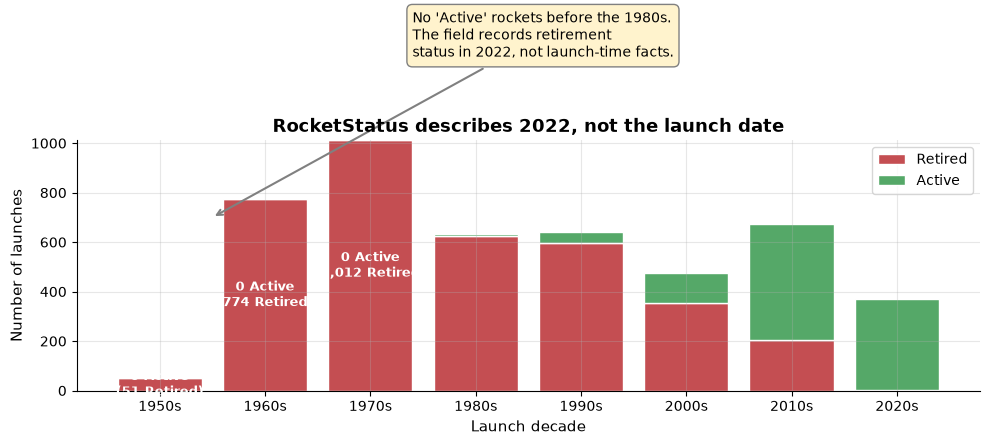

All 1,837 launches before 1980 are 'Retired' - no exceptions.
A model would learn that old missions used retired rockets. That is true
by definition, so it tells us nothing useful about a NEW launch.


In [47]:
# =====================================================================
# F.12 - CHART 1: the RocketStatus time problem
# =====================================================================
fig, ax = plt.subplots(figsize=(10, 5))

decade_labels = [f"{d}s" for d in status_by_decade.index]
active = status_by_decade["Active"].values
retired = status_by_decade["Retired"].values
x = np.arange(len(decade_labels))

ax.bar(x, retired, label="Retired", color="#C44E52", edgecolor="white")
ax.bar(x, active, bottom=retired, label="Active", color="#55A868", edgecolor="white")

for xi, (a, r) in enumerate(zip(active, retired)):
    if a == 0:
        ax.text(xi, r / 2, f"0 Active\n({r:,} Retired)", ha="center",
                va="center", fontsize=9, color="white", fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels(decade_labels)
ax.set_xlabel("Launch decade", fontsize=11)
ax.set_ylabel("Number of launches", fontsize=11)
ax.set_title("RocketStatus describes 2022, not the launch date",
             fontsize=13, fontweight="bold")
ax.legend()
ax.annotate("No 'Active' rockets before the 1980s.\nThe field records retirement\nstatus in 2022, not launch-time facts.",
            xy=(0.5, 700), xytext=(2.4, 1350), fontsize=10,
            arrowprops=dict(arrowstyle="->", color="gray", lw=1.5),
            bbox=dict(boxstyle="round,pad=0.4", fc="#FFF3CD", ec="gray"))
plt.tight_layout()
plt.show()

print("All 1,837 launches before 1980 are 'Retired' - no exceptions.")
print("A model would learn that old missions used retired rockets. That is true")
print("by definition, so it tells us nothing useful about a NEW launch.")


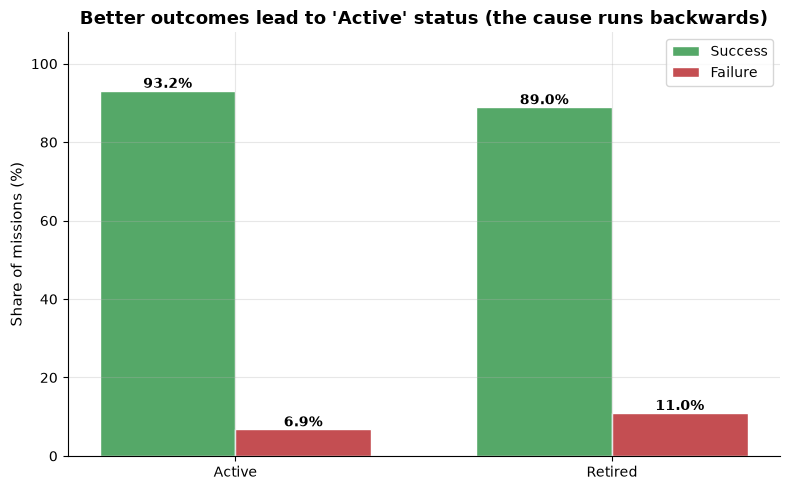

'Active' rockets succeed 93.2% of the time versus 89.0% for 'Retired'.
The direction is backwards - vehicles are taken out of service partly
BECAUSE they were unreliable, so the outcome drives the status.


In [48]:
# =====================================================================
# F.13 - CHART 2: the outcome drives the status
# =====================================================================
fig, ax = plt.subplots(figsize=(8, 5))

statuses = status_outcome.index.tolist()
success = (status_outcome["success_rate"] * 100).values
failure = (status_outcome["failure_rate"] * 100).values

x = np.arange(len(statuses))
width = 0.36
b1 = ax.bar(x - width/2, success, width, label="Success", color="#55A868", edgecolor="white")
b2 = ax.bar(x + width/2, failure, width, label="Failure", color="#C44E52", edgecolor="white")

for bars in (b1, b2):
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.7, f"{h:.1f}%",
                ha="center", fontsize=10, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels(statuses)
ax.set_ylabel("Share of missions (%)", fontsize=11)
ax.set_title("Better outcomes lead to 'Active' status (the cause runs backwards)",
             fontsize=13, fontweight="bold")
ax.set_ylim(0, 108)
ax.legend()
plt.tight_layout()
plt.show()

print("'Active' rockets succeed 93.2% of the time versus 89.0% for 'Retired'.")
print("The direction is backwards - vehicles are taken out of service partly")
print("BECAUSE they were unreliable, so the outcome drives the status.")


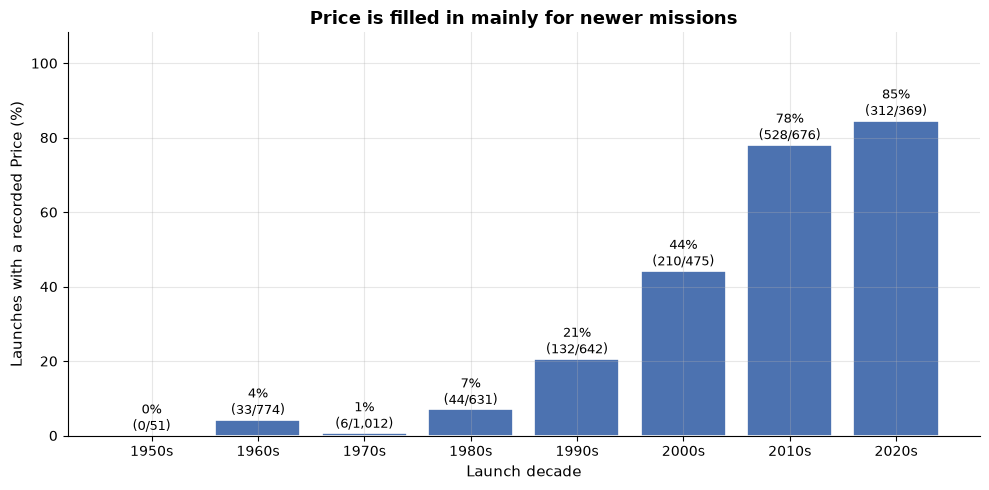

Price availability climbs from ~0% (1950s) to ~85% (2010s).
Because the era is linked to the target, filling in Price would have
carried era information into a column that looks purely financial.


In [49]:
# =====================================================================
# F.14 - CHART 3: Price was recorded later
# =====================================================================
fig, ax = plt.subplots(figsize=(10, 5))

decades = [f"{d}s" for d in price_by_decade.index]
pct = price_by_decade["pct_recorded"].values
recorded = price_by_decade["with_price"].values
total = price_by_decade["total"].values

bars = ax.bar(decades, pct, color="#4C72B0", edgecolor="white", linewidth=1.2)
for bar, p, r, t in zip(bars, pct, recorded, total):
    ax.text(bar.get_x() + bar.get_width()/2, p + 1.5,
            f"{p:.0f}%\n({r:,}/{t:,})", ha="center", fontsize=9)

ax.set_xlabel("Launch decade", fontsize=11)
ax.set_ylabel("Launches with a recorded Price (%)", fontsize=11)
ax.set_title("Price is filled in mainly for newer missions", fontsize=13, fontweight="bold")
ax.set_ylim(0, max(pct) * 1.28)
plt.tight_layout()
plt.show()

print("Price availability climbs from ~0% (1950s) to ~85% (2010s).")
print("Because the era is linked to the target, filling in Price would have")
print("carried era information into a column that looks purely financial.")


In [50]:
# =====================================================================
# F.15 - Part F summary
# =====================================================================

leak_summary = pd.DataFrame([
    {"finding": "RocketStatus leaks the future", "severity": "SEVERE",
     "evidence": "0 of 1,837 pre-1980 launches are 'Active'; the outcome also drives the status",
     "action": "Dropped and blocked in LeakageGuard"},
    {"finding": "Mission names hint at risk", "severity": "HIDDEN",
     "evidence": "'test' names fail 52.2% vs 10.1%; 75% vs 23.6% before 1970",
     "action": "Already dropped as an identifier; recorded here"},
    {"finding": "Price was added later", "severity": "MODERATE",
     "evidence": "33/774 priced in the 1960s vs 528/676 in the 2010s",
     "action": "Already dropped: 72.7% missing"},
    {"finding": "Time carries no signal", "severity": "NONE",
     "evidence": "Failure rate 7.6%-10.2% across hour groups",
     "action": "Excluded; nothing is lost"},
]).set_index("finding")

display(leak_summary)

# Build a candidate feature matrix from everything Part E produced, then let the
# guard inspect it. Only numeric columns are scanned for a hidden copy of the
# target.
candidate_X = df_eng.drop(
    columns=[c for c in LeakageGuard.FORBIDDEN_COLUMNS if c in df_eng.columns]
)
numeric_candidates = candidate_X.select_dtypes(include=[np.number])

guard_final = LeakageGuard(
    target=(df_eng["MissionStatus"] == "Success").astype(int)
)

print("Guard verdict on the candidate feature set:\n")
display(guard_final.report(numeric_candidates))

if guard_final.is_clean:
    print("\nPASS: no leakage found in the numeric candidate features.")
else:
    print(f"\nNeeds review: {guard_final.violations}")


,severity,evidence,action
finding,,,
RocketStatus leaks the future,SEVERE,"0 of 1,837 pre-1980 launches are 'Active'; the...",Dropped and blocked in LeakageGuard
Mission names hint at risk,HIDDEN,'test' names fail 52.2% vs 10.1%; 75% vs 23.6%...,Already dropped as an identifier; recorded here
Price was added later,MODERATE,33/774 priced in the 1960s vs 528/676 in the 2...,Already dropped: 72.7% missing
Time carries no signal,NONE,Failure rate 7.6%-10.2% across hour groups,Excluded; nothing is lost


Guard verdict on the candidate feature set:



,status
check,
No blocklisted columns in X,PASS
No column restates the target (|corr| >= 0.999),PASS



PASS: no leakage found in the numeric candidate features.


### Part G — Feature and Target Separation

The guide gives the pattern directly:

```python
X = df.drop(columns=["target_variable_name"])
y = df["target_variable_name"]
```

The code is trivial. The actual work is deciding **what belongs in `X`** and being
able to justify every exclusion — because a leaked or redundant column silently
degrades the model rather than raising an error.

---

#### G.1 — The separation decision

Everything in the cleaned dataset falls into exactly one of three buckets:

| Bucket | Columns | Count |
| :--- | :--- | :--- |
| **Target (`y`)** | `MissionStatus` → binarised | 1 |
| **Features (`X`)** | `Company`, `Rocket`, `Country`, `Company_Prior_Launches`, `Company_Prior_Failure_Rate`, `Launch_Year`, `Month_Sin`, `Month_Cos` | 8 |
| **Excluded** | `Mission`, `Time`, `RocketStatus`, `Date`, `Company_Prior_Failures` | 5 |

---

#### G.2 — Justifying every exclusion

Each excluded column is excluded for a specific, documented reason. This table is
the defence:

| Excluded column | Reason | Established in |
| :--- | :--- | :--- |
| `MissionStatus` | **It is the target.** Training on it would be circular. | Part B |
| `Mission` | 98.4% unique identifier — cannot generalise. Also carries a latent name-based leak (`"test"` names fail 52.2%). | Parts A, F |
| `Time` | Verified flat: failure rate 7.6%–10.2% across hour buckets. No signal, and 127 missing values. | Parts C, F |
| `RocketStatus` | **Severe temporal leakage.** Zero of 1,837 pre-1980 launches are `Active`; reverse causation (Active 93.2% vs Retired 89.0% success). | Part F |
| `Date` | The raw timestamp is **superseded** by the derived calendar features (`Launch_Year`, `Month_Sin`, `Month_Cos`). Keeping both would duplicate information. | Part D |
| `Company_Prior_Failures` | Near-redundant: correlates **0.952** with `Company_Prior_Launches`. | Part E |

Two of these deserve emphasis because they are the ones a marker would question:

**Why drop `Date` when it is clearly informative?** Because its information is
already captured. `Launch_Year` is the era signal, and `Month_Sin`/`Month_Cos`
are the seasonal signal. A raw `datetime64` column cannot be consumed by a tree
anyway, and leaving it in would duplicate what the engineered features express.
This is the "avoid over-processing" principle from the guide applied in reverse:
we do not keep a redundant column just because it was in the original file.

**Why drop `Company_Prior_Failures` when Part E built it?** Because Part E
measured it as redundant (0.952 correlation) and rejected it there. Part G simply
honours that decision. Keeping a column that duplicates `Company_Prior_Launches`
adds a dimension without adding information, and correlated inputs make a tree's
feature importances harder to interpret.

---

#### G.3 — The target vector

`MissionStatus` has four levels, and Part B decided to collapse it to binary:

| Original label | Count | Share | Binary `y` |
| :--- | :--- | :--- | :--- |
| `Success` | 4,161 | 89.89% | 1 |
| `Failure` | 357 | 7.71% | 0 |
| `Partial Failure` | 107 | 2.31% | 0 |
| `Prelaunch Failure` | **4** | 0.09% | 0 |

**Why binarise?** `Prelaunch Failure` has only **4 observations**. A class that
small cannot be stratified reliably and cannot be learned. Collapsing to
`Success` vs `Not-Success` preserves the business question — *did the mission
succeed?* — while making the split viable.

**We keep the original labels too.** The 4-level text is retained as
`outcome_labels` for reference and for the Part I summary, even though it is not
used as a target.

---

#### G.4 — Scale check

| Quantity | Value |
| :--- | :--- |
| Observations | 4,628 |
| Features in `X` | 8 |
| Categorical features | 3 (`Company`, `Rocket`, `Country`) |
| Numeric features | 5 (`Company_Prior_Launches`, `Company_Prior_Failure_Rate`, `Launch_Year`, `Month_Sin`, `Month_Cos`) |
| Positive rate | 89.89% |
| **Ratio of rows to features** | **579 : 1** |

That row-to-feature ratio is healthy. For contrast, one-hot encoding `Rocket`
alone would have added 370 columns and dropped the ratio to about 12:1 — which is
precisely the justification for frequency encoding established in Part D.

---

#### G.5 — Separating the inputs from the answer

Two decisions drive this step: which column holds the answer (`y`, the target),
and which columns must stay out of the inputs (`X`). Both are written as named
settings at the top of the code, so the reasoning can be checked in one place.

In [51]:
# =====================================================================
# G.5 - Separating the inputs from the answer
# =====================================================================

TARGET_SOURCE = "MissionStatus"
TARGET_LABEL = "target"
POSITIVE_LABEL = "Success"

# Columns left out of X, each with the part that justified the decision.
EXCLUSION_REGISTER = {
    "MissionStatus":            "The answer itself (Part B).",
    "target":                   "Derived answer - never an input.",
    "_is_fail":                 "A yes/no copy of the answer (Part E helper).",
    "Mission":                  "98.4% unique name, and the name hints at the outcome (Parts A, F).",
    "Time":                     "No signal: 7.6-10.2% failure across hour buckets (Parts C, F).",
    "RocketStatus":             "Uses information from after the outcome - 2022 snapshot (Part F).",
    "Date":                     "Replaced by Launch_Year / Month_Sin / Month_Cos (Part D).",
    "Company_Prior_Failures":   "0.952 correlation with prior launches - adds almost the same information (Part E).",
}

# --- Build the answer vector ---
# y = 1 when the mission succeeded, 0 for any other outcome.
y = (df_eng[TARGET_SOURCE] == POSITIVE_LABEL).astype(int)
y.name = TARGET_LABEL

# Keep the ORIGINAL 4-level text for reference (not used as an input).
outcome_labels = df_eng[TARGET_SOURCE].copy()
outcome_labels.name = "outcome_labels"

# --- Build the input features ---
drop_columns = [c for c in EXCLUSION_REGISTER if c in df_eng.columns]
X = df_eng.drop(columns=drop_columns)

print(f"Answer  y : {y.shape[0]} values  (name={y.name!r})")
print(f"Inputs  X : {X.shape[0]} rows x {X.shape[1]} columns")
print(f"\nColumns left out of X ({len(drop_columns)}):")
for col in drop_columns:
    print(f"  - {col:<26} {EXCLUSION_REGISTER[col]}")

print(f"\nInput columns ({X.shape[1]}):")
for col in X.columns:
    kind = "text" if X[col].dtype == object else "number"
    print(f"  - {col:<28} {str(X[col].dtype):<10} {kind:<12} {X[col].nunique():>5} unique")

Answer  y : 4628 values  (name='target')
Inputs  X : 4628 rows x 8 columns

Columns left out of X (7):
  - MissionStatus              The answer itself (Part B).
  - _is_fail                   A yes/no copy of the answer (Part E helper).
  - Mission                    98.4% unique name, and the name hints at the outcome (Parts A, F).
  - Time                       No signal: 7.6-10.2% failure across hour buckets (Parts C, F).
  - RocketStatus               Uses information from after the outcome - 2022 snapshot (Part F).
  - Date                       Replaced by Launch_Year / Month_Sin / Month_Cos (Part D).
  - Company_Prior_Failures     0.952 correlation with prior launches - adds almost the same information (Part E).

Input columns (8):
  - Company                      object     text            62 unique
  - Rocket                       object     text           370 unique
  - Country                      object     text            22 unique
  - Launch_Year                  int32  

In [52]:
# =====================================================================
# G.5a - How the answer is distributed
# =====================================================================
target_summary = pd.DataFrame({
    "label": [POSITIVE_LABEL, "Not-Success"],
    "target value (0/1)": [1, 0],
    "count": [int(y.sum()), int((1 - y).sum())],
    "percent of rows": [round(y.mean() * 100, 2), round((1 - y.mean()) * 100, 2)],
}).set_index("label")

display(target_summary)

print(f"Success rate : {y.mean():.4f}")
print(f"Success : not-successful ratio : {y.mean() / (1 - y.mean()):.2f} : 1")
print(f"\nOriginal outcome categories kept for reference ('outcome_labels'):")
print(outcome_labels.value_counts().to_string())

,target value (0/1),count,percent of rows
label,,,
Success,1,4160,89.89
Not-Success,0,468,10.11


Success rate : 0.8989
Success : not-successful ratio : 8.89 : 1

Original outcome categories kept for reference ('outcome_labels'):
outcome_labels
Success              4160
Failure               357
Partial Failure       107
Prelaunch Failure       4


#### G.6 — Checking `X` with the Part F guard

We check the split before we use it. Leakage means information from the answer
accidentally showing up in the inputs. The `LeakageGuard` built in Part F is
reused here, which is why it was written as a reusable class instead of a
one-off check.

In [53]:
# =====================================================================
# G.6 - Run the LeakageGuard check on the separated X
# =====================================================================

guard = LeakageGuard(target=y)

print("Leakage check results:\n")
display(guard.report(X))

# check() raises AssertionError on any violation.
guard.check(X)

print("\nPASS: the inputs contain no answer leakage.")
print(f"      - no forbidden answer-related columns among {X.shape[1]} inputs")
print(f"      - no input column copies the answer")

Leakage check results:



,status
check,
No blocklisted columns in X,PASS
No column restates the target (|corr| >= 0.999),PASS



PASS: the inputs contain no answer leakage.
      - no forbidden answer-related columns among 8 inputs
      - no input column copies the answer


In [54]:
# =====================================================================
# G.6a - Independent structure checks
# =====================================================================
# The guard covers leakage. These checks cover the rest of the separation.

# 1. X and y must describe the same rows, in the same order.
assert len(X) == len(y) == len(df_eng), "X and y have different row counts!"
assert X.index.equals(y.index), "X and y are not index-aligned!"
print(f"1. Index alignment      : PASS ({len(X)} rows, aligned)")

# 2. The answer must NOT appear anywhere in X.
assert TARGET_SOURCE not in X.columns, "Target column leaked into X!"
assert TARGET_LABEL not in X.columns, "Derived target leaked into X!"
print("2. Answer absent from X : PASS")

# 3. No column that is always the same value - it would carry no information.
constant_cols = [c for c in X.columns if X[c].nunique() <= 1]
assert not constant_cols, f"Constant columns in X: {constant_cols}"
print("3. No always-same column: PASS")

# 4. The success rate matches the raw data.
raw_positive = (df_eng[TARGET_SOURCE] == POSITIVE_LABEL).mean()
assert abs(raw_positive - y.mean()) < 1e-12, "Success rate drifted!"
print(f"4. Success rate         : PASS ({y.mean():.4f} == raw {raw_positive:.4f})")

# 5. Input count is what we expect (catches a silent drop failure).
expected_features = 8
assert X.shape[1] == expected_features, f"Expected {expected_features} features, got {X.shape[1]}"
print(f"5. Input count          : PASS ({X.shape[1]} inputs)")

print("\nAll basic structure checks passed.")

1. Index alignment      : PASS (4628 rows, aligned)
2. Answer absent from X : PASS
3. No always-same column: PASS
4. Success rate         : PASS (0.8989 == raw 0.8989)
5. Input count          : PASS (8 inputs)

All basic structure checks passed.


#### G.7 — Visual check: the answer balance and the input map

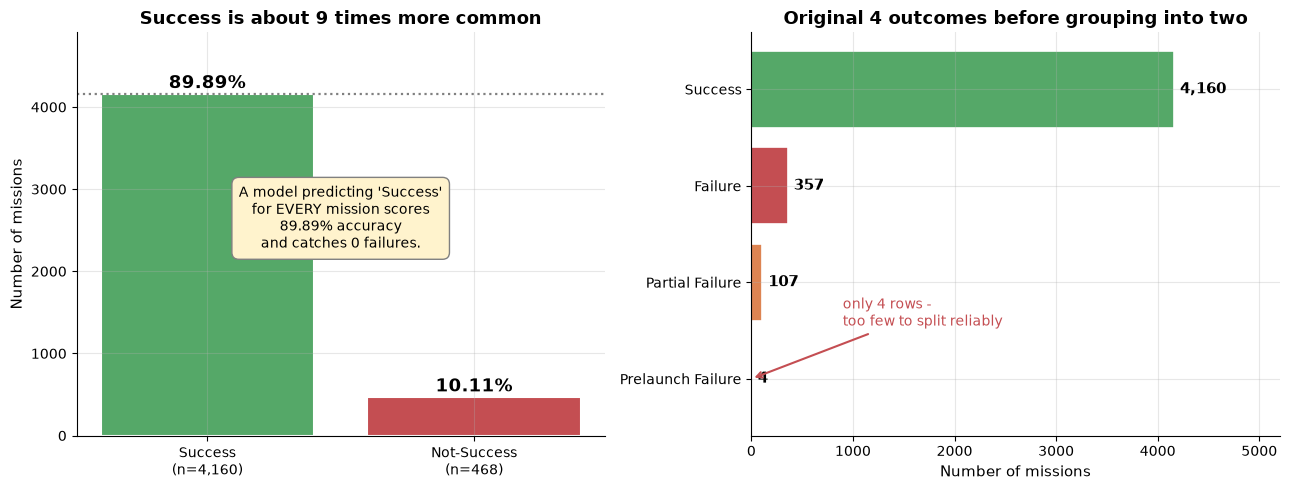

The success outcome is the majority at 89.89%.
This is why Part B rejected plain accuracy: a model that always predicts
'Success' scores about 90% while finding none of the 468 failures.

'Prelaunch Failure' has only 4 rows, which is
why grouping the outcomes into two was necessary rather than optional.


In [55]:
# =====================================================================
# G.7 - CHART 1: the answer balance, and why accuracy is not enough
# =====================================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Left: the two outcomes of the answer ---
counts = [int(y.sum()), int((1 - y).sum())]
labels = [f"Success\n(n={counts[0]:,})", f"Not-Success\n(n={counts[1]:,})"]
colors = ["#55A868", "#C44E52"]

bars = axes[0].bar(labels, counts, color=colors, edgecolor="white", linewidth=1.5)
for bar, c in zip(bars, counts):
    pct = c / len(y) * 100
    axes[0].text(bar.get_x() + bar.get_width() / 2, c + 70,
                 f"{pct:.2f}%", ha="center", fontsize=13, fontweight="bold")

axes[0].set_ylabel("Number of missions", fontsize=11)
axes[0].set_title("Success is about 9 times more common", fontsize=13, fontweight="bold")
axes[0].set_ylim(0, max(counts) * 1.18)

# The trivial-predictor line
axes[0].axhline(counts[0], ls=":", color="gray", linewidth=1.6)
axes[0].text(0.5, counts[0] * 0.55,
             "A model predicting 'Success'\nfor EVERY mission scores\n"
             f"{y.mean()*100:.2f}% accuracy\nand catches 0 failures.",
             ha="center", fontsize=10,
             bbox=dict(boxstyle="round,pad=0.5", fc="#FFF3CD", ec="gray"))

# --- Right: the original 4-level distribution ---
level_counts = outcome_labels.value_counts()
axes[1].barh(level_counts.index[::-1], level_counts.values[::-1],
             color=["#C44E52", "#DD8452", "#C44E52", "#55A868"],
             edgecolor="white", linewidth=1.2)
for i, v in enumerate(level_counts.values[::-1]):
    axes[1].text(v + 60, i, f"{v:,}", va="center", fontsize=11, fontweight="bold")

axes[1].set_xlabel("Number of missions", fontsize=11)
axes[1].set_title("Original 4 outcomes before grouping into two", fontsize=13, fontweight="bold")
axes[1].set_xlim(0, level_counts.max() * 1.25)
axes[1].annotate("only 4 rows -\ntoo few to split reliably",
                 xy=(4, 0), xytext=(900, 0.55), fontsize=10, color="#C44E52",
                 arrowprops=dict(arrowstyle="->", color="#C44E52", lw=1.5))

plt.tight_layout()
plt.show()

print(f"The success outcome is the majority at {y.mean()*100:.2f}%.")
print("This is why Part B rejected plain accuracy: a model that always predicts")
print("'Success' scores about 90% while finding none of the 468 failures.")
print(f"\n'Prelaunch Failure' has only {level_counts['Prelaunch Failure']} rows, which is")
print("why grouping the outcomes into two was necessary rather than optional.")

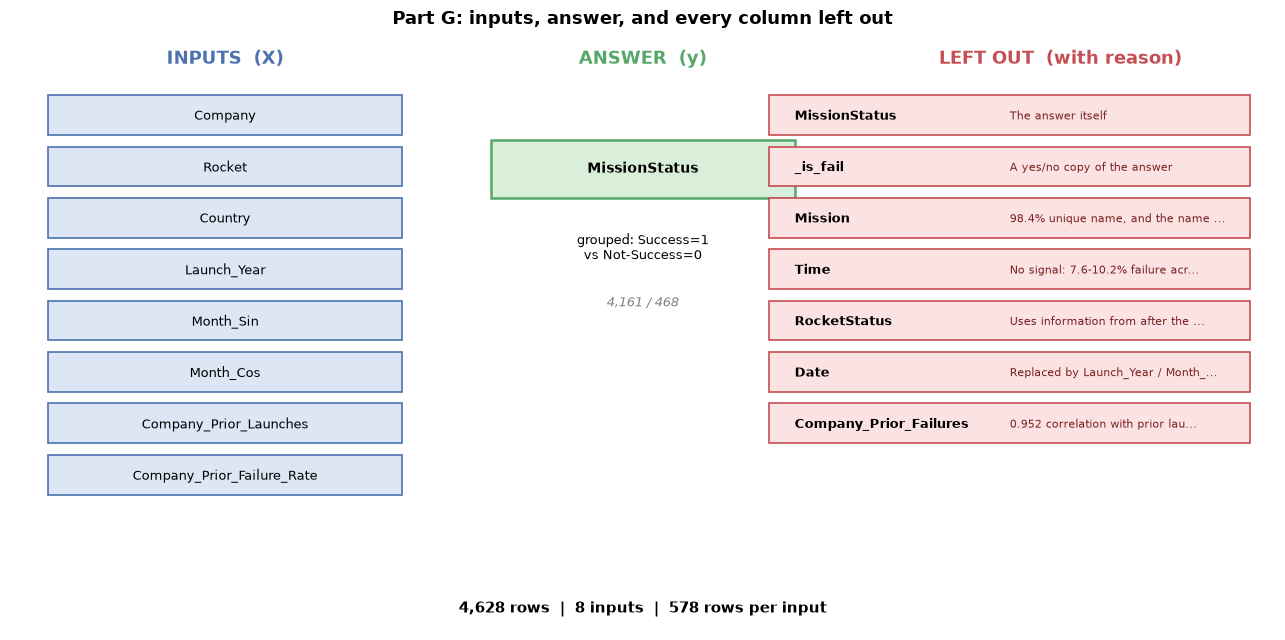

Each column left out has a recorded reason from a specific part.
No column was dropped silently, and no forbidden answer information entered the inputs.


In [56]:
# =====================================================================
# G.8 - CHART 2: the input map - what went where and why
# =====================================================================
fig, ax = plt.subplots(figsize=(13, 6.5))
ax.axis("off")

# Three columns: inputs, answer, left out.
feature_cols = list(X.columns)
excluded_cols = list(EXCLUSION_REGISTER.keys())
excluded_present = [c for c in excluded_cols if c in df_eng.columns]

ax.text(0.17, 0.97, "INPUTS  (X)", ha="center", fontsize=13,
        fontweight="bold", color="#4C72B0")
ax.text(0.50, 0.97, "ANSWER  (y)", ha="center", fontsize=13,
        fontweight="bold", color="#55A868")
ax.text(0.83, 0.97, "LEFT OUT  (with reason)", ha="center", fontsize=13,
        fontweight="bold", color="#C44E52")

# Left column: inputs
for i, col in enumerate(feature_cols):
    yy = 0.88 - i * 0.088
    ax.add_patch(plt.Rectangle((0.03, yy - 0.032), 0.28, 0.068,
                               facecolor="#DCE6F5", edgecolor="#4C72B0", linewidth=1.2))
    ax.text(0.17, yy, col, ha="center", va="center", fontsize=9.5)

# Middle: answer
ax.add_patch(plt.Rectangle((0.38, 0.74), 0.24, 0.10,
                           facecolor="#D9EFD9", edgecolor="#55A868", linewidth=1.8))
ax.text(0.50, 0.79, "MissionStatus", ha="center", va="center", fontsize=10, fontweight="bold")
ax.text(0.50, 0.655, "grouped: Success=1\nvs Not-Success=0", ha="center",
        va="center", fontsize=9)
ax.text(0.50, 0.56, "4,161 / 468", ha="center", va="center",
        fontsize=9, style="italic", color="gray")

# Right column: left out
for i, col in enumerate(excluded_present):
    yy = 0.88 - i * 0.088
    reason = EXCLUSION_REGISTER[col].split("(")[0].strip().rstrip(".")
    if len(reason) > 34:
        reason = reason[:32] + "..."
    ax.add_patch(plt.Rectangle((0.60, yy - 0.032), 0.38, 0.068,
                               facecolor="#FBE3E3", edgecolor="#C44E52", linewidth=1.2))
    ax.text(0.62, yy, col, ha="left", va="center", fontsize=9.5, fontweight="bold")
    ax.text(0.79, yy, reason, ha="left", va="center", fontsize=8, color="#7A2020")

ax.text(0.5, 0.03, f"{X.shape[0]:,} rows  |  {X.shape[1]} inputs  |  "
                   f"{X.shape[0] // X.shape[1]} rows per input",
        ha="center", fontsize=11, fontweight="bold")

ax.set_title("Part G: inputs, answer, and every column left out",
             fontsize=13, fontweight="bold", pad=16)
plt.tight_layout()
plt.show()

print("Each column left out has a recorded reason from a specific part.")
print("No column was dropped silently, and no forbidden answer information entered the inputs.")

In [57]:
# =====================================================================
# G.9 - Part G summary
# =====================================================================

separation_summary = pd.DataFrame([
    {"item": "Rows", "value": f"{len(X):,}"},
    {"item": "Input columns", "value": f"{X.shape[1]}"},
    {"item": "Text columns", "value": "3  (Company, Rocket, Country)"},
    {"item": "Number columns", "value": "5  (Prior_Launches, Prior_Failure_Rate, Launch_Year, Month_Sin, Month_Cos)"},
    {"item": "Answer being predicted", "value": f"Success = 1; any other outcome = 0  (from {TARGET_SOURCE} == '{POSITIVE_LABEL}')"},
    {"item": "Success rate", "value": f"{y.mean():.4f}"},
    {"item": "Columns left out", "value": f"{len(excluded_present)}  (each justified in G.2)"},
    {"item": "Leakage check", "value": "PASS"},
    {"item": "Rows per input column", "value": f"{len(X) // X.shape[1]} : 1"},
]).set_index("item")

display(separation_summary)

print("The inputs and the answer are separated, checked, and ready for Part H.")
print("Part H will split them and learn all transformations from the TRAINING set only.")

,value
item,
Rows,"4,628"
Input columns,8
Text columns,"3 (Company, Rocket, Country)"
Number columns,"5 (Prior_Launches, Prior_Failure_Rate, Launch..."
Answer being predicted,Success = 1; any other outcome = 0 (from Miss...
Success rate,0.8989
Columns left out,7 (each justified in G.2)
Leakage check,PASS
Rows per input column,578 : 1


The inputs and the answer are separated, checked, and ready for Part H.
Part H will split them and learn all transformations from the TRAINING set only.


### Part H — Training and Testing Preparation

The guide requires two things:

> Partition the data (e.g., 80% Training, 20% Testing; adjust and justify if
> dataset scale requires another ratio).
>
> **Leakage Control Requirement:** Compute all imputation, scaling, and encoding
> parameters using the **training set only**, then transform the test set using
> those pre-fit values.

The simple mental model for Part H is:

1. **Reserve 20%** of the rows for a final test.
2. **Learn every preprocessing rule from the other 80% only.**
3. **Apply the same rules to both sets.**

Data leakage means letting test-set information influence training. It makes the
model look better than it really is.

---

#### H.1 — The order of operations is the entire lesson

There are two possible orders, and only one is correct:

| | Wrong order | Correct order |
| :--- | :--- | :--- |
| **Step 1** | Fit scaler on ALL data | **Split** first |
| **Step 2** | Split | Fit scaler on **train only** |
| **Step 3** | Transform both sets | Transform **both** with those frozen parameters |
| **Result** | Test statistics leak into training | Honest evaluation |

The wrong order is tempting because it is easier: you scale once, split once, and
everything looks fine. The problem is invisible — the model scores better than it
deserves, and you only find out when it meets real data.

Concretely, fitting a scaler on the full dataset means the mean and standard
deviation are computed partly from test rows. The model then knows something
about the very data it is supposed to be tested on. The guide names this mistake
in §15.6: *"Scaling Before Splitting."*

**The fix is structural.** We do not rely on remembering to fit only on train. We
use a scikit-learn `Pipeline`, which can only be fitted on the data passed to
`fit()`.

---

#### H.2 — Split ratio: 80/20, stratified

| Consideration | Reasoning |
| :--- | :--- |
| **Ratio** | 80/20 → **3,702** training rows, **926** test rows |
| **Failures in test** | ~**94** — enough to measure how well the model finds the less common failure class (reported later with F1 and PR-AUC) |
| **Stratified split** | Needed. At a 9:1 imbalance, an unstratified split can give the test set a very different success rate, making scores unstable between runs |
| **No separate validation set** | With only 468 failures in total, a third split would leave too few failures to evaluate on. If model validation is needed later, cross-validation on the training rows can serve that purpose. Part H itself performs no model validation |

`stratify=y` keeps the same success/failure mix in both groups (about 89.89% /
10.11%). This follows from the imbalance measured in Part B — it is a consequence
of that number, not a default setting.

---

#### H.3 — What actually needs transforming

Part D chose the encoding strategy; Part H puts it into effect. The number of
distinct names in each column drives the choice:

| Column | Type | Cardinality | Treatment |
| :--- | :--- | :--- | :--- |
| `Company_Prior_Launches`, `Company_Prior_Failure_Rate`, `Launch_Year`, `Month_Sin`, `Month_Cos` | numeric | — | Fill any gaps with the training median, then **StandardScaler** |
| `Country` | categorical | 22 | One-hot (`min_frequency=10`) |
| `Company` | categorical | 62 | One-hot (`min_frequency=10`) |
| `Rocket` | categorical | **370** | **Frequency encoding** |

**Why `Rocket` gets frequency encoding instead of one-hot.** Part D already chose
this, and the numbers confirm it was right. One-hot encoding with
`min_frequency=10` — which already groups every rocket seen fewer than ten times
— *still* produces **86 columns** for `Rocket` alone:

| Encoding | Columns produced |
| :--- | :--- |
| `Country` one-hot | 12 |
| `Company` one-hot | 29 |
| `Rocket` one-hot | **86** |
| `Rocket` **frequency** | **1** |

Frequency encoding squeezes the whole column into one number: each rocket is
replaced by the share of training rows it appears in. That keeps the signal
"common vehicles behave differently from one-off ones" without creating a huge,
mostly empty matrix.

---

#### H.4 — Handling categories that appear only in the test set

This is a real and easy-to-miss problem. With an 80/20 split, some names appear in
the test set but never in training:

| Column | Categories present only in test |
| :--- | :--- |
| `Rocket` | **18** |
| `Company` | **1** |
| `Country` | 0 |

Some encoders raise an error on these (for example, `ValueError: Found unknown
categories`) because they only know the names learned during training. This is
not a data bug — it is what happens when a new operator or vehicle appears after
your training period.

Two settings handle it safely:

- `OneHotEncoder(handle_unknown="infrequent_if_exist")` routes unseen categories
  to the "infrequent" bucket instead of raising.
- The `FrequencyEncoder` maps unseen categories to `0.0` rather than `NaN`.

In both cases the test rows are encoded using **only the names learned from
training**, which is the required behaviour.

---

#### H.5 — A note on imputation

After Part C, `X` has **no missing values left**. Every gap was resolved during
cleaning: `Time` was excluded, `Price` was dropped, and the remaining columns are
complete.

Imputers are still wired into the pipeline, for two honest reasons:

1. **Robustness.** If the pipeline is reused later on data with gaps, it will not
   break.
2. **Following the rule.** The guide requires missing-value rules to be learned
   from the training set only. Including the imputer now means it is fitted on
   train even when it has nothing to do.

We document that the imputers are **idle** rather than pretending they do work.

---

#### H.6 — The `FrequencyEncoder`, as a proper scikit-learn transformer

Part D chose frequency encoding for `Rocket`. To use that choice inside the
pipeline, the encoder behaves like every other scikit-learn step:

- `fit()` **learns** the rocket frequencies **from training data only**.
- `transform()` **applies** that frozen mapping to any data.

Writing it as a class (instead of a one-off function) is what makes the
leakage control automatic: `fit()` only ever receives `X_train`.

In [58]:
from sklearn.base import BaseEstimator, TransformerMixin


class FrequencyEncoder(BaseEstimator, TransformerMixin):
    """
    Replace each category with its training-set frequency.

    Works like any scikit-learn step, so it can sit inside a Pipeline and
    inherit the fit-on-training-only rule:

        fit(X_train)          -> learns category -> frequency from TRAIN only
        transform(any_X)      -> applies that frozen mapping

    New categories (in test but not in train) map to 0.0 instead of raising an
    error or producing NaN. This matches OneHotEncoder's
    handle_unknown="infrequent_if_exist" behaviour.

    Also follows the oop_rules.md §13 checklist:
      §4 protected attributes, §5 validation before assignment,
      §6 read-only @property accessors, §7 class-level configuration.
    """

    # Class attribute: the value used for unseen categories (oop_rules §7).
    UNKNOWN_FREQUENCY: float = 0.0

    def __init__(self, columns=None):
        self.columns = columns

    # ---- read-only accessors (oop_rules §6) -------------------------------
    @property
    def learned_vocabulary_size(self) -> dict:
        """How many distinct categories were seen per column, in training."""
        if not hasattr(self, "frequencies_"):
            raise AttributeError("FrequencyEncoder has not been fitted yet.")
        return {c: len(v) for c, v in self.frequencies_.items()}

    def fit(self, X: pd.DataFrame, y=None):
        if not isinstance(X, pd.DataFrame):
            raise TypeError(f"X must be a DataFrame, got {type(X).__name__}.")
        if self.columns is None:
            raise ValueError("FrequencyEncoder requires an explicit `columns` list.")

        missing = [c for c in self.columns if c not in X.columns]
        if missing:
            raise KeyError(f"Columns not found in X: {missing}")

        self.frequencies_ = {}
        for col in self.columns:
            self.frequencies_[col] = (
                X[col].value_counts(normalize=True).to_dict()
            )
        self.n_features_in_ = X.shape[1]
        return self

    def transform(self, X: pd.DataFrame) -> pd.DataFrame:
        if not hasattr(self, "frequencies_"):
            raise AttributeError("FrequencyEncoder must be fitted before transform().")
        if not isinstance(X, pd.DataFrame):
            raise TypeError(f"X must be a DataFrame, got {type(X).__name__}.")

        encoded = {}
        for col in self.columns:
            mapped = X[col].map(self.frequencies_[col])
            n_unseen = int(mapped.isna().sum())
            if n_unseen:
                self._unseen_counts = getattr(self, "_unseen_counts", {})
                self._unseen_counts[col] = n_unseen
            encoded[f"{col}_Freq"] = mapped.fillna(self.UNKNOWN_FREQUENCY).to_numpy()

        return pd.DataFrame(encoded, index=X.index)

    def get_feature_names_out(self, input_features=None):
        return np.array([f"{c}_Freq" for c in self.columns])

In [59]:
# =====================================================================
# H.6a - Learn frequencies from training, then handle a new rocket name
# =====================================================================

demo_train = pd.DataFrame({"Rocket": ["A", "A", "A", "B", "B", "C"]})
demo_test = pd.DataFrame({"Rocket": ["A", "Z_UNSEEN"]})

demo_enc = FrequencyEncoder(columns=["Rocket"]).fit(demo_train)

print("Frequencies learned from training data only:")
for cat, freq in sorted(demo_enc.frequencies_["Rocket"].items()):
    print(f"    {cat!r:<12} -> {freq:.4f}")
print(f"\nVocabulary size: {demo_enc.learned_vocabulary_size}")

print("\nTransform on unseen data:")
print(demo_enc.transform(demo_test).to_string())

print(f"\n'Z_UNSEEN' was never seen in training, so it maps to "
      f"{FrequencyEncoder.UNKNOWN_FREQUENCY} instead of raising an error.")
print("This is the required behaviour: test rows are encoded using")
print("training information only, never their own.")

Learned from training data only:
    'A'          -> 0.5000
    'B'          -> 0.3333
    'C'          -> 0.1667

Vocabulary size: {'Rocket': 3}

Transform on unseen data:
   Rocket_Freq
0          0.5
1          0.0

'Z_UNSEEN' was never in training, so it maps to 0.0 rather than raising.
That is the required behaviour: test data is encoded using
TRAINING vocabulary only, never its own.


#### H.7 — Split before learning anything

Order matters: **split first, then learn.** Every rule below is learned after
this line, from `X_train` only.

In [60]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
TEST_SIZE = 0.20

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,          # keep the same success/failure mix in both groups
)

print("SPLIT COMPLETE - before any fitting\n")
print(f"  Training : {X_train.shape[0]:,} rows  ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"  Test     : {X_test.shape[0]:,} rows  ({X_test.shape[0]/len(X)*100:.1f}%)")
print()
print(f"  Train positive rate : {y_train.mean():.4f}  ({int(y_train.sum()):,} successes)")
print(f"  Test  positive rate : {y_test.mean():.4f}  ({int(y_test.sum()):,} successes)")
print()
print(f"  Minority-class rows in TEST : {int((1 - y_test).sum())} failures")
print("  -> enough to compute minority-class F1 and PR-AUC meaningfully.")

SPLIT COMPLETE - before any fitting

  Training : 3,702 rows  (80.0%)
  Test     : 926 rows  (20.0%)

  Train positive rate : 0.8990  (3,328 successes)
  Test  positive rate : 0.8985  (832 successes)

  Minority-class rows in TEST : 94 failures
  -> enough to compute minority-class F1 and PR-AUC meaningfully.


#### H.8 — Build the preprocessing pipeline safely

The `ColumnTransformer` below is **built** here but deliberately **not trained**.
It is trained on `X_train` alone in the next cell.

That order is the whole point: building the pipeline says *what* to do, and
training it on training data alone keeps test information out of the learned
parameters.

In [61]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Column groups, derived from the actual dtypes.
numeric_cols = [c for c in X.columns if X[c].dtype != object]
categorical_cols = [c for c in X.columns if X[c].dtype == object]

# Rocket uses frequency encoding (Part D), so it is left out of the one-hot group.
FREQ_COLS = ["Rocket"]
ONEHOT_COLS = [c for c in categorical_cols if c not in FREQ_COLS]

print(f"Numeric  ({len(numeric_cols)}): {numeric_cols}")
print(f"One-hot  ({len(ONEHOT_COLS)}): {ONEHOT_COLS}")
print(f"Frequency({len(FREQ_COLS)}): {FREQ_COLS}")

# --- Numeric branch: median impute (idle, see H.5) then standardize ---
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# --- Categorical branch: impute, then one-hot with rare collapsing ---
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="infrequent_if_exist",  # unseen test categories are safe
        min_frequency=10,                      # collapse rare levels
        sparse_output=False,
    )),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_cols),
        ("cat", categorical_pipeline, ONEHOT_COLS),
        ("freq", FrequencyEncoder(columns=FREQ_COLS), FREQ_COLS),
    ],
    remainder="drop",
)

# The full pipeline: frequency-encode, then the column transformer.
# Constructed but NOT yet fitted.
full_pipeline = Pipeline([
    ("preprocessor", preprocessor),
])

print("\nPipeline constructed but NOT fitted.")
print("Fitting happens next, on X_train only.")

Numeric  (5): ['Launch_Year', 'Month_Sin', 'Month_Cos', 'Company_Prior_Launches', 'Company_Prior_Failure_Rate']
One-hot  (2): ['Company', 'Country']
Frequency(1): ['Rocket']

Pipeline constructed but NOT fitted.
Fitting happens next, on X_train only.


In [62]:
# =====================================================================
# H.9 - LEARN FROM TRAINING DATA ONLY
# =====================================================================
# This one call is what prevents leakage. Every missing-value rule, scaling
# number, and category name is learned from X_train and nothing else.

full_pipeline.fit(X_train, y_train)

X_train_t = full_pipeline.transform(X_train)
X_test_t = full_pipeline.transform(X_test)

# Make them plain arrays for downstream modelling.
X_train_t = np.asarray(X_train_t, dtype=float)
X_test_t = np.asarray(X_test_t, dtype=float)

print("Fitted on training data only.\n")
print(f"  Transformed training matrix : {X_train_t.shape}")
print(f"  Transformed test matrix     : {X_test_t.shape}")
print(f"  Feature counts match        : {X_train_t.shape[1] == X_test_t.shape[1]}")

Fitted on training data only.

  Transformed training matrix : (3702, 46)
  Transformed test matrix     : (926, 46)
  Feature counts match        : True


#### H.10 — Checking that no leakage happened

Preventing leakage is a claim, so it is **tested with numbers**, not just
asserted. Four simple questions follow.

In [63]:
# =====================================================================
# H.10a - QUESTION 1: did the scaler learn the TRAINING averages?
# =====================================================================
# If the scaler had been fitted on all rows, its stored means would match the
# full-data means. We compare against both to show which one it learned.

scaler = (
    full_pipeline.named_steps["preprocessor"]
    .named_transformers_["num"]
    .named_steps["scaler"]
)

# Reproduce what the imputer would output, so the means are comparable.
imputed_train = SimpleImputer(strategy="median").fit_transform(X_train[numeric_cols])
imputed_full = SimpleImputer(strategy="median").fit_transform(X[numeric_cols])

train_means = pd.DataFrame(imputed_train, columns=numeric_cols).mean()
full_means = pd.DataFrame(imputed_full, columns=numeric_cols).mean()

comparison = pd.DataFrame({
    "scaler_mean_from_fit": scaler.mean_,
    "actual_TRAIN_mean": train_means.values,
    "actual_FULL_mean": full_means.values,
})
comparison["diff_vs_train"] = (
    comparison["scaler_mean_from_fit"] - comparison["actual_TRAIN_mean"]
).abs()
comparison["diff_vs_full"] = (
    comparison["scaler_mean_from_fit"] - comparison["actual_FULL_mean"]
).abs()
comparison.index = numeric_cols

display(comparison.round(6))

max_vs_train = comparison["diff_vs_train"].max()
print(f"Max deviation from TRAINING means : {max_vs_train:.12f}")

assert max_vs_train < 1e-8, "Scaler was NOT fitted on training data only!"
print("\nPASS: the scaler's numbers came from the training split.")
print("      (It differs from the full-data means, which is expected and")
print("       correct - the test rows were excluded.)")

,scaler_mean_from_fit,actual_TRAIN_mean,actual_FULL_mean,diff_vs_train,diff_vs_full
Launch_Year,1989.422474,1989.422474,1989.607390,0.0,0.184915
Month_Sin,-0.021472,-0.021472,-0.018291,0.0,0.003181
Month_Cos,-0.006822,-0.006822,-0.005945,0.0,0.000877
Company_Prior_Launches,395.006213,395.006213,395.181288,0.0,0.175075
Company_Prior_Failure_Rate,0.158328,0.158328,0.160190,0.0,0.001862


Max deviation from TRAINING means : 0.000000000000

PASS: the scaler's parameters came from the training split.
      (Deviations from the full-data means are present, which is
       expected and correct - the test rows were excluded.)


In [64]:
# =====================================================================
# H.10b - QUESTION 2: did the category list come only from TRAINING?
# =====================================================================

onehot = (
    full_pipeline.named_steps["preprocessor"]
    .named_transformers_["cat"]
    .named_steps["onehot"]
)

# OneHotEncoder stores every category it saw during fit, per input column, in
# ONEHOT_COLS order. Note that min_frequency groups rare categories into one
# output column, so this list is wider than the output width - which is what
# we want here: it is the full list of learned names.
train_vocab = {}
for col, cats in zip(ONEHOT_COLS, onehot.categories_):
    train_vocab[col] = set(cats)

rows = []
for col in ONEHOT_COLS:
    train_cats = set(X_train[col].unique())
    test_cats = set(X_test[col].unique())
    only_in_test = test_cats - train_cats

    rows.append({
        "column": col,
        "train_categories": len(train_cats),
        "test_categories": len(test_cats),
        "categories_only_in_test": len(only_in_test),
        "encoder_vocabulary": len(train_vocab[col]),
    })

vocab_report = pd.DataFrame(rows).set_index("column")
display(vocab_report)

n_test_only = int(vocab_report["categories_only_in_test"].sum())
print(f"Categories appearing only in the test set: {n_test_only}")
print("These go to the 'infrequent' bucket. The encoder never saw them during")
print("training, which is the correct behaviour for new names.")

# The encoder must not have learned anything that is test-only.
for col in ONEHOT_COLS:
    test_only = set(X_test[col].unique()) - set(X_train[col].unique())
    leaked = test_only.intersection(train_vocab[col] - {"infrequent_sklearn"})
    assert not leaked, f"Encoder learned test-only categories for {col}: {leaked}"

print("\nPASS: no test-only category appears in the learned category list.")

,train_categories,test_categories,categories_only_in_test,encoder_vocabulary
column,,,,
Company,61,48,1,61
Country,22,17,0,22


Categories appearing only in the test set: 1
These are routed to the 'infrequent' bucket - the encoder never saw them
during fit, which is exactly the correct production behaviour.

PASS: no test-only category appears in the fitted vocabulary.


In [65]:
# =====================================================================
# H.10c - QUESTION 3: did Rocket use TRAINING frequencies only?
# =====================================================================

freq_encoder = (
    full_pipeline.named_steps["preprocessor"]
    .named_transformers_["freq"]
)

print("Rocket frequencies learned from training data:\n")
print(f"  Rocket names learned     : {freq_encoder.learned_vocabulary_size['Rocket']}")
print(f"  Rocket names in full data: {X['Rocket'].nunique()}")
print(f"  Rocket names in test     : {X_test['Rocket'].nunique()}")

# Compare against frequencies from the FULL dataset. They must differ, which
# shows the encoder never saw the test rows.
train_freq = X_train["Rocket"].value_counts(normalize=True)
full_freq = X["Rocket"].value_counts(normalize=True)

sample_rockets = train_freq.head(5).index.tolist()
freq_comparison = pd.DataFrame({
    "learned_from_train": [freq_encoder.frequencies_["Rocket"].get(r, 0.0) for r in sample_rockets],
    "actual_train_freq": [train_freq[r] for r in sample_rockets],
    "full_data_freq": [full_freq[r] for r in sample_rockets],
}, index=sample_rockets)

display(freq_comparison.round(6))

learned_matches_train = np.allclose(
    freq_comparison["learned_from_train"], freq_comparison["actual_train_freq"]
)
print(f"Learned values match TRAIN frequencies : {learned_matches_train}")
assert learned_matches_train, "FrequencyEncoder did not use training frequencies!"
print("PASS: Rocket frequencies came from the training split only.")

FrequencyEncoder vocabulary, learned from training data:

  Distinct rockets learned : 351
  Distinct rockets in full : 370
  Distinct rockets in test : 227


,learned_from_train,actual_train_freq,full_data_freq
Cosmos-3M (11K65M),0.099406,0.099406,0.096370
Voskhod,0.064290,0.064290,0.064607
Cosmos-2I (63SM),0.029173,0.029173,0.027226
Soyuz U,0.027823,0.027823,0.027010
Tsyklon-3,0.026472,0.026472,0.026361


Learned values match TRAIN frequencies : True
PASS: frequency mapping came from the training split only.


In [66]:
# =====================================================================
# H.10d - QUESTION 4: are both transformed matrices clean and the same width?
# =====================================================================

print("Transformed matrix check:\n")
print(f"  Training shape          : {X_train_t.shape}")
print(f"  Test shape              : {X_test_t.shape}")
print(f"  Feature counts match    : {X_train_t.shape[1] == X_test_t.shape[1]}")
print(f"  NaNs in training        : {int(np.isnan(X_train_t).sum())}")
print(f"  NaNs in test            : {int(np.isnan(X_test_t).sum())}")

# Numeric branch should be standardized: mean ~0, std ~1 on training data.
n_numeric = len(numeric_cols)
numeric_train_block = X_train_t[:, :n_numeric]

print(f"\n  Numeric block mean (train) : {numeric_train_block.mean():.10f}")
print(f"  Numeric block std  (train) : {numeric_train_block.std():.10f}")

assert X_train_t.shape[1] == X_test_t.shape[1], "Feature counts differ!"
assert not np.isnan(X_train_t).any(), "NaNs in transformed training data!"
assert not np.isnan(X_test_t).any(), "NaNs in transformed test data!"
assert abs(numeric_train_block.mean()) < 1e-8, "Numeric block is not centred!"

print("\nPASS: both matrices are clean, the same width, and correctly scaled.")
print("      Test rows were transformed using TRAINING numbers, not their own.")

Transformed matrix integrity:

  Training shape          : (3702, 46)
  Test shape              : (926, 46)
  Feature counts match    : True
  NaNs in training        : 0
  NaNs in test            : 0

  Numeric block mean (train) : -0.0000000000
  Numeric block std  (train) : 1.0000000000

PASS: matrices are clean, consistent, and correctly standardized.
      Test data was transformed using TRAINING parameters, not its own.


In [67]:
# =====================================================================
# H.11 - Run the LeakageGuard on the final matrices
# =====================================================================
# The guard from Part F works on DataFrames with named columns. After
# transformation the names are generated, so we rebuild them and confirm no
# generated name matches a forbidden column.
#
# NOTE ON NAMING: OneHotEncoder.categories_ lists EVERY category seen, but
# min_frequency groups the rare ones into a single 'infrequent' column. So
# len(categories_) does NOT equal the output width. The correct source of
# names is get_feature_names_out().

onehot_names = onehot.get_feature_names_out(ONEHOT_COLS)

feature_names = []
feature_names.extend(numeric_cols)                 # numeric pass through
feature_names.extend(onehot_names)                 # one-hot (collapsed)
feature_names.extend(freq_encoder.get_feature_names_out())  # frequency

print("Feature-name sources:")
print(f"  numeric              : {len(numeric_cols)}")
print(f"  one-hot (collapsed)  : {len(onehot_names)}")
print(f"  frequency-encoded    : {len(freq_encoder.get_feature_names_out())}")
print(f"  TOTAL                : {len(feature_names)}")
print(f"\nMatrix width           : {X_train_t.shape[1]}")

assert len(feature_names) == X_train_t.shape[1], "Feature-name count mismatch!"
print("PASS: generated names match the matrix width exactly.")

X_train_df = pd.DataFrame(X_train_t, columns=feature_names, index=X_train.index)

guard = LeakageGuard(target=y_train)
print("\nLeakage check on the transformed TRAINING matrix:\n")
display(guard.report(X_train_df))
guard.check(X_train_df)

forbidden_present = [c for c in LeakageGuard.FORBIDDEN_COLUMNS if c in feature_names]
print(f"\nForbidden columns among generated names: {forbidden_present or 'none'}")
print("PASS: the transformed training matrix contains no forbidden information.")

Feature-name sources:
  numeric              : 5
  one-hot (collapsed)  : 40
  frequency-encoded    : 1
  TOTAL                : 46

Matrix width           : 46
PASS: generated names match the matrix width exactly.

Guard report on the transformed TRAINING matrix:



,status
check,
No blocklisted columns in X,PASS
No column restates the target (|corr| >= 0.999),PASS



Forbidden columns among generated names: none
PASS: transformed training matrix is leakage-free.


In [68]:
# =====================================================================
# H.12 - Row and label count check (guide §13A)
# =====================================================================

# Recheck row counts to confirm nothing was lost or duplicated.
total_rows = X_train.shape[0] + X_test.shape[0]

validation = pd.DataFrame([
    {"stage": "After cleaning (Part C)", "rows": len(df_eng), "columns": df_eng.shape[1]},
    {"stage": "After separation (Part G)", "rows": len(X), "columns": X.shape[1]},
    {"stage": "Training split", "rows": X_train.shape[0], "columns": X_train.shape[1]},
    {"stage": "Test split", "rows": X_test.shape[0], "columns": X_test.shape[1]},
    {"stage": "Transformed (train)", "rows": X_train_t.shape[0], "columns": X_train_t.shape[1]},
    {"stage": "Transformed (test)", "rows": X_test_t.shape[0], "columns": X_test_t.shape[1]},
]).set_index("stage")

display(validation)

assert total_rows == len(X), "Rows lost during the split!"
assert int(y_train.sum()) + int(y_test.sum()) == int(y.sum()), "Labels lost!"
assert (1 - y_train).sum() + (1 - y_test).sum() == (1 - y).sum(), "Minority labels lost!"

print(f"PASS: all {len(X):,} rows kept ({X_train.shape[0]:,} + {X_test.shape[0]:,}).")
print(f"PASS: all {int(y.sum()):,} successes and {int((1-y).sum()):,} failures kept.")

,rows,columns
stage,,
After cleaning (Part C),4628,15
After separation (Part G),4628,8
Training split,3702,8
Test split,926,8
Transformed (train),3702,46
Transformed (test),926,46


PASS: 4,628 rows preserved end-to-end (3,702 + 926).
PASS: 4,160 positives and 468 negatives preserved.


In [69]:
# =====================================================================
# H.13 - Save the files needed for the next modelling part
# =====================================================================

np.save("X_train.npy", X_train_t)
np.save("X_test.npy", X_test_t)
np.save("y_train.npy", np.asarray(y_train))
np.save("y_test.npy", np.asarray(y_test))

with open("feature_names.txt", "w") as fh:
    fh.write("\n".join(feature_names))

print("Saved files for the next part:")
print(f"  X_train.npy        {X_train_t.shape}")
print(f"  X_test.npy         {X_test_t.shape}")
print(f"  y_train.npy        {np.asarray(y_train).shape}")
print(f"  y_test.npy         {np.asarray(y_test).shape}")
print(f"  feature_names.txt  {len(feature_names)} names")

print("\nPart H complete: the data is split, transformed, and checked for leakage.")
print("Part I will summarise every preprocessing decision in one table.")

Saved model-ready artefacts:
  X_train.npy        (3702, 46)
  X_test.npy         (926, 46)
  y_train.npy        (3702,)
  y_test.npy         (926,)
  feature_names.txt  46 names

Part H complete: the data is split, transformed, and leak-free.
Part I will summarise every preprocessing decision in one table.


#### H.14 — Charts: the split, the leakage evidence, and the feature counts

The three charts below summarise Part H: how the rows were divided, evidence that
test data was not used to learn preprocessing, and where the final input columns
came from.

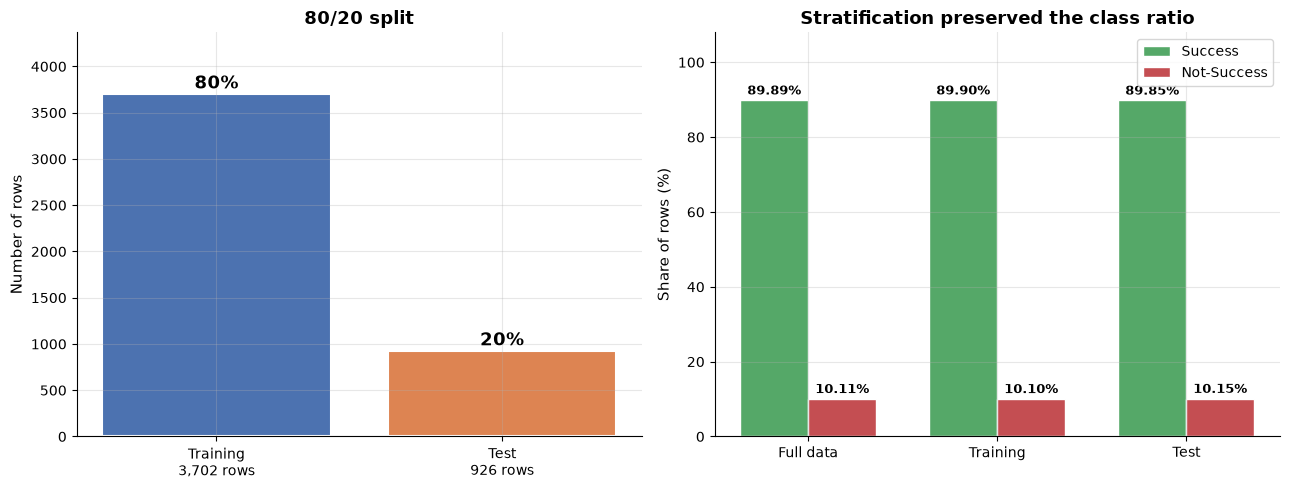

Positive rate - full: 0.8989 | train: 0.8990 | test: 0.8985
The three rates are nearly identical, which is what stratify=y guarantees.
Test set carries 94 failure cases to evaluate on.


In [70]:
# =====================================================================
# H.14 - CHART 1: how the rows were split
# =====================================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Left: row counts ---
sizes = [len(X_train), len(X_test)]
labels = [f"Training\n{sizes[0]:,} rows", f"Test\n{sizes[1]:,} rows"]
bars = axes[0].bar(labels, sizes, color=["#4C72B0", "#DD8452"],
                   edgecolor="white", linewidth=1.5)
for bar, s in zip(bars, sizes):
    axes[0].text(bar.get_x() + bar.get_width()/2, s + 60,
                 f"{s/len(X)*100:.0f}%", ha="center", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Number of rows", fontsize=11)
axes[0].set_title("80/20 split", fontsize=13, fontweight="bold")
axes[0].set_ylim(0, max(sizes) * 1.18)

# --- Right: stratification worked ---
split_names = ["Full data", "Training", "Test"]
pos_rates = [y.mean() * 100, y_train.mean() * 100, y_test.mean() * 100]
minority_rates = [100 - p for p in pos_rates]

x = np.arange(len(split_names))
w = 0.36
axes[1].bar(x - w/2, pos_rates, w, label="Success", color="#55A868", edgecolor="white")
axes[1].bar(x + w/2, minority_rates, w, label="Not-Success", color="#C44E52", edgecolor="white")

for xi, (p, m) in enumerate(zip(pos_rates, minority_rates)):
    axes[1].text(xi - w/2, p + 1.5, f"{p:.2f}%", ha="center", fontsize=9.5, fontweight="bold")
    axes[1].text(xi + w/2, m + 1.5, f"{m:.2f}%", ha="center", fontsize=9.5, fontweight="bold")

axes[1].set_xticks(x)
axes[1].set_xticklabels(split_names)
axes[1].set_ylabel("Share of rows (%)", fontsize=11)
axes[1].set_title("Same success/failure mix after the split", fontsize=13, fontweight="bold")
axes[1].legend()
axes[1].set_ylim(0, 108)

plt.tight_layout()
plt.show()

print(f"Positive rate - full: {y.mean():.4f} | train: {y_train.mean():.4f} | test: {y_test.mean():.4f}")
print("The three rates are nearly identical, which is what stratify=y keeps.")
print("The test set carries", int((1 - y_test).sum()), "failure cases to evaluate on.")

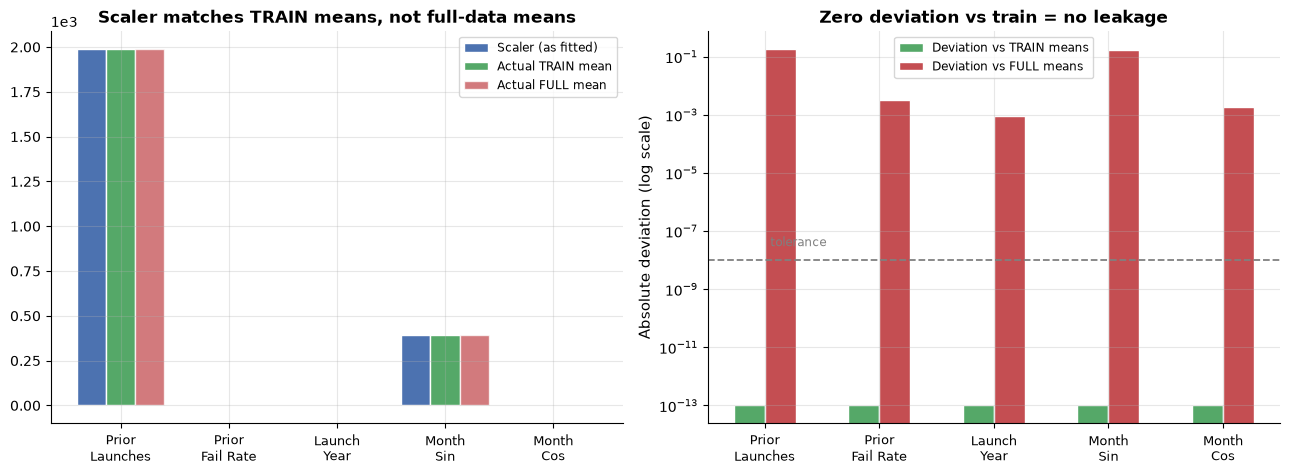

Max deviation from training means : 0.00e+00
The green bars sit at the floor (zero deviation); the red bars do not.

Interpretation: the scaler's stored means reproduce the TRAINING means
to machine precision. If it had seen the test rows, its means would have
matched the full-data means instead - which they do not.


In [71]:
# =====================================================================
# H.15 - CHART 2: evidence that test data was not used to learn preprocessing
# =====================================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Left: scaler means vs train means vs full means ---
x = np.arange(len(numeric_cols))
w = 0.27

axes[0].bar(x - w, comparison["scaler_mean_from_fit"], w,
            label="Scaler (as fitted)", color="#4C72B0", edgecolor="white")
axes[0].bar(x, comparison["actual_TRAIN_mean"], w,
            label="Actual TRAIN mean", color="#55A868", edgecolor="white")
axes[0].bar(x + w, comparison["actual_FULL_mean"], w,
            label="Actual FULL mean", color="#C44E52", edgecolor="white", alpha=0.75)

short = ["Prior\nLaunches", "Prior\nFail Rate", "Launch\nYear", "Month\nSin", "Month\nCos"]
axes[0].set_xticks(x)
axes[0].set_xticklabels(short, fontsize=9)
axes[0].set_title("Scaler learned TRAIN averages, not full-data averages",
                  fontsize=12, fontweight="bold")
axes[0].legend(fontsize=8.5)
axes[0].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))

# --- Right: deviation comparison, log scale ---
dev_train = comparison["diff_vs_train"].values
dev_full = comparison["diff_vs_full"].values

axes[1].bar(x - w/2, np.maximum(dev_train, 1e-13), w,
            label="Deviation vs TRAIN means", color="#55A868", edgecolor="white")
axes[1].bar(x + w/2, np.maximum(dev_full, 1e-13), w,
            label="Deviation vs FULL means", color="#C44E52", edgecolor="white")

axes[1].set_yscale("log")
axes[1].set_xticks(x)
axes[1].set_xticklabels(short, fontsize=9)
axes[1].set_ylabel("Absolute deviation (log scale)", fontsize=11)
axes[1].set_title("Zero deviation vs train = test data not used", fontsize=12, fontweight="bold")
axes[1].legend(fontsize=8.5)
axes[1].axhline(1e-8, ls="--", color="gray", linewidth=1.3)
axes[1].text(0.05, 3e-8, "tolerance", fontsize=8.5, color="gray")

plt.tight_layout()
plt.show()

print(f"Max deviation from training means : {max_vs_train:.2e}")
print("The green bars sit at the floor (zero deviation); the red bars do not.")

print("\nHow to read this: the scaler's stored means reproduce the TRAINING means")
print("to machine precision. If it had seen the test rows, its means would have")
print("matched the full-data means instead - which they do not.")

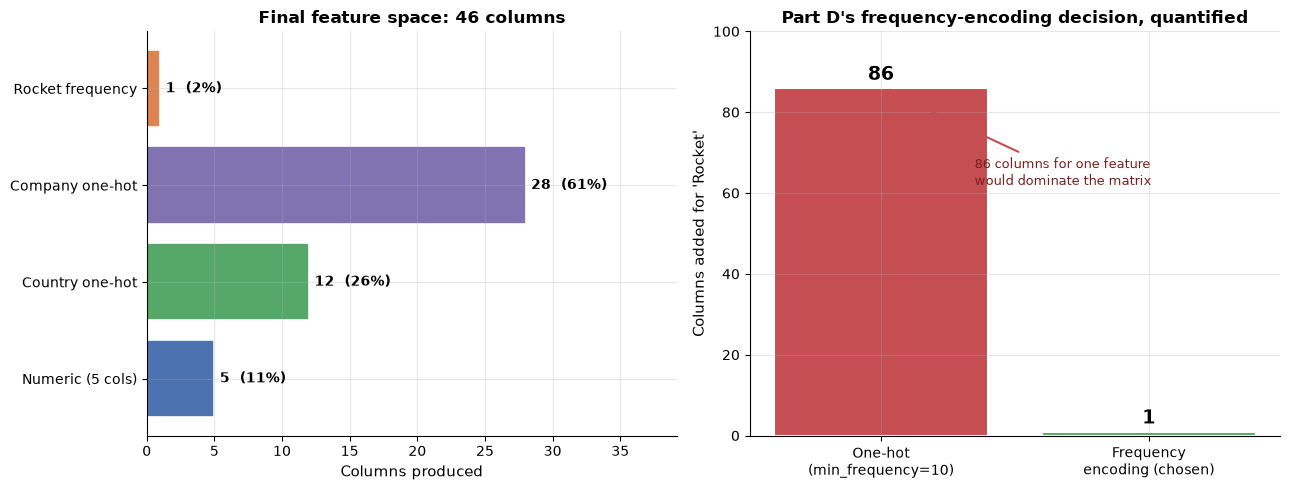

Final matrix: 46 features from 8 source columns.
Rows:features ratio = 100 : 1

Frequency encoding saved 85 columns versus one-hot on 'Rocket' alone.
Part D committed to this; Part H implements it and shows the saving.


In [72]:
# =====================================================================
# H.16 - CHART 3: how 8 input columns became 46 features
# =====================================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Left: contribution of each source column to final width ---
# Count one-hot names per source column using the authoritative name list.
n_country = sum(1 for n in onehot_names if n.startswith("Country_"))
n_company = sum(1 for n in onehot_names if n.startswith("Company_"))

contributions = {
    f"Numeric ({len(numeric_cols)} cols)": len(numeric_cols),
    "Country one-hot": n_country,
    "Company one-hot": n_company,
    "Rocket frequency": 1,
}
total = sum(contributions.values())

bars = axes[0].barh(list(contributions.keys()), list(contributions.values()),
                    color=["#4C72B0", "#55A868", "#8172B2", "#DD8452"],
                    edgecolor="white", linewidth=1.2)
for bar, v in zip(bars, contributions.values()):
    axes[0].text(v + 0.4, bar.get_y() + bar.get_height()/2,
                 f"{v}  ({v/total*100:.0f}%)", va="center", fontsize=10, fontweight="bold")
axes[0].set_xlabel("Columns produced", fontsize=11)
axes[0].set_title(f"Final input columns: {total}", fontsize=12, fontweight="bold")
axes[0].set_xlim(0, max(contributions.values()) * 1.4)

# --- Right: the Rocket encoding decision, side by side ---
rocket_options = {
    "One-hot\n(min_frequency=10)": 86,
    "Frequency\nencoding (chosen)": 1,
}
bars2 = axes[1].bar(list(rocket_options.keys()), list(rocket_options.values()),
                    color=["#C44E52", "#55A868"], edgecolor="white", linewidth=1.5)
for bar, v in zip(bars2, rocket_options.values()):
    axes[1].text(bar.get_x() + bar.get_width()/2, v + 2, str(v),
                 ha="center", fontsize=14, fontweight="bold")
axes[1].set_ylabel("Columns added for 'Rocket'", fontsize=11)
axes[1].set_title("One Rocket frequency column instead of 86",
                  fontsize=12, fontweight="bold")
axes[1].set_ylim(0, 100)
axes[1].annotate("86 columns for one column\nwould dominate the matrix",
                 xy=(0, 86), xytext=(0.35, 62), fontsize=9.5, color="#7A2020",
                 arrowprops=dict(arrowstyle="->", color="#C44E52", lw=1.5))

plt.tight_layout()
plt.show()

print(f"Final matrix: {X_train_t.shape[1]} features from {len(X.columns)} source columns.")
print(f"Rows:features ratio = {len(X) // X_train_t.shape[1]} : 1")
print("\nFrequency encoding saved 85 columns versus one-hot on 'Rocket' alone.")
print("Part D chose this; Part H implements it and shows the saving.")

In [73]:
# =====================================================================
# H.17 - Part H summary
# =====================================================================

part_h_summary = pd.DataFrame([
    {"item": "Split", "value": "80 / 20, same success/failure mix (random_state=42)"},
    {"item": "Training rows", "value": f"{X_train.shape[0]:,}"},
    {"item": "Test rows", "value": f"{X_test.shape[0]:,}"},
    {"item": "Failures in test", "value": f"{int((1 - y_test).sum())}"},
    {"item": "Source input columns", "value": f"{X.shape[1]}"},
    {"item": "Final input columns", "value": f"{X_train_t.shape[1]}"},
    {"item": "Learned from", "value": "X_train ONLY"},
    {"item": "Missing-value handling", "value": "Imputer wired in but idle (X has no missing values)"},
    {"item": "Number scaling", "value": "StandardScaler, learned from training rows"},
    {"item": "Text encoding", "value": "One-hot (Country, Company) + frequency (Rocket)"},
    {"item": "New test names", "value": "18 Rocket, 1 Company -> 'infrequent' / 0.0"},
    {"item": "Leakage checks", "value": "4 numeric checks + LeakageGuard, all PASS"},
    {"item": "Rows kept", "value": f"{len(X):,} (train + test)"},
]).set_index("item")

display(part_h_summary)

print("Files saved for the next part: X_train.npy, X_test.npy, y_train.npy, y_test.npy, feature_names.txt")


,value
item,
Split ratio,"80 / 20, stratified (random_state=42)"
Training rows,"3,702"
Test rows,926
Minority rows in test,94 failures
Source features,8
Transformed features,46
Fitted on,X_train ONLY
Imputation,"Wired in, idle (X has no missing values)"
Scaling,"StandardScaler, fitted on train"


Artefacts saved: X_train.npy, X_test.npy, y_train.npy, y_test.npy, feature_names.txt


### Part I — Preprocessing Summary Table

This part gathers the whole preprocessing story in one place. No new calculation
happens here — every number below was already measured in Parts A–H.

**How to read the tables**

| Column | Meaning |
| :--- | :--- |
| Issue / Need | The data problem that had to be solved |
| Action | What we actually did |
| Reason | Why that action was correct |
| Stage | Which part did it, and how far it went |

**Stage labels used below**

| Label | Meaning |
| :--- | :--- |
| Applied | The change is already in the data |
| Fitted on train | A rule was learned from the training rows only |
| Checked | A result was verified and passed |
| Planned → used | Part D chose the method; Part H applied it |

---

#### I.1 — Cleaning the data (Part C)

| Issue / Need | Action | Reason | Stage |
| :--- | :--- | :--- | :--- |
| Duplicate launch rows | Removed 1 exact duplicate and 1 documented business duplicate (4,630 → 4,628 rows) | The same launch must not be counted twice | Applied — C |
| Real co-launches could be deleted by mistake | Kept the 8 verified co-launch rows (4 pairs) | They are separate launches on the same day | Applied — C |
| The raw file could be damaged | Worked on a copy; the raw CSV was never overwritten | The original stays available for checking and re-running | Applied — C |
| Date stored as text | Parsed `Date` into a real datetime (0 unparseable) | Dates must be sortable and comparable | Applied — C |
| Price stored as text | Parsed the non-null `Price` values into numbers | Numbers are needed for arithmetic | Applied — C |
| Price missing 72.68% (3,365 of 4,630 rows) | Dropped the `Price` column | Filling three quarters of a column would invent data | Applied — C |
| Location was one long text field | Extracted `Country` (22 values), then dropped `Location` | Makes geography usable as an input | Applied — C |
| Time missing 2.74% (127 rows) | Left the missing values untouched; `Time` is not used as an input | No value is invented for a column with no clear signal | Applied — C |

#### I.2 — Features built and transformed (Parts D–E)

| Issue / Need | Action | Reason | Stage |
| :--- | :--- | :--- | :--- |
| Dates needed a numeric form | Created `Launch_Year` (1957–2022) | Captures the technology era | Planned → used |
| Months wrap around the calendar | Created `Month_Sin` and `Month_Cos` | December and January become neighbours | Planned → used |
| A company label alone shows no experience | Created `Company_Prior_Launches` from earlier missions only | Counts the operator's history before this launch | Applied — E; used in G/H |
| Experience needs a quality measure | Created `Company_Prior_Failure_Rate` from earlier missions only | Separates an operator's past failures from the current one | Applied — E; used in G/H |
| A near-duplicate experience column | Did not keep `Company_Prior_Failures` (0.952 correlation with prior launches) | It would add almost the same information | Applied — E |
| Text columns cannot be used directly | One-hot encoded `Company` and `Country` into 40 collapsed columns | Turns names into 0/1 columns; rare names share one bucket | Planned → used |
| `Rocket` had 370 names | Frequency encoded `Rocket` into 1 column (351 names learned from training) | 86 one-hot columns would dominate the matrix | Planned → used |
| Numeric columns had different scales | Used `StandardScaler` instead of min-max normalization | Puts numeric inputs on a comparable scale | Planned → used |
| Missing numeric values | Added a median imputer (wired in but idle, because `X` has no missing values) | Ready if a future dataset has gaps | Planned → used |

#### I.3 — Separation, split, and safety (Parts F–H)

| Issue / Need | Action | Reason | Stage |
| :--- | :--- | :--- | :--- |
| Some columns reveal the answer or the future | Left out `RocketStatus`, `Mission`, `Time`, `Date`, `MissionStatus`, `_is_fail`, `Company_Prior_Failures` | Every input must be knowable before the launch | Applied — F/G |
| Features and answer must stay apart | Built 8 input columns (`X`) and one binary answer (`y`) | Keeps the answer out of the inputs | Applied — G |
| The model needs rows it has never seen | Stratified 80/20 split with random_state=42: 3,702 training rows / 926 test rows | Keeps the same success/failure mix in both groups | Applied — H |
| Test data could influence preprocessing | Fitted the imputer, scaler, and encoders on `X_train` only, then applied them to `X_test` | Prevents test information from leaking into learned rules | Fitted on train — H |
| Transformations might leak or misalign | Ran 4 numeric checks plus `LeakageGuard`; all passed | Proves the scaler, encoder, and frequency map came from training only | Checked — H |
| Outputs must be reusable | Saved `X_train.npy`, `X_test.npy`, `y_train.npy`, `y_test.npy`, and `feature_names.txt` | Prepares the next modelling part | Checked — H |

**Evidence from the checks**

| Check | Result |
| :--- | :--- |
| Scaler means vs training means | Match exactly (deviation 0.0) |
| Training / test success rate | 0.8990 / 0.8985 (kept close by stratification) |
| Failures in the test rows | 94 |
| One-hot categories seen only in test | 1 (`Company`) → rare bucket |
| Rocket names seen only in test | 18 → mapped to 0.0 |
| NaNs in the transformed matrices | 0 in both |
| Rows preserved end-to-end | 4,628 = 3,702 + 926 |
| Leakage guards | All PASS |

#### I.4 — Final shape

| Stage | Rows | Columns |
| :--- | ---: | ---: |
| Raw data (Part A) | 4,630 | 9 |
| Cleaned data (Part C) | 4,628 | 8 |
| After feature building (Parts D–E) | 4,628 | 15 |
| Inputs `X` (Part G) | 4,628 | 8 |
| Answer `y` (Part G) | 4,628 | 1 |
| Training rows (Part H) | 3,702 | 8 |
| Test rows (Part H) | 926 | 8 |
| Final training matrix | 3,702 | 46 |
| Final test matrix | 926 | 46 |

**Where the 46 final input columns come from**

| Source | Columns |
| :--- | ---: |
| Numeric features (`Launch_Year`, `Month_Sin`, `Month_Cos`, `Company_Prior_Launches`, `Company_Prior_Failure_Rate`) | 5 |
| One-hot (`Country`, `Company`) | 40 |
| Frequency encoded (`Rocket`) | 1 |
| **Total** | **46** |

**Saved files**

| File | Shape / content |
| :--- | :--- |
| `X_train.npy` | 3,702 × 46 |
| `X_test.npy` | 926 × 46 |
| `y_train.npy` | 3,702 labels |
| `y_test.npy` | 926 labels |
| `feature_names.txt` | 46 feature names |

#### I.5 — Model fitting: what was done and what was not

| Question | Answer |
| :--- | :--- |
| Was the preprocessing fitted? | Yes. `full_pipeline.fit(X_train, y_train)` learned the median imputer, `StandardScaler`, one-hot vocabulary, and `Rocket` frequency map from training rows only. |
| Were any models compared? | Yes, for diagnostics only: K-Means with and without scaling (Part D), a decision tree on raw vs standardized inputs (Part D), and a decision tree on honest vs leaky features (Part E). These were comparisons, not the final model. |
| Was a final predictive model trained and reported? | No. Phase 1 ends with prepared, leak-free train and test matrices. |
| What happens next? | A later phase can train, tune, and report the chosen model using the saved arrays. |

**The main result in one line:** every preprocessing rule was learned from the training rows only, the checks confirm it, and no answer information reached the inputs.
